#  Klasifikasi dan Regresi Lokalisasi Indoor Berbasis RSSI Wi-Fi

Tim R&D PT. Sinyal Nusantara sedang mengembangkan layanan navigasi di dalam gedung untuk sebuah kampus besar. GPS tidak andal di dalam ruangan, sehingga posisi pengguna harus diperkirakan dari kekuatan sinyal (RSSI) access point Wi-Fi yang tertangkap ponsel. 
Ibu Laras, manajer produk, ingin tahu apakah sidik jari (fingerprint) RSSI cukup untuk menebak gedung dan lantai pengguna, sekaligus memperkirakan koordinatnya dengan galat sekecil mungkin.

## PROSES 1 — EDA DAN DATA PREPROCESSING

### 1. Import Library

Mengimpor library untuk manipulasi data, visualisasi, statistik, dan preprocessing.

In [4]:
# Cell 1: Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

print("Library berhasil diimpor.")

Library berhasil diimpor.


### 2. Load dataset
Tujuan: Membaca dataset training dan validation yang sudah disediakan.

In [5]:
train_path = "data/trainingData.csv"
validation_path = "data/validationData.csv"

df_train = pd.read_csv(train_path)
df_validation = pd.read_csv(validation_path)

print("Training Dataset:", df_train.shape)
print("Validation Dataset:", df_validation.shape)

df_train.head()

Training Dataset: (19937, 529)
Validation Dataset: (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


### 3. Identifikasi kolom
Tujuan: Memisahkan fitur RSSI, target, dan metadata.

Disini tidak boleh menggunakan USERID, PHONEID, dan TIMESTAMP sebagai fitur prediksi posisi karena dapat menyebabkan model mempelajari identitas perangkat atau pola waktu, bukan fingerprint Wi-Fi.

Catatan: SPACEID dan RELATIVEPOSITION juga tidak kita gunakan sebagai fitur prediksi utama. Keduanya berpotensi memberikan informasi lokasi secara langsung.

In [6]:
# Fitur RSSI
rssi_features = [
    col for col in df_train.columns
    if col.startswith("WAP")
]

# Target klasifikasi
classification_targets = [
    "BUILDINGID",
    "FLOOR"
]

# Target regresi
regression_targets = [
    "LONGITUDE",
    "LATITUDE"
]

# Metadata
metadata_features = [
    "SPACEID",
    "RELATIVEPOSITION",
    "USERID",
    "PHONEID",
    "TIMESTAMP"
]

print("Jumlah fitur RSSI:", len(rssi_features))
print("Target klasifikasi:", classification_targets)
print("Target regresi:", regression_targets)
print("Metadata:", metadata_features)

assert len(rssi_features) == 520

Jumlah fitur RSSI: 520
Target klasifikasi: ['BUILDINGID', 'FLOOR']
Target regresi: ['LONGITUDE', 'LATITUDE']
Metadata: ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


### 4. Pemeriksaan struktur dataset
Tujuan: Memastikan kedua dataset memiliki struktur kolom yang konsisten dan memahami tipe datanya.

Interpretasi:
- Pastikan semua fitur RSSI memiliki tipe numerik.
- Pastikan target tersedia di kedua dataset.
- Pastikan tidak terdapat perbedaan nama kolom.
- Jika terdapat tipe data tidak sesuai, lakukan konversi sebelum preprocessing.

In [7]:
# Pemeriksaan Struktur Training Dataset

print("=== TRAINING DATA ===")
df_train.info()

print("\n=== TIPE DATA ===")
display(df_train.dtypes.value_counts())

print("\n=== JUMLAH KOLOM ===")
print("Total kolom:", len(df_train.columns))

print("\n=== FITUR RSSI ===")
print("Jumlah fitur RSSI:", len(rssi_features))

print("\n=== TARGET ===")

target_columns = (
    classification_targets + regression_targets
)

display(df_train[target_columns].dtypes)

print("\n=== MISSING TARGET ===")
display(df_train[target_columns].isnull().sum())

=== TRAINING DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 19937 entries, 0 to 19936
Columns: 529 entries, WAP001 to TIMESTAMP
dtypes: float64(2), int64(527)
memory usage: 80.5 MB

=== TIPE DATA ===


int64      527
float64      2
Name: count, dtype: int64


=== JUMLAH KOLOM ===
Total kolom: 529

=== FITUR RSSI ===
Jumlah fitur RSSI: 520

=== TARGET ===


BUILDINGID      int64
FLOOR           int64
LONGITUDE     float64
LATITUDE      float64
dtype: object


=== MISSING TARGET ===


BUILDINGID    0
FLOOR         0
LONGITUDE     0
LATITUDE      0
dtype: int64

### 5. Pemeriksaan duplikasi
Tujuan: Mengidentifikasi baris yang memiliki seluruh nilai sama.

In [8]:
# Pemeriksaan Duplikasi Training

duplicate_train = df_train.duplicated().sum()

duplicate_percentage = (
    duplicate_train / len(df_train) * 100
)

print("Jumlah duplikasi:", duplicate_train)

print(
    "Persentase duplikasi:",
    round(duplicate_percentage, 2),
    "%"
)

Jumlah duplikasi: 637
Persentase duplikasi: 3.2 %


### 6. Missing value aktual
Tujuan: Memeriksa apakah terdapat nilai kosong dalam format NaN.

In [9]:
# Missing Value Analysis

missing_train = df_train.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_train,
    "Missing Percentage": (
        missing_train / len(df_train) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
]

print(
    "Total missing value:",
    missing_train.sum()
)

display(missing_summary)

Total missing value: 0


,Missing Count,Missing Percentage


### 7. Analisis nilai RSSI +100
Tujuan: Mengukur jumlah dan persentase WAP yang tidak terdeteksi.

In [10]:
rssi_train = df_train[rssi_features]

sentinel_count = (rssi_train == 100).sum()
sentinel_percentage = (rssi_train == 100).mean() * 100

sentinel_summary = pd.DataFrame({
    "WAP": rssi_features,
    "Sentinel Count": sentinel_count.values,
    "Sentinel Percentage": sentinel_percentage.values
})

sentinel_summary = sentinel_summary.sort_values(
    by="Sentinel Percentage",
    ascending=False
)

display(sentinel_summary.head(15))

print(
    "Rata-rata persentase sentinel:",
    round(sentinel_percentage.mean(), 2),
    "%"
)

,WAP,Sentinel Count,Sentinel Percentage
519,WAP520,19937,100.0
496,WAP497,19937,100.0
490,WAP491,19937,100.0
486,WAP487,19937,100.0
487,WAP488,19937,100.0
484,WAP485,19937,100.0
481,WAP482,19937,100.0
246,WAP247,19937,100.0
450,WAP451,19937,100.0
457,WAP458,19937,100.0


Rata-rata persentase sentinel: 96.54 %


### 8. Visualisasi Missing RSSI

Visualisasi ini membantu mengetahui apakah sebagian besar access point memiliki tingkat deteksi yang sangat rendah.
informasi ini digunakan untuk menentukan strategi seleksi fitur.

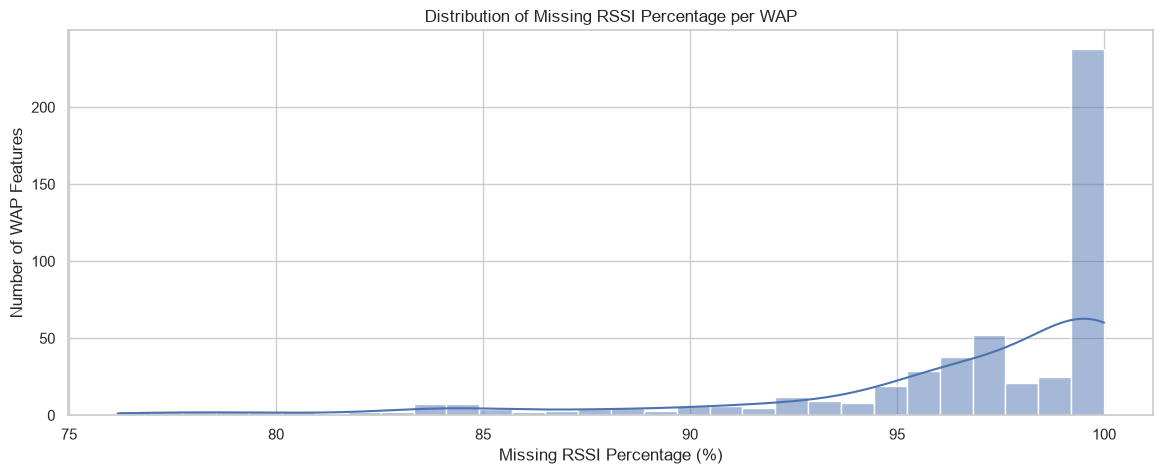

In [11]:
plt.figure(figsize=(14, 5))

sns.histplot(
    sentinel_percentage,
    bins=30,
    kde=True
)

plt.title("Distribution of Missing RSSI Percentage per WAP")
plt.xlabel("Missing RSSI Percentage (%)")
plt.ylabel("Number of WAP Features")

plt.show()

### 9. Identifikasi WAP konstan
Tujuan: Menemukan fitur yang tidak memiliki variasi informasi.

pada bagian ini akan membandingkan dua skenario:
- Full features: seluruh 520 fitur RSSI.
- Reduced features: fitur konstan dihapus.

Penghapusan fitur konstan dilakukan berdasarkan training saja.

In [12]:
constant_features = [
    col for col in rssi_features
    if df_train[col].nunique() == 1
]

print("Jumlah fitur konstan:", len(constant_features))
print("Daftar fitur konstan:")
print(constant_features)

print(
    "Persentase fitur konstan:",
    round(len(constant_features) / len(rssi_features) * 100, 2),
    "%"
)

Jumlah fitur konstan: 55
Daftar fitur konstan:
['WAP003', 'WAP004', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP152', 'WAP158', 'WAP159', 'WAP160', 'WAP215', 'WAP217', 'WAP226', 'WAP227', 'WAP238', 'WAP239', 'WAP240', 'WAP241', 'WAP242', 'WAP243', 'WAP244', 'WAP245', 'WAP246', 'WAP247', 'WAP254', 'WAP293', 'WAP296', 'WAP301', 'WAP303', 'WAP304', 'WAP307', 'WAP333', 'WAP349', 'WAP353', 'WAP360', 'WAP365', 'WAP416', 'WAP419', 'WAP423', 'WAP429', 'WAP433', 'WAP438', 'WAP441', 'WAP442', 'WAP444', 'WAP445', 'WAP451', 'WAP458', 'WAP482', 'WAP485', 'WAP487', 'WAP488', 'WAP491', 'WAP497', 'WAP520']
Persentase fitur konstan: 10.58 %


### 10. Distribusi BUILDINGID
Tujuan: Mengetahui jumlah sampel setiap kelas gedung.

BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64


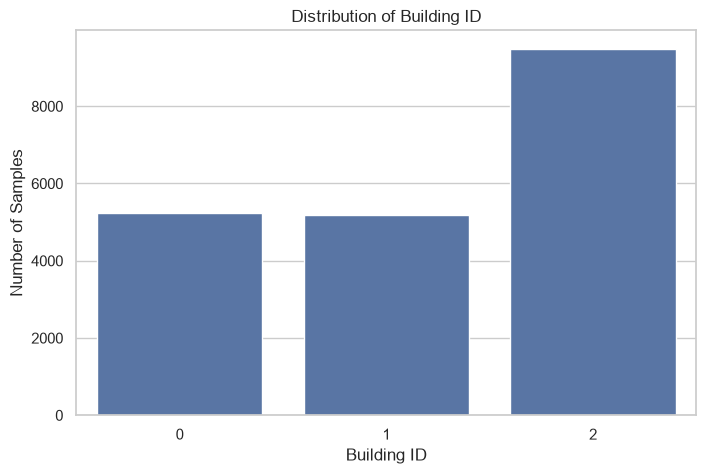

In [13]:
building_counts = df_train["BUILDINGID"].value_counts().sort_index()

print(building_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    order=sorted(df_train["BUILDINGID"].unique())
)

plt.title("Distribution of Building ID")
plt.xlabel("Building ID")
plt.ylabel("Number of Samples")

plt.show()

### 11. Distribusi FLOOR
Tujuan: Memeriksa distribusi kelas lantai.

FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64


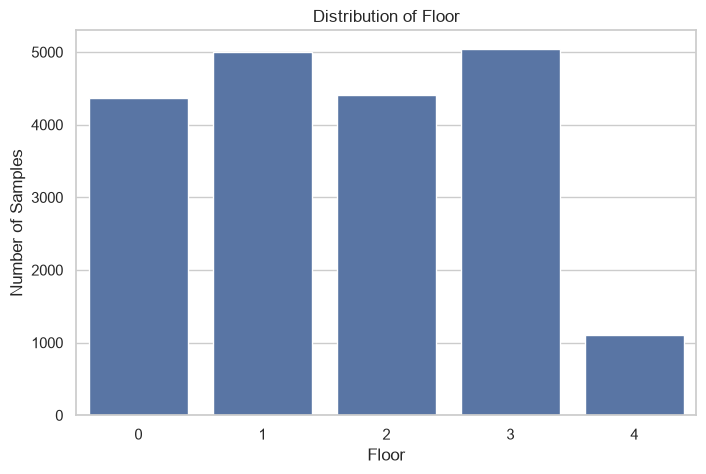

In [14]:
floor_counts = df_train["FLOOR"].value_counts().sort_index()

print(floor_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="FLOOR",
    order=sorted(df_train["FLOOR"].unique())
)

plt.title("Distribution of Floor")
plt.xlabel("Floor")
plt.ylabel("Number of Samples")

plt.show()

### 12. Statistik deskriptif RSSI
Tujuan: Mengetahui karakteristik nilai RSSI, termasuk nilai minimum, maksimum, rata-rata, median, dan standar deviasi.

Penting: nilai +100 masih dianggap sebagai sentinel, sehingga kita keluarkan sementara dari statistik RSSI aktual.

Interpretasi:
- mean: rata-rata kekuatan sinyal.
- std: variasi kekuatan sinyal.
- min dan max: rentang nilai RSSI yang terdeteksi.
- 50%: median RSSI.

Nilai count menunjukkan jumlah observasi RSSI yang benar-benar terdeteksi.

In [15]:
rssi_clean_eda = df_train[rssi_features].replace(100, np.nan)

rssi_statistics = rssi_clean_eda.describe().T


rssi_statistics[
     ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)


,count,mean,std,min,25%,50%,75%,max
WAP001,18.0,-95.33,1.14,-97.0,-96.0,-96.0,-94.25,-93.0
WAP002,19.0,-87.89,2.05,-90.0,-90.0,-86.0,-86.00,-86.0
WAP003,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP004,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP005,40.0,-92.52,2.15,-97.0,-94.0,-92.0,-91.75,-89.0
...,...,...,...,...,...,...,...,...
WAP516,3038.0,-72.56,14.61,-101.0,-84.0,-74.0,-63.00,0.0
WAP517,4543.0,-76.02,12.06,-101.0,-85.0,-77.0,-70.00,0.0
WAP518,22.0,-91.55,3.73,-97.0,-95.0,-91.0,-88.00,-87.0
WAP519,3.0,-96.00,1.73,-97.0,-97.0,-97.0,-95.50,-94.0


### 13. Distribusi nilai RSSI
Tujuan: Melihat pola distribusi kekuatan sinyal Wi-Fi.

Interpretasi:
Distribusi ini membantu mengetahui rentang RSSI yang paling sering diterima perangkat.
Semakin mendekati 0 dBm, sinyal semakin kuat. Semakin negatif nilainya, sinyal semakin lemah.

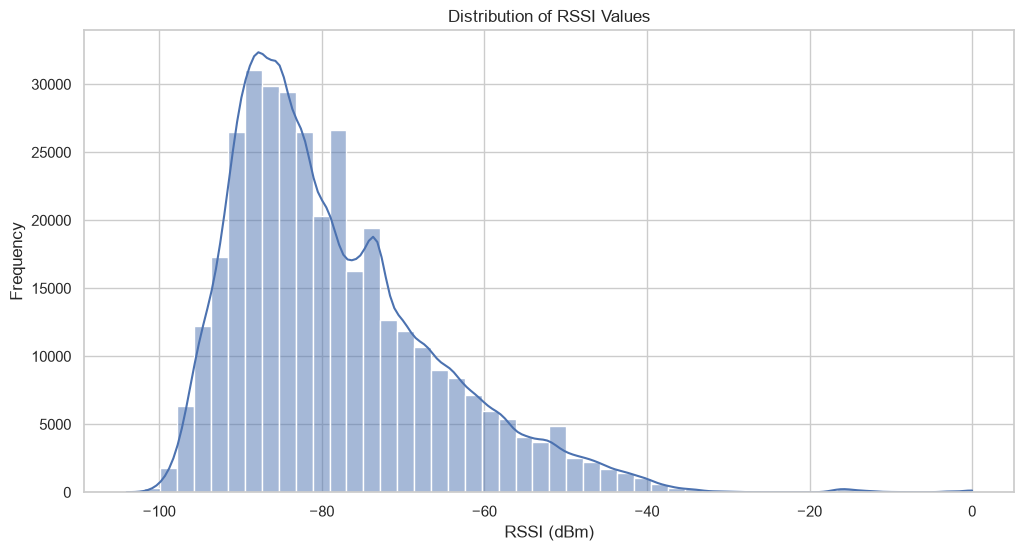

In [16]:
rssi_values = rssi_clean_eda.values.flatten()
rssi_values = rssi_values[~np.isnan(rssi_values)]

plt.figure(figsize=(12, 6))

sns.histplot(
    rssi_values,
    bins=50,
    kde=True
)

plt.title("Distribution of RSSI Values")
plt.xlabel("RSSI (dBm)")
plt.ylabel("Frequency")

plt.show()

### 14. Distribusi RSSI berdasarkan gedung
Tujuan: Mengidentifikasi apakah karakteristik fingerprint RSSI berbeda antar gedung.

Interpretasi:
Apabila distribusi RSSI berbeda antar gedung, fingerprint Wi-Fi berpotensi memberikan informasi yang berguna untuk klasifikasi gedung.

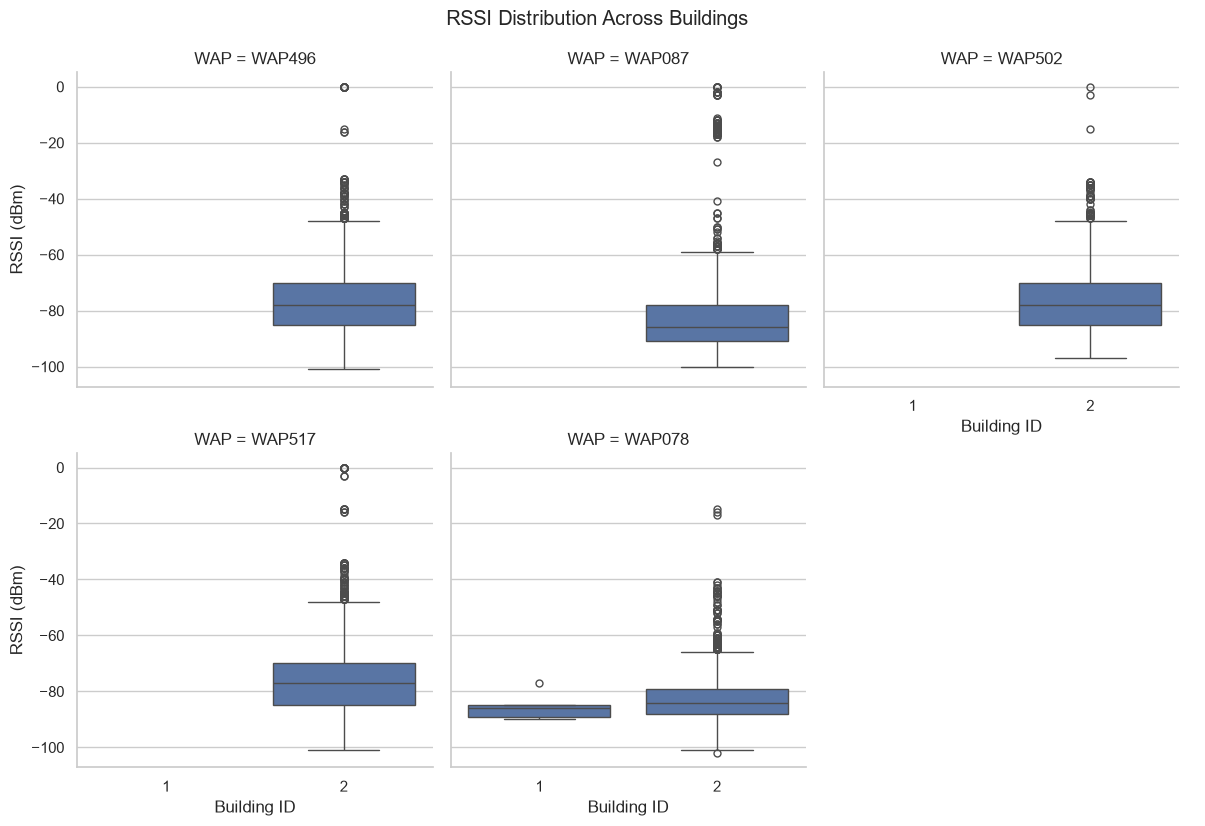

In [17]:
sample_size = min(5, len(rssi_features))

selected_waps = (
    df_train[rssi_features]
    .replace(100, np.nan)
    .notna()
    .sum()
    .sort_values(ascending=False)
    .head(sample_size)
    .index
)

plot_data = df_train[
    list(selected_waps) + ["BUILDINGID"]
].melt(
    id_vars="BUILDINGID",
    var_name="WAP",
    value_name="RSSI"
)

plot_data = plot_data[plot_data["RSSI"] != 100]

g = sns.catplot(
    data=plot_data,
    x="BUILDINGID",
    y="RSSI",
    col="WAP",
    kind="box",
    col_wrap=3,
    height=4,
    sharey=True
)

g.set_axis_labels("Building ID", "RSSI (dBm)")
g.fig.suptitle(
    "RSSI Distribution Across Buildings",
    y=1.03
)

plt.show()

### 15. Deteksi outlier menggunakan IQR
Tujuan: Mengidentifikasi nilai RSSI ekstrem menggunakan metode Interquartile Range (IQR).

Rumus:

IQR = Q3 - Q1

Lower = Q1 - 1,5(IQR)

Upper = Q3 + 1,5(IQR)

ini berfungsi untuk menghitung outlier hanya dari RSSI yang terdeteksi, bukan sentinel +100.

Dalam konteks RSSI, nilai ekstrem dapat menjadi karakteristik fingerprint suatu lokasi. Dalam hal ini harus membedakan anomali pengukuran dengan variasi sinyal yang memang valid.

In [18]:
outlier_results = []

for col in rssi_features:

    values = df_train[col]
    values = values[values != 100]

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_results.append({
        "WAP": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers,
        "Outlier Percentage": outliers / len(values) * 100
    })

outlier_df = pd.DataFrame(outlier_results)


outlier_df.sort_values(
    "Outlier Percentage",
     ascending=False
 ).head(20).round(2)


,WAP,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
419,WAP468,-95.00,-95.0,0.00,-95.00,-95.00,4,44.44
310,WAP343,-88.00,-88.0,0.00,-88.00,-88.00,3,33.33
204,WAP216,-85.00,-82.5,2.50,-88.75,-78.75,3,30.00
299,WAP331,-88.75,-88.0,0.75,-89.88,-86.88,3,25.00
385,WAP425,-91.25,-91.0,0.25,-91.62,-90.62,2,25.00
183,WAP194,-63.25,-51.5,11.75,-80.88,-33.88,2,25.00
362,WAP399,-85.00,-84.0,1.00,-86.50,-82.50,12,23.53
277,WAP309,-87.00,-87.0,0.00,-87.00,-87.00,2,22.22
152,WAP163,-89.00,-88.0,1.00,-90.50,-86.50,5,20.83
422,WAP471,-91.00,-91.0,0.00,-91.00,-91.00,1,20.00


### 16. Visualisasi outlier



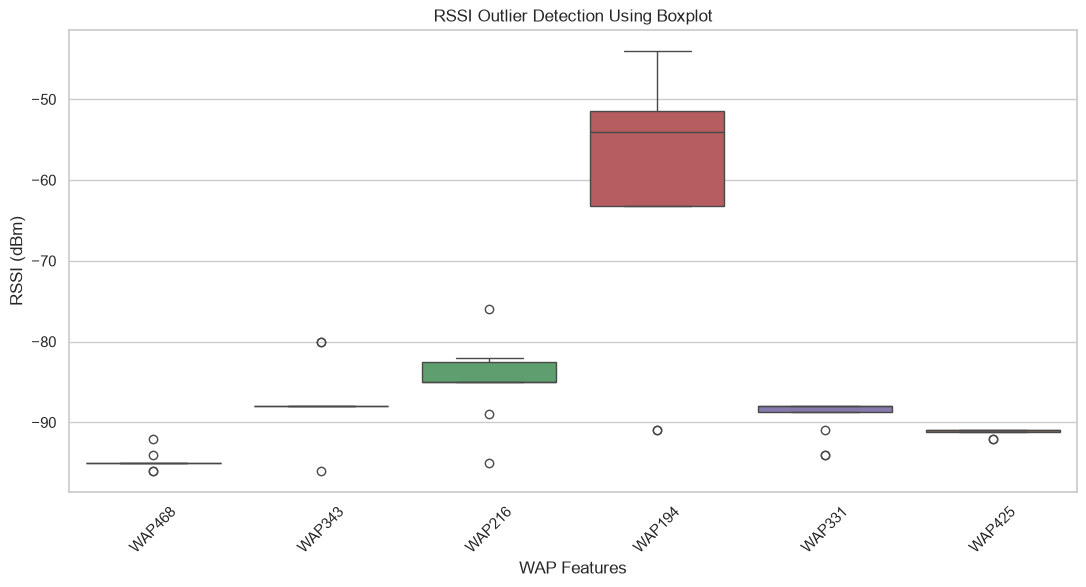

In [19]:
selected_outlier_waps = outlier_df.nlargest(
    6,
    "Outlier Percentage"
)["WAP"].tolist()

boxplot_data = df_train[selected_outlier_waps].replace(
    100,
    np.nan
)

plt.figure(figsize=(13, 6))

sns.boxplot(data=boxplot_data)

plt.title("RSSI Outlier Detection Using Boxplot")
plt.xlabel("WAP Features")
plt.ylabel("RSSI (dBm)")

plt.xticks(rotation=45)
plt.show()

### 17. Korelasi antarfitur RSSI
Tujuan: Mengetahui hubungan antar-WAP. Fitur yang memiliki korelasi tinggi mungkin membawa informasi yang serupa.

Untuk menjaga visualisasi tetap terbaca, gunakan 30 WAP dengan variasi terbesar setelah sentinel diubah menjadi NaN.

Interpretasi:
- Korelasi mendekati +1: hubungan positif kuat.
- Korelasi mendekati -1: hubungan negatif kuat.
- Korelasi mendekati 0: hubungan linear lemah.

Korelasi tinggi tidak otomatis berarti salah satu fitur harus dihapus.

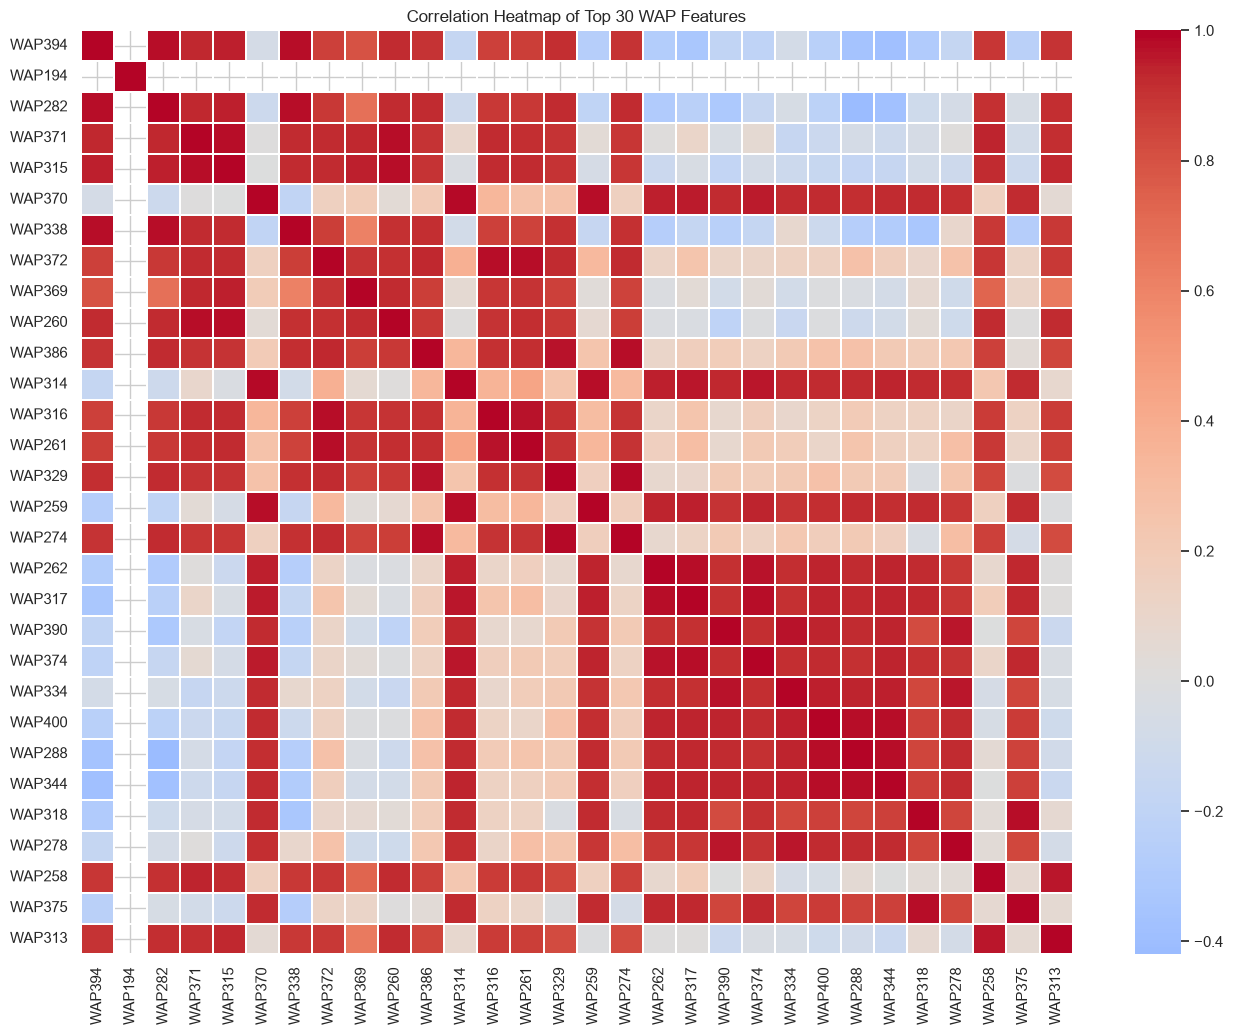

In [20]:
rssi_variance = (
    rssi_clean_eda
    .var()
    .sort_values(ascending=False)
)

top_30_waps = rssi_variance.head(30).index

correlation_matrix = (
    rssi_clean_eda[top_30_waps]
    .corr()
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Top 30 WAP Features")
plt.show()

### 18. Korelasi fitur dengan koordinat
Tujuan: Mengevaluasi hubungan linear RSSI dengan koordinat LONGITUDE dan LATITUDE.

Catatan: Korelasi Pearson hanya mengukur hubungan linear. Hubungan spasial yang lebih kompleks belum tentu terlihat melalui korelasi ini.

,LONGITUDE,LATITUDE
WAP262,0.439177,-0.489087
WAP344,0.415378,-0.581264
WAP288,0.412118,-0.473359
WAP374,0.406807,-0.471106
WAP400,0.394403,-0.506262
WAP317,0.373258,-0.439291
WAP334,0.248633,-0.563733
WAP314,0.221638,-0.479916
WAP390,0.198862,-0.568921
WAP375,0.180140,-0.223652


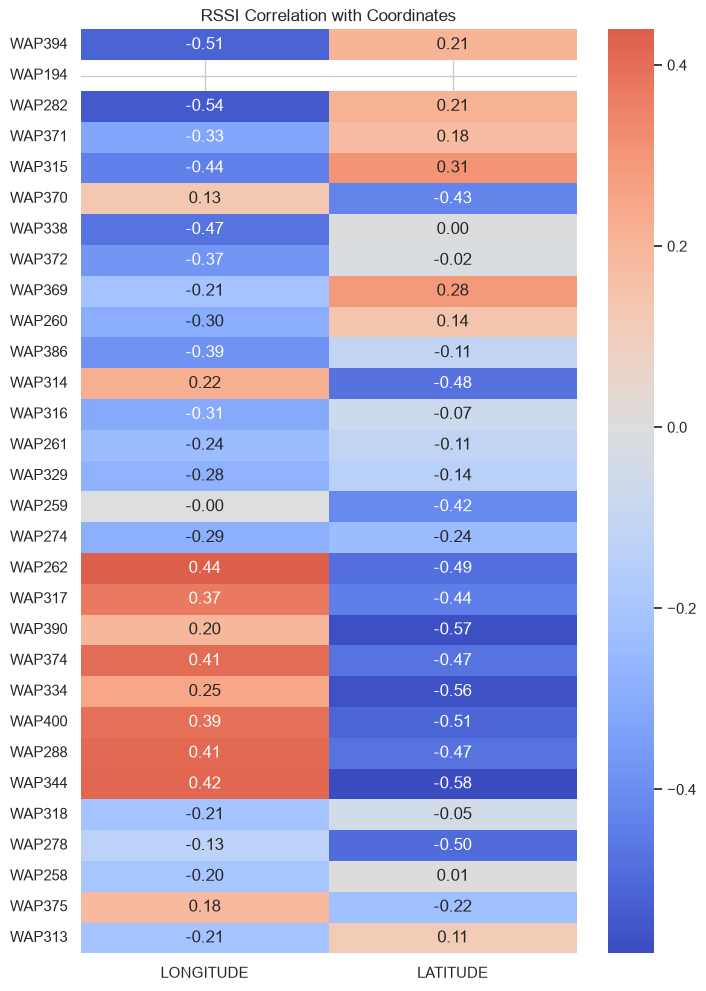

In [21]:
correlation_data = df_train[
    list(top_30_waps) + [
        "LONGITUDE",
        "LATITUDE"
    ]
].replace(100, np.nan)

target_correlation = (
    correlation_data.corr()[["LONGITUDE", "LATITUDE"]]
    .iloc[:-2]
)

display(
    target_correlation
    .sort_values("LONGITUDE", ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 12))

sns.heatmap(
    target_correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("RSSI Correlation with Coordinates")
plt.show()

### 19. Distribusi koordinat LONGITUDE dan LATITUDE
Tujuan: Memahami sebaran posisi pengguna berdasarkan koordinat geografis.

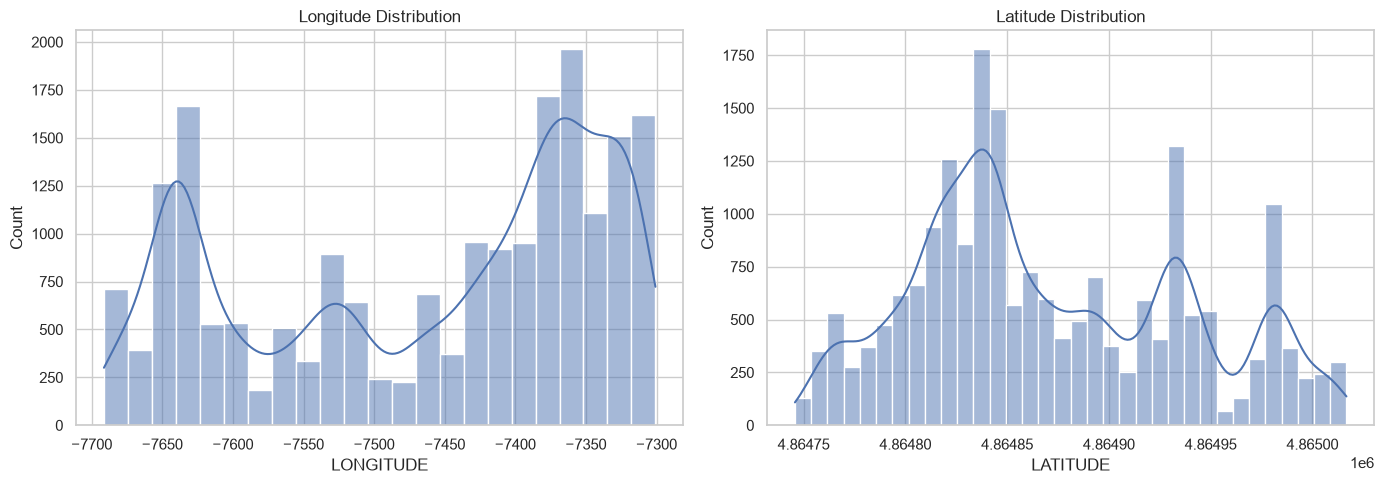

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_train["LONGITUDE"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Longitude Distribution")

sns.histplot(
    df_train["LATITUDE"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Latitude Distribution")

plt.tight_layout()
plt.show()

### 20. Visualisasi sebaran lokasi

Interpretasi:

Visualisasi ini membantu melihat apakah koordinat antar gedung membentuk kelompok spasial yang berbeda.

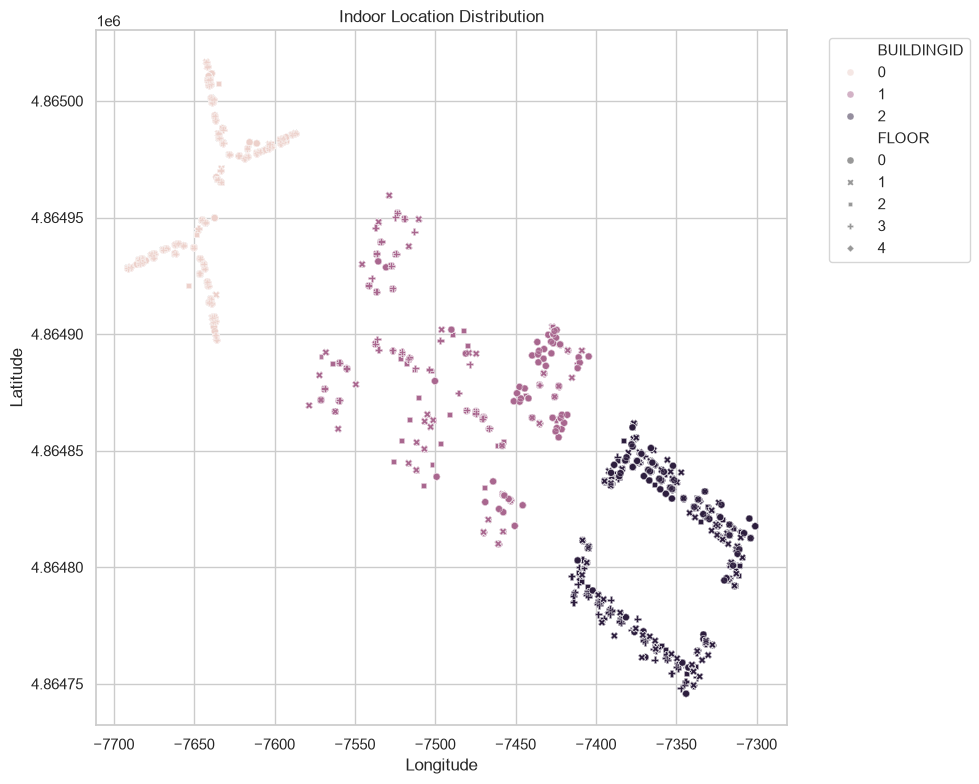

In [23]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df_train,
    x="LONGITUDE",
    y="LATITUDE",
    hue="BUILDINGID",
    style="FLOOR",
    alpha=0.5,
    s=25
)

plt.title("Indoor Location Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 21. Membuat salinan dataset
Tujuan: Mempertahankan dataset asli agar tidak berubah selama proses preprocessing.

In [24]:
X_train_raw = df_train[rssi_features].copy()

y_train = df_train[
    ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
].copy()

print("Training features:", X_train_raw.shape)
print("Training targets:", y_train.shape)

print("\nJumlah fitur RSSI:", X_train_raw.shape[1])
print("Jumlah data training:", X_train_raw.shape[0])

print("\nDataset asli tetap dipertahankan.")

Training features: (19937, 520)
Training targets: (19937, 4)

Jumlah fitur RSSI: 520
Jumlah data training: 19937

Dataset asli tetap dipertahankan.


### 22. Metode 1: Sentinel replacement (-105 dBm)
Tujuan: Mengganti nilai +100 dengan -105 dBm.

Alasannya:
- RSSI yang tidak terdeteksi bukan berarti sinyal kuat.
- Nilai -105 dBm berada sedikit di bawah batas minimum RSSI yang tercatat.
- Metode ini mempertahankan informasi bahwa WAP tidak terdeteksi melalui nilai yang sangat rendah.

Catatan: Metode ini tidak memerlukan proses fitting. Namun, -105 merupakan keputusan domain yang perlu diuji dampaknya terhadap performa model.

In [25]:
def replace_sentinel(X):
    """
    Mengganti nilai sentinel +100 menjadi -105 dBm.
    Fungsi ini tidak melakukan fitting parameter.
    """

    return X.replace(100, -105)

### 23. Metode 2: Sentinel menjadi NaN dan imputasi median
Tujuan: Mengganti nilai tidak terdeteksi menjadi NaN, lalu mengisi nilai tersebut menggunakan median setiap WAP.

Median dihitung hanya dari data training pada setiap skenario pembagian data.

Data test internal menggunakan median yang diperoleh dari data training terkait melalui transformasi pipeline.

Pada evaluasi akhir, validation dataset menggunakan parameter imputasi yang dipelajari ketika model terbaik dilatih ulang menggunakan seluruh training dataset.

In [26]:
def convert_sentinel_to_nan(X):
    """
    Mengubah nilai sentinel +100 menjadi NaN.
    Imputasi median akan dilakukan di dalam pipeline.
    """

    return X.replace(100, np.nan)

### 24. Membandingkan kedua metode
Tujuan: Membandingkan dua strategi penanganan nilai RSSI yang tidak terdeteksi, yaitu Sentinel Replacement (-105 dBm) dan Median Imputation.

Kedua metode akan diuji menggunakan skenario pembagian data 80:20 dan 70:30.

Metode evaluasi:
1. Membandingkan karakteristik statistik hasil preprocessing.
2. Membandingkan performa model klasifikasi dan regresi.
3. Menggunakan metrik evaluasi yang sesuai dengan masing-masing tugas.

Perbandingan statistik deskriptif dilakukan pada data training setelah penanganan sentinel, tetapi sebelum scaling. Statistik yang dibandingkan meliputi mean, standar deviasi, nilai minimum, dan maksimum.

Parameter median hanya dihitung dari data training pada masing-masing skenario split. Data testing hanya digunakan untuk transformasi, bukan untuk menghitung parameter preprocessing.

Interpretasi: Perubahan statistik deskriptif memberikan gambaran mengenai karakteristik data setelah preprocessing. Namun, metode terbaik ditentukan berdasarkan hasil evaluasi model, bukan hanya berdasarkan nilai mean atau standar deviasi.

Tidak ada metode yang diasumsikan lebih baik sebelum eksperimen dilakukan.

### 25. Menghapus fitur konstan
Tujuan: Mengidentifikasi dan menangani fitur RSSI yang tidak memiliki variasi pada data training.

Metode: Seleksi fitur konstan dilakukan menggunakan VarianceThreshold di dalam pipeline preprocessing.

Seleksi fitur hanya di-fit menggunakan data training pada setiap skenario pembagian data. Data test internal menggunakan hasil seleksi fitur yang sama melalui transformasi.

Alasan metodologis: Fitur yang tidak memiliki variasi pada data training tidak memberikan informasi pembeda berdasarkan nilai fitur tersebut. Seleksi di dalam pipeline juga mencegah kebocoran informasi dari data test.

Jumlah fitur yang tersisa ditentukan berdasarkan hasil seleksi pada masing-masing skenario eksperimen.

### 26. Perbandingan Full Features dan Reduced Features

Penelitian ini membandingkan dua skenario penggunaan fitur:

1. Full features: menggunakan seluruh 520 fitur RSSI Wi-Fi.
2. Reduced features: mengurangi fitur menggunakan VarianceThreshold dengan threshold 0.0.

VarianceThreshold digunakan untuk menghapus fitur yang memiliki variansi nol pada data training. Fitur konstan tidak memberikan informasi pembeda antarobservasi sehingga dapat dihilangkan.

Berdasarkan pengujian preprocessing, diperoleh hasil:

- Split 80:20:
  - Metode sentinel: 520 menjadi 460 fitur.
  - Metode median: 520 menjadi 424 fitur.
- Split 70:30:
  - Metode sentinel: 520 menjadi 460 fitur.
  - Metode median: 520 menjadi 419 fitur.

Perbedaan jumlah fitur setelah reduksi menunjukkan bahwa hasil transformasi data memengaruhi fitur yang dipertahankan oleh VarianceThreshold.

Perbandingan ini dilakukan untuk mengetahui pengaruh metode preprocessing terhadap jumlah fitur. Penentuan apakah reduksi fitur meningkatkan performa prediksi akan dilakukan pada tahap eksperimen model.

### 27. Identifikasi dan Penanganan Target Kategorikal

Tujuan: Mengidentifikasi fitur kategorikal dan menentukan kebutuhan encoding berdasarkan karakteristik dataset.

Fitur input utama pada penelitian ini terdiri dari 520 fitur RSSI Wi-Fi yang seluruhnya berbentuk numerik sehingga tidak memerlukan proses encoding.

BUILDINGID dan FLOOR merupakan target klasifikasi yang sudah direpresentasikan menggunakan label numerik pada dataset asli.

Oleh karena itu, Label Encoding tidak diperlukan dan label asli dipertahankan untuk menjaga interpretasi kelas.

Kolom SPACEID, RELATIVEPOSITION, USERID, PHONEID, dan TIMESTAMP diperlakukan sebagai metadata dan tidak digunakan sebagai fitur input model.

Kesimpulan: Tidak diperlukan encoding kategorikal pada fitur input utama dalam penelitian ini.

### 28. Menghitung imbalance ratio

Tujuan: Mengukur tingkat ketidakseimbangan distribusi kelas pada target BUILDINGID dan FLOOR.

Rumus:

Imbalance Ratio = Jumlah sampel kelas mayoritas / Jumlah sampel kelas minoritas

Interpretasi:

Nilai imbalance ratio sebesar 1 menunjukkan distribusi kelas yang seimbang. Semakin besar nilainya, semakin tinggi tingkat ketidakseimbangan distribusi kelas.

Analisis dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan training dataset.

HStrategi penanganan imbalance ditentukan berdasarkan distribusi masing-masing target. BUILDINGID menggunakan distribusi asli tanpa resampling, sedangkan FLOOR menggunakan class weighting pada model klasifikasi yang mendukungnya.

Bobot kelas ditentukan berdasarkan data training dan tidak menggunakan informasi dari data test.

In [27]:
def calculate_imbalance(target):

    counts = target.value_counts()

    imbalance_ratio = counts.max() / counts.min()

    result = pd.DataFrame({
        "Class": counts.index,
        "Count": counts.values,
        "Percentage": (
            counts.values / counts.sum()
        ) * 100
    })

    return result, imbalance_ratio


building_balance, building_ir = calculate_imbalance(
    y_train["BUILDINGID"]
)

floor_balance, floor_ir = calculate_imbalance(
    y_train["FLOOR"]
)

print("BUILDING DISTRIBUTION")
display(building_balance)

print("Building Imbalance Ratio:", round(building_ir, 3))

print("\nFLOOR DISTRIBUTION")
display(floor_balance)

print("Floor Imbalance Ratio:", round(floor_ir, 3))

BUILDING DISTRIBUTION


,Class,Count,Percentage
0,2,9492,47.609971
1,0,5249,26.327933
2,1,5196,26.062096


Building Imbalance Ratio: 1.827

FLOOR DISTRIBUTION


,Class,Count,Percentage
0,3,5048,25.319757
1,1,5002,25.089030
2,2,4416,22.149772
3,0,4369,21.914029
4,4,1102,5.527411


Floor Imbalance Ratio: 4.581


### 29. Interpretasi dan Strategi Penanganan Class Imbalance

Berdasarkan hasil pemeriksaan distribusi kelas, BUILDINGID memiliki imbalance ratio sebesar 1,827. Ketiga kelas masih memiliki proporsi yang relatif memadai sehingga tidak dilakukan resampling.

Sementara itu, FLOOR memiliki imbalance ratio sebesar 4,581. Kelas FLOOR 4 hanya mencakup 5,53% dari keseluruhan data training. Kondisi ini menunjukkan ketidakseimbangan kelas yang perlu diperhatikan.

Strategi yang dipilih adalah:
1. BUILDINGID: menggunakan distribusi data asli tanpa resampling.
2. FLOOR: menggunakan class weighting dengan parameter class_weight=balanced pada model klasifikasi yang mendukungnya.

Class weighting akan diterapkan pada tahap pelatihan model. Pendekatan ini memberikan bobot lebih besar kepada kelas minoritas tanpa mengubah jumlah observasi dalam dataset.

Seluruh keputusan penanganan imbalance hanya diterapkan berdasarkan data training. Data test tidak digunakan untuk menentukan bobot kelas.

Visualisasi distribusi kelas menunjukkan kondisi data sebelum penerapan strategi penanganan imbalance. Perbandingan hasil penanganan akan dilakukan pada tahap eksperimen model.

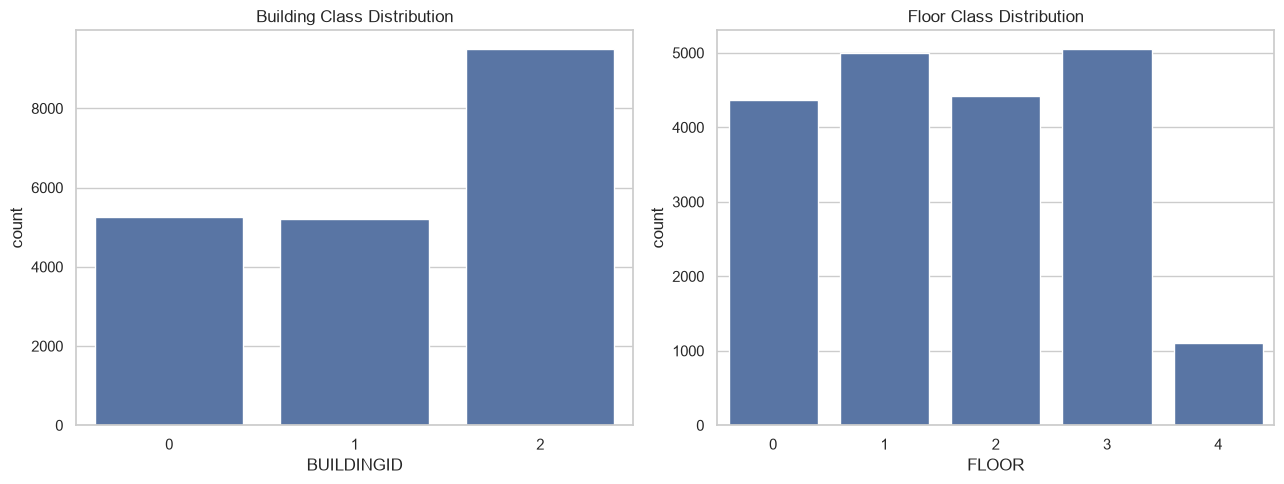

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    ax=axes[0]
)

axes[0].set_title("Building Class Distribution")

sns.countplot(
    data=df_train,
    x="FLOOR",
    ax=axes[1]
)

axes[1].set_title("Floor Class Distribution")

plt.tight_layout()
plt.show()

### 30. Membuat Pembagian Data Training dan Testing

Tujuan: Membagi training dataset menjadi data latih dan data uji internal untuk mengevaluasi performa model.

Pembagian data menggunakan dua skenario:
1. 80% data training dan 20% data testing.
2. 70% data training dan 30% data testing.

Metode stratifikasi: Pembagian menggunakan stratifikasi berdasarkan kombinasi BUILDINGID dan FLOOR agar proporsi setiap kombinasi gedung dan lantai tetap terjaga.

Random State: 42.

Data validation bawaan dataset tidak digunakan dalam proses pembagian ini dan disimpan untuk evaluasi akhir.

In [29]:
# Membuat Stratification Target

stratify_target = (
    y_train["BUILDINGID"].astype(str)
    + "_"
    + y_train["FLOOR"].astype(str)
)


# Skenario 1: Pembagian Data 80:20

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)


# Skenario 2: Pembagian Data 70:30

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.30,
    random_state=42,
    stratify=stratify_target
)


# Menampilkan Hasil Pembagian Data

print("=== SKENARIO 80:20 ===")
print("Training:", X_train_80.shape)
print("Testing :", X_test_80.shape)

print("\n=== SKENARIO 70:30 ===")
print("Training:", X_train_70.shape)
print("Testing :", X_test_70.shape)

=== SKENARIO 80:20 ===
Training: (15949, 520)
Testing : (3988, 520)

=== SKENARIO 70:30 ===
Training: (13955, 520)
Testing : (5982, 520)


### 31. Standardisasi Fitur Menggunakan StandardScaler

Tujuan: Menyamakan skala fitur RSSI agar setiap fitur memiliki skala yang lebih sebanding.

StandardScaler melakukan transformasi berdasarkan rata-rata dan standar deviasi yang dihitung dari data training.

Dalam penelitian ini, StandardScaler akan diterapkan di dalam pipeline preprocessing. Parameter scaling hanya dipelajari dari data training pada setiap skenario eksperimen.

Data testing hanya menggunakan parameter transformasi yang telah dipelajari dari data training.

Standardisasi akan dibandingkan dengan MinMaxScaler pada eksperimen model.

### 32. Perbandingan StandardScaler dan MinMaxScaler

Tujuan: Membandingkan dua metode penskalaan fitur, yaitu StandardScaler dan MinMaxScaler.

StandardScaler: Mengubah fitur berdasarkan rata-rata dan standar deviasi data training.

MinMaxScaler: Mengubah rentang fitur berdasarkan nilai minimum dan maksimum data training.

Metode evaluasi:*Kedua scaler dibandingkan melalui eksperimen model dengan skenario preprocessing, pembagian data, dan konfigurasi model yang konsisten.

Alasan metodologis: Pemilihan scaler tidak hanya didasarkan pada statistik hasil transformasi, tetapi juga pada performa model klasifikasi dan regresi.

Seluruh proses scaling dilakukan di dalam pipeline untuk mencegah data leakage.

### 33. Pipeline Preprocessing

Tujuan: Menggabungkan tahapan preprocessing ke dalam satu pipeline agar seluruh parameter preprocessing hanya dipelajari dari data training.

Pipeline mencakup dua metode penanganan nilai RSSI tidak terdeteksi:

1. Sentinel Replacement: Mengganti nilai +100 menjadi -105 dBm.
2. Median Imputation: Mengubah nilai +100 menjadi NaN, kemudian mengisi nilai tersebut menggunakan median setiap fitur berdasarkan data training.

Pipeline juga menyediakan dua skenario fitur:

1. Full Features: Menggunakan seluruh 520 fitur RSSI.
2. Reduced Features: Menghapus fitur konstan menggunakan VarianceThreshold.

Selain itu, digunakan dua alternatif scaling, yaitu StandardScaler dan MinMaxScaler.

Seluruh tahapan preprocessing di-fit menggunakan data training pada setiap skenario eksperimen. Data testing hanya menjalankan transformasi menggunakan parameter yang telah dipelajari dari data training.

Tujuan metodologis: Mencegah data leakage dan memastikan perbandingan metode preprocessing dilakukan secara konsisten.

In [30]:
# Pipeline Preprocessing

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import FunctionTransformer


# Custom Median Imputer
class RSSIMedianImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):

        X = np.asarray(X, dtype=float)

        self.statistics_ = np.array([
            np.median(col[np.isfinite(col)])
            if np.isfinite(col).any()
            else -105
            for col in X.T
        ])

        return self

    def transform(self, X):

        X = np.asarray(X, dtype=float).copy()

        missing_rows, missing_cols = np.where(np.isnan(X))

        X[missing_rows, missing_cols] = (
            self.statistics_[missing_cols]
        )

        return X


# Pipeline Builder
def build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="full",
    scaler="standard"
):

    steps = []

    # Metode penanganan sentinel
    if method == "sentinel":

        steps.append((
            "sentinel_replacement",
            FunctionTransformer(
                replace_sentinel,
                validate=False
            )
        ))

    elif method == "median":

        steps.append((
            "sentinel_to_nan",
            FunctionTransformer(
                convert_sentinel_to_nan,
                validate=False
            )
        ))

        steps.append((
            "imputer",
            RSSIMedianImputer()
        ))

    else:
        raise ValueError("Metode preprocessing tidak dikenal.")

    # Seleksi fitur
    if feature_mode == "reduced":

        steps.append((
            "selector",
            VarianceThreshold(threshold=0.0)
        ))

    elif feature_mode != "full":

        raise ValueError("Mode fitur tidak dikenal.")

    # Scaling
    if scaler == "standard":

        steps.append((
            "scaler",
            StandardScaler()
        ))

    elif scaler == "minmax":

        steps.append((
            "scaler",
            MinMaxScaler()
        ))

    else:
        raise ValueError("Scaler tidak dikenal.")

    return Pipeline(steps)

In [31]:
# Pengujian Pipeline Preprocessing

results = []

for method in ["sentinel", "median"]:
    for feature_mode in ["full", "reduced"]:
        for scaler in ["standard", "minmax"]:

            pipeline = build_preprocessing_pipeline(
                method=method,
                feature_mode=feature_mode,
                scaler=scaler
            )

            X_train_result = pipeline.fit_transform(X_train_80)

            X_test_result = pipeline.transform(X_test_80)

            # Validasi hasil preprocessing

            assert np.isfinite(X_train_result).all(), (
                "Training mengandung NaN atau Inf."
            )

            assert np.isfinite(X_test_result).all(), (
                "Testing mengandung NaN atau Inf."
            )

            results.append({
                "Method": method,
                "Feature Mode": feature_mode,
                "Scaler": scaler,
                "Training Shape": X_train_result.shape,
                "Testing Shape": X_test_result.shape,
                "Status": "Success"
            })

pipeline_test_results = pd.DataFrame(results)

display(pipeline_test_results)

,Method,Feature Mode,Scaler,Training Shape,Testing Shape,Status
0,sentinel,full,standard,"(15949, 520)","(3988, 520)",Success
1,sentinel,full,minmax,"(15949, 520)","(3988, 520)",Success
2,sentinel,reduced,standard,"(15949, 460)","(3988, 460)",Success
3,sentinel,reduced,minmax,"(15949, 460)","(3988, 460)",Success
4,median,full,standard,"(15949, 520)","(3988, 520)",Success
5,median,full,minmax,"(15949, 520)","(3988, 520)",Success
6,median,reduced,standard,"(15949, 424)","(3988, 424)",Success
7,median,reduced,minmax,"(15949, 424)","(3988, 424)",Success


In [32]:
# Pengujian Pipeline pada Split 70:30

results_70 = []

for method in ["sentinel", "median"]:
    for feature_mode in ["full", "reduced"]:
        for scaler in ["standard", "minmax"]:

            pipeline = build_preprocessing_pipeline(
                method=method,
                feature_mode=feature_mode,
                scaler=scaler
            )

            X_train_result = pipeline.fit_transform(X_train_70)

            X_test_result = pipeline.transform(X_test_70)
            # Validasi hasil preprocessing

            assert np.isfinite(X_train_result).all(), (
                "Training mengandung NaN atau Inf."
            )

            assert np.isfinite(X_test_result).all(), (
                "Testing mengandung NaN atau Inf."
            )

            results_70.append({
                "Method": method,
                "Feature Mode": feature_mode,
                "Scaler": scaler,
                "Training Shape": X_train_result.shape,
                "Testing Shape": X_test_result.shape,
                "Status": "Success"
            })

pipeline_test_70 = pd.DataFrame(results_70)

display(pipeline_test_70)

,Method,Feature Mode,Scaler,Training Shape,Testing Shape,Status
0,sentinel,full,standard,"(13955, 520)","(5982, 520)",Success
1,sentinel,full,minmax,"(13955, 520)","(5982, 520)",Success
2,sentinel,reduced,standard,"(13955, 460)","(5982, 460)",Success
3,sentinel,reduced,minmax,"(13955, 460)","(5982, 460)",Success
4,median,full,standard,"(13955, 520)","(5982, 520)",Success
5,median,full,minmax,"(13955, 520)","(5982, 520)",Success
6,median,reduced,standard,"(13955, 419)","(5982, 419)",Success
7,median,reduced,minmax,"(13955, 419)","(5982, 419)",Success


In [33]:
# Perbandingan Statistik Dua Metode Penanganan RSSI

def compare_rssi_methods(X_train, split_name):

    # Metode 1: Sentinel Replacement
    X_sentinel = replace_sentinel(X_train.copy())

    # Metode 2: Median Imputation
    X_nan = convert_sentinel_to_nan(X_train.copy())

    median_imputer = RSSIMedianImputer()
    X_median = median_imputer.fit_transform(X_nan)

    # Mengubah hasil menjadi DataFrame
    X_sentinel = pd.DataFrame(
        X_sentinel,
        columns=X_train.columns
    )

    X_median = pd.DataFrame(
        X_median,
        columns=X_train.columns
    )

    # Ringkasan statistik
    summary = []

    for method, data in [
        ("Sentinel Replacement", X_sentinel),
        ("Median Imputation", X_median)
    ]:

        summary.append({
            "Split": split_name,
            "Method": method,
            "Mean": data.mean().mean(),
            "Std": data.std().mean(),
            "Minimum": data.min().min(),
            "Maximum": data.max().max()
        })

    return summary


# Perbandingan pada kedua skenario split

comparison_results = []

comparison_results.extend(
    compare_rssi_methods(X_train_80, "80:20")
)

comparison_results.extend(
    compare_rssi_methods(X_train_70, "70:30")
)

rssi_comparison = pd.DataFrame(comparison_results)

display(rssi_comparison.round(3))

,Split,Method,Mean,Std,Minimum,Maximum
0,80:20,Sentinel Replacement,-104.083,3.738,-105.0,0.0
1,80:20,Median Imputation,-86.425,1.522,-105.0,0.0
2,70:30,Sentinel Replacement,-104.084,3.736,-105.0,0.0
3,70:30,Median Imputation,-86.456,1.521,-105.0,0.0


### Interpretasi Hasil Perbandingan Statistik

Berdasarkan hasil perbandingan, median imputation menghasilkan nilai mean RSSI yang lebih tinggi dibandingkan sentinel replacement pada kedua skenario pembagian data.

Standar deviasi pada median imputation juga lebih rendah. Hal ini menunjukkan bahwa penggantian nilai RSSI yang tidak terdeteksi menggunakan median mengubah distribusi nilai dan mengurangi variasi data.

Kedua metode menghasilkan rentang nilai yang sama, yaitu -105 hingga 0 dBm.

Hasil pada split 80:20 dan 70:30 menunjukkan karakteristik statistik yang relatif konsisten.

Namun, perubahan mean dan standar deviasi tidak dapat dijadikan dasar tunggal untuk menentukan metode terbaik. Penentuan metode terbaik tetap memerlukan evaluasi performa model pada tahap eksperimen.

Dengan demikian, kedua metode tetap dipertahankan sebagai alternatif preprocessing untuk dibandingkan lebih lanjut.

## PROSES 2: CLUSTERING

Tahap ini bertujuan mengelompokkan data fingerprint RSSI Wi-Fi berdasarkan kemiripan karakteristik sinyal tanpa menggunakan label target sebagai fitur pembentuk cluster.

Algoritma yang digunakan:
1. K-Means untuk mengelompokkan data berdasarkan jumlah cluster optimal.
2. DBSCAN untuk mengidentifikasi kelompok berdasarkan kepadatan data.

Evaluasi dilakukan menggunakan Silhouette Score, Davies-Bouldin Index, Adjusted Rand Index (ARI), dan Normalized Mutual Information (NMI).

Visualisasi PCA 2D digunakan untuk membantu memahami struktur cluster. Interpretasi fisik dilakukan dengan membandingkan hasil cluster terhadap BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

### 34. Persiapan Data Clustering

Tahap ini menyiapkan data RSSI Wi-Fi untuk proses clustering menggunakan K-Means dan DBSCAN.

Konfigurasi utama menggunakan Sentinel Replacement, Reduced Features, dan MinMaxScaler.

Seluruh preprocessing di-fit menggunakan training dataset. BUILDINGID dan FLOOR tidak digunakan sebagai fitur pembentuk cluster, tetapi disimpan sebagai label referensi untuk evaluasi menggunakan ARI dan NMI.

Data validation tidak digunakan dalam proses clustering ini.

In [34]:

# 1. Membuat pipeline preprocessing
clustering_preprocessor = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="minmax"
)

# 2. Fit preprocessing pada seluruh training dataset
X_cluster = clustering_preprocessor.fit_transform(X_train_raw)

# 3. Menyimpan label asli untuk evaluasi
y_cluster_building = y_train["BUILDINGID"].reset_index(drop=True)
y_cluster_floor = y_train["FLOOR"].reset_index(drop=True)

# 4. Pemeriksaan hasil
print("=== DATA CLUSTERING ===")
print("Jumlah observasi:", X_cluster.shape[0])
print("Jumlah fitur:", X_cluster.shape[1])

print("\n=== LABEL REFERENSI ===")
print("BUILDINGID:", y_cluster_building.shape)
print("FLOOR:", y_cluster_floor.shape)

print("\n=== VALIDASI DATA ===")
print("Mengandung NaN:", np.isnan(X_cluster).any())
print("Mengandung Inf:", np.isinf(X_cluster).any())

=== DATA CLUSTERING ===
Jumlah observasi: 19937
Jumlah fitur: 465

=== LABEL REFERENSI ===
BUILDINGID: (19937,)
FLOOR: (19937,)

=== VALIDASI DATA ===
Mengandung NaN: False
Mengandung Inf: False


### 35. Penentuan Jumlah Cluster K-Means

K-Means digunakan untuk mengelompokkan fingerprint RSSI Wi-Fi berdasarkan kemiripan karakteristik sinyal.

Penentuan jumlah cluster optimal dilakukan menggunakan Elbow Method dan Silhouette Score.

Elbow Method mengamati perubahan Within-Cluster Sum of Squares (WCSS) atau inertia pada beberapa nilai k. Silhouette Score digunakan untuk menilai tingkat kekompakan dan pemisahan antarcluster.

Kandidat jumlah cluster diuji pada rentang k = 2 sampai k = 10.

In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Kandidat jumlah cluster
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster)

    inertia_values.append(kmeans.inertia_)

    # Silhouette dihitung menggunakan sampel 3000 observasi
    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_values.append(score)

    print(
        f"k={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )

k=2 | Inertia=57682.71 | Silhouette=0.4622
k=3 | Inertia=53502.31 | Silhouette=0.1579
k=4 | Inertia=49746.73 | Silhouette=0.1674
k=5 | Inertia=46938.84 | Silhouette=0.1271
k=6 | Inertia=45046.67 | Silhouette=0.0789
k=7 | Inertia=43464.29 | Silhouette=0.0940
k=8 | Inertia=41683.68 | Silhouette=0.1108
k=9 | Inertia=40671.95 | Silhouette=0.1076
k=10 | Inertia=39351.40 | Silhouette=0.1293


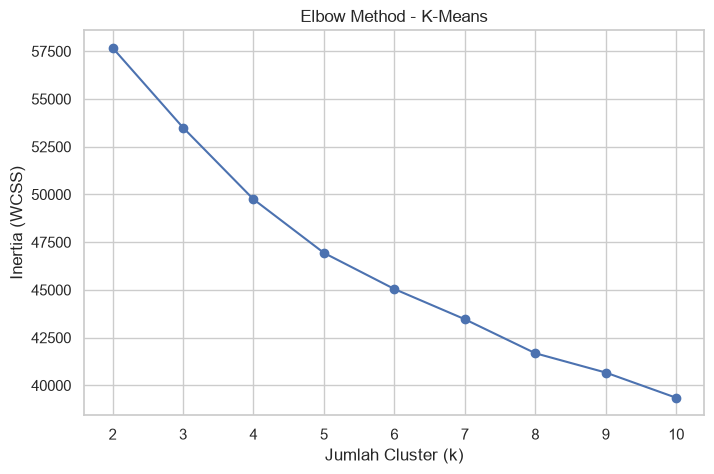

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method - K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

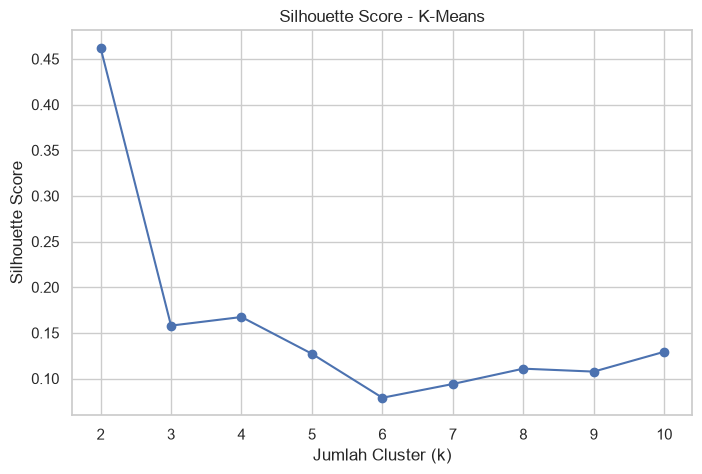

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 36. Perbandingan Kandidat Jumlah Cluster K-Means

Berdasarkan Elbow Method dan Silhouette Score, diperoleh dua kandidat jumlah cluster, yaitu k=2 dan k=4.

K=2 menghasilkan Silhouette Score tertinggi sebesar 0,4622. Sementara itu, k=4 menjadi kandidat berdasarkan pola penurunan inertia pada Elbow Method.

Kedua kandidat akan dibandingkan menggunakan Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) terhadap label referensi BUILDINGID dan FLOOR.

Label referensi hanya digunakan untuk evaluasi, bukan sebagai fitur pembentuk cluster.

In [38]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

k_candidates = [2, 4]
kmeans_comparison = []

kmeans_models = {}
kmeans_labels = {}

for k in k_candidates:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    kmeans_models[k] = model
    kmeans_labels[k] = labels

    # Evaluasi terhadap label asli
    ari_building = adjusted_rand_score(
        y_cluster_building, labels
    )

    nmi_building = normalized_mutual_info_score(
        y_cluster_building, labels
    )

    ari_floor = adjusted_rand_score(
        y_cluster_floor, labels
    )

    nmi_floor = normalized_mutual_info_score(
        y_cluster_floor, labels
    )

    kmeans_comparison.append({
        "k": k,
        "ARI Building": ari_building,
        "NMI Building": nmi_building,
        "ARI Floor": ari_floor,
        "NMI Floor": nmi_floor
    })

kmeans_comparison_df = pd.DataFrame(kmeans_comparison)

display(kmeans_comparison_df.round(4))

,k,ARI Building,NMI Building,ARI Floor,NMI Floor
0,2,0.0125,0.0412,0.0014,0.0259
1,4,0.4343,0.5740,-0.0081,0.0344


### Interpretasi Hasil Perbandingan K-Means

Hasil evaluasi menunjukkan bahwa k=4 memiliki kesesuaian yang lebih tinggi terhadap label BUILDINGID dibandingkan k=2. Nilai ARI sebesar 0,4343 dan NMI sebesar 0,5740 menunjukkan adanya hubungan antara hasil clustering dan identitas gedung.

Sebaliknya, kesesuaian kedua kandidat terhadap FLOOR masih rendah. Nilai ARI mendekati nol menunjukkan bahwa hasil pengelompokan belum mampu merepresentasikan struktur lantai secara baik.

Meskipun k=2 menghasilkan Silhouette Score tertinggi sebesar 0,4622, nilai ARI dan NMI terhadap BUILDINGID dan FLOOR relatif rendah.

Dengan mempertimbangkan hasil Elbow Method, Silhouette Score, ARI, dan NMI, k=4 dipertahankan sebagai kandidat utama untuk analisis struktur gedung. Sementara itu, k=2 tetap digunakan sebagai pembanding.

Keputusan akhir akan mempertimbangkan evaluasi internal dan interpretasi fisik cluster.

In [39]:
from sklearn.metrics import davies_bouldin_score

dbi_results = []

for k in [2, 4]:

    labels = kmeans_labels[k]

    dbi = davies_bouldin_score(
        X_cluster,
        labels
    )

    dbi_results.append({
        "k": k,
        "Silhouette Score": silhouette_values[k - 2],
        "Davies-Bouldin Index": dbi
    })

dbi_comparison = pd.DataFrame(dbi_results)

display(dbi_comparison.round(4))

,k,Silhouette Score,Davies-Bouldin Index
0,2,0.4622,0.9414
1,4,0.1674,1.9349


### Interpretasi Evaluasi Internal dan Eksternal K-Means

Berdasarkan evaluasi internal, k=2 menghasilkan Silhouette Score sebesar 0,4622 dan Davies-Bouldin Index sebesar 0,9414. Hasil ini menunjukkan kualitas kekompakan dan pemisahan cluster yang lebih baik dibandingkan k=4.

Namun, evaluasi eksternal menunjukkan bahwa k=4 memiliki kesesuaian lebih tinggi terhadap BUILDINGID, dengan ARI sebesar 0,4343 dan NMI sebesar 0,5740.

Kedua konfigurasi belum menunjukkan kesesuaian yang baik terhadap FLOOR.

Hasil ini menunjukkan adanya perbedaan antara struktur cluster berdasarkan kemiripan RSSI dan struktur lokasi fisik berdasarkan label gedung serta lantai.

Oleh karena itu, k=2 dan k=4 tetap dipertahankan sebagai kandidat untuk analisis lanjutan dan interpretasi fisik cluster.

### 37. Penentuan Parameter DBSCAN Menggunakan K-Distance Plot

DBSCAN merupakan algoritma clustering berbasis kepadatan yang mengelompokkan observasi berdasarkan jarak antar titik dan jumlah minimum observasi di sekitar suatu titik.

Parameter utama yang digunakan adalah:

- eps: radius maksimum lingkungan suatu titik.
- min_samples: jumlah minimum observasi untuk membentuk daerah padat.

Nilai eps dianalisis menggunakan k-distance plot. Titik perubahan kemiringan kurva digunakan sebagai kandidat nilai eps.

Analisis dilakukan menggunakan fitur RSSI yang telah melalui preprocessing dan scaling.

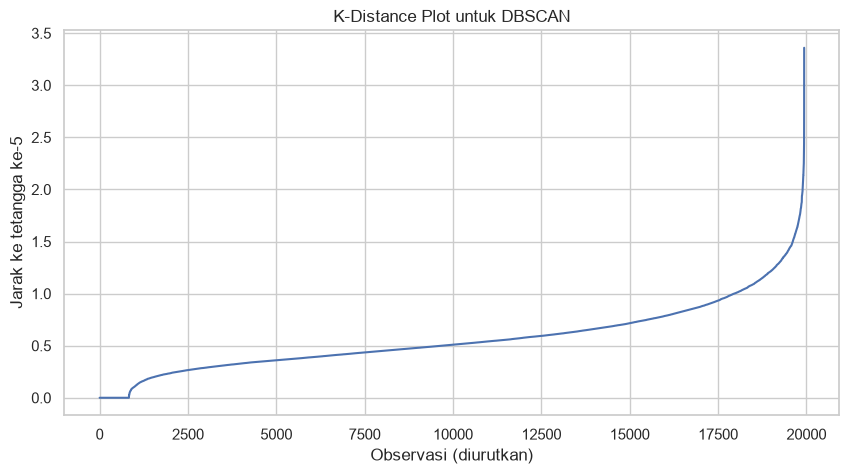

In [40]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Parameter awal
min_samples_dbscan = 5

# Menghitung jarak ke tetangga terdekat
neighbors = NearestNeighbors(
    n_neighbors=min_samples_dbscan,
    metric="euclidean"
)

neighbors.fit(X_cluster)

distances, indices = neighbors.kneighbors(X_cluster)

# Mengambil jarak tetangga ke-5
k_distances = np.sort(distances[:, -1])

# Visualisasi k-distance plot
plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Observasi (diurutkan)")
plt.ylabel("Jarak ke tetangga ke-5")
plt.title("K-Distance Plot untuk DBSCAN")
plt.grid(True)

plt.show()

### 38. Pengujian Kandidat Parameter DBSCAN

Berdasarkan K-distance plot, beberapa kandidat nilai eps diuji untuk memperoleh konfigurasi DBSCAN yang sesuai.

Parameter min_samples ditetapkan sebesar 5 sebagai konfigurasi awal. Kandidat eps yang diuji adalah 1.0, 1.2, 1.4, dan 1.6.

Evaluasi memperhatikan jumlah cluster yang terbentuk, jumlah noise, serta kualitas cluster menggunakan Silhouette Score dan Davies-Bouldin Index.

Observasi yang diklasifikasikan sebagai noise tidak dimasukkan dalam perhitungan metrik internal clustering.

In [41]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
import pandas as pd
import numpy as np

eps_candidates = [1.0, 1.2, 1.4, 1.6]
min_samples_dbscan = 5

dbscan_results = []
dbscan_models = {}
dbscan_labels = {}

for eps in eps_candidates:

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples_dbscan,
        metric="euclidean"
    )

    labels = model.fit_predict(X_cluster)

    dbscan_models[eps] = model
    dbscan_labels[eps] = labels

    # Menghitung jumlah cluster tanpa noise
    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})

    # Menghitung jumlah noise
    n_noise = np.sum(labels == -1)
    noise_percentage = n_noise / len(labels) * 100

    # Metrik internal hanya untuk observasi non-noise
    non_noise_mask = labels != -1
    X_valid = X_cluster[non_noise_mask]
    labels_valid = labels[non_noise_mask]

    if 1 < len(np.unique(labels_valid)) < len(labels_valid):

        silhouette = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(3000, len(X_valid)),
            random_state=42
        )

        dbi = davies_bouldin_score(
            X_valid,
            labels_valid
        )

    else:
        silhouette = np.nan
        dbi = np.nan

    dbscan_results.append({
        "eps": eps,
        "min_samples": min_samples_dbscan,
        "Jumlah Cluster": n_clusters,
        "Jumlah Noise": n_noise,
        "Noise (%)": noise_percentage,
        "Silhouette": silhouette,
        "Davies-Bouldin": dbi
    })

dbscan_comparison = pd.DataFrame(dbscan_results)

display(dbscan_comparison.round(4))

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette,Davies-Bouldin
0,1.0,5,148,1372,6.8817,-0.0664,0.9102
1,1.2,5,100,616,3.0897,-0.0009,0.8633
2,1.4,5,62,252,1.2640,0.0174,0.8892
3,1.6,5,33,112,0.5618,0.1905,0.8579


### Interpretasi Hasil Pengujian DBSCAN

Berdasarkan pengujian empat kandidat eps dengan min_samples sebesar 5, diperoleh perubahan jumlah cluster dan noise seiring peningkatan nilai eps.

Pada eps=1.0, DBSCAN menghasilkan 148 cluster dengan 6,8817% observasi teridentifikasi sebagai noise. Silhouette Score bernilai negatif, yang menunjukkan kualitas pemisahan cluster belum baik.

Pada eps=1.6, jumlah cluster berkurang menjadi 33 dengan persentase noise sebesar 0,5618%. Konfigurasi ini menghasilkan Silhouette Score tertinggi sebesar 0,1905 dan Davies-Bouldin Index terendah sebesar 0,8579.

Dengan mempertimbangkan kedua metrik internal, eps=1.6 dipilih sebagai kandidat utama untuk evaluasi lanjutan.

Meskipun demikian, konfigurasi ini belum ditetapkan sebagai hasil terbaik secara keseluruhan. Evaluasi eksternal menggunakan ARI dan NMI serta interpretasi fisik cluster tetap diperlukan.

### 39. Evaluasi Eksternal DBSCAN

Evaluasi eksternal dilakukan untuk mengetahui kesesuaian hasil clustering DBSCAN terhadap label referensi BUILDINGID dan FLOOR.

Metrik yang digunakan adalah Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI).

Seluruh observasi digunakan dalam evaluasi, termasuk observasi yang dikategorikan sebagai noise dengan label -1. Noise diperlakukan sebagai satu kategori tersendiri dalam perhitungan metrik eksternal.

In [42]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

dbscan_external_results = []

for eps in eps_candidates:

    labels = dbscan_labels[eps]

    ari_building = adjusted_rand_score(
        y_cluster_building,
        labels
    )

    nmi_building = normalized_mutual_info_score(
        y_cluster_building,
        labels
    )

    ari_floor = adjusted_rand_score(
        y_cluster_floor,
        labels
    )

    nmi_floor = normalized_mutual_info_score(
        y_cluster_floor,
        labels
    )

    dbscan_external_results.append({
        "eps": eps,
        "ARI Building": ari_building,
        "NMI Building": nmi_building,
        "ARI Floor": ari_floor,
        "NMI Floor": nmi_floor
    })

dbscan_external_df = pd.DataFrame(
    dbscan_external_results
)

display(dbscan_external_df.round(4))

,eps,ARI Building,NMI Building,ARI Floor,NMI Floor
0,1.0,0.1903,0.2619,0.0143,0.1436
1,1.2,0.0431,0.1194,0.0075,0.1197
2,1.4,0.0326,0.0920,-0.0017,0.0762
3,1.6,0.0236,0.0710,-0.0000,0.0550


### Interpretasi Hasil Evaluasi Eksternal DBSCAN

Berdasarkan evaluasi eksternal, eps=1.0 menghasilkan nilai ARI dan NMI tertinggi terhadap BUILDINGID, masing-masing sebesar 0,1903 dan 0,2619.

Konfigurasi tersebut juga menghasilkan nilai ARI dan NMI FLOOR tertinggi dibandingkan kandidat eps lainnya. Namun, nilai ARI FLOOR sebesar 0,0143 masih menunjukkan kesesuaian yang sangat rendah.

Sementara itu, eps=1.6 memiliki kualitas internal terbaik berdasarkan Silhouette Score dan Davies-Bouldin Index, tetapi kesesuaiannya terhadap label asli lebih rendah.

Hasil ini menunjukkan adanya trade-off antara kualitas internal cluster dan kesesuaian terhadap label lokasi sebenarnya.

Oleh karena itu, eps=1.0 dan eps=1.6 dipertahankan sebagai dua konfigurasi pembanding untuk analisis lanjutan.

### 40. Visualisasi Cluster Menggunakan PCA 2D

Principal Component Analysis (PCA) digunakan untuk mereduksi dimensi data menjadi dua komponen utama agar hasil clustering dapat divisualisasikan dalam bidang dua dimensi.

PCA hanya digunakan untuk visualisasi. Proses clustering tetap menggunakan seluruh fitur RSSI hasil preprocessing.

Visualisasi dilakukan untuk membandingkan struktur cluster K-Means dan DBSCAN.

In [43]:
from sklearn.decomposition import PCA

# PCA untuk visualisasi 2D
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_cluster)

print("Dimensi PCA:", X_pca.shape)

print(
    "Total explained variance ratio:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Dimensi PCA: (19937, 2)
Total explained variance ratio: 0.1676


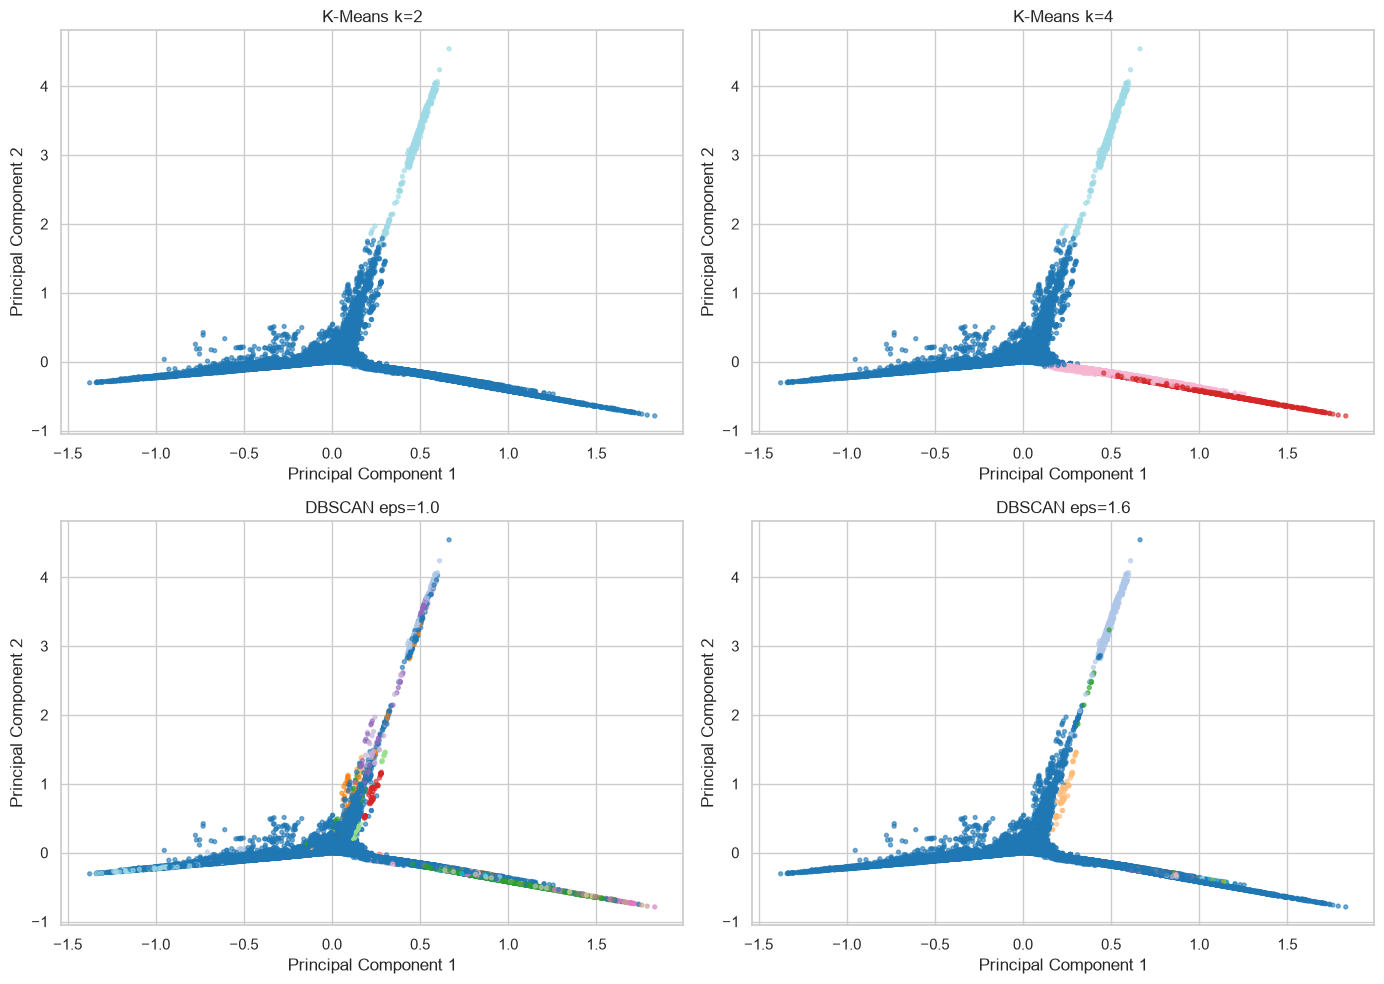

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cluster_configs = [
    ("K-Means k=2", kmeans_labels[2]),
    ("K-Means k=4", kmeans_labels[4]),
    ("DBSCAN eps=1.0", dbscan_labels[1.0]),
    ("DBSCAN eps=1.6", dbscan_labels[1.6])
]

for ax, (title, labels) in zip(
    axes.flatten(),
    cluster_configs
):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab20",
        s=8,
        alpha=0.6
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### Interpretasi Visualisasi PCA 2D

Hasil PCA menghasilkan dua komponen utama dengan total explained variance ratio sebesar 16,76%. Artinya, kedua komponen tersebut hanya merepresentasikan sebagian variasi dari keseluruhan fitur RSSI.

Pada K-Means k=2, data terbagi menjadi dua kelompok besar. Pada k=4, pembagian cluster menjadi lebih terperinci.

DBSCAN eps=1.0 menghasilkan banyak kelompok kecil, sedangkan eps=1.6 menghasilkan jumlah cluster yang lebih sedikit dengan lebih banyak observasi tergabung dalam kelompok yang lebih besar.

Visualisasi PCA digunakan untuk membantu mengamati pola distribusi cluster. Karena proporsi variasi yang dijelaskan hanya 16,76%, interpretasi visual tidak digunakan sebagai satu-satunya dasar untuk menentukan kualitas clustering.

Evaluasi tetap mempertimbangkan Silhouette Score, Davies-Bouldin Index, ARI, dan NMI.

### 41. Interpretasi Fisik Cluster K-Means

Interpretasi fisik dilakukan dengan menganalisis hubungan antara hasil clustering dan karakteristik lokasi sebenarnya.

Analisis mencakup distribusi BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE pada setiap cluster.

Label asli tidak digunakan dalam pembentukan cluster, tetapi digunakan untuk memahami karakteristik geografis dan posisi fisik kelompok yang terbentuk.

In [45]:
# Membuat dataframe interpretasi cluster K-Means

cluster_analysis = pd.DataFrame({
    "BUILDINGID": y_cluster_building,
    "FLOOR": y_cluster_floor,
    "LONGITUDE": y_train["LONGITUDE"].reset_index(drop=True),
    "LATITUDE": y_train["LATITUDE"].reset_index(drop=True)
})

# Menambahkan label cluster
cluster_analysis["KMeans_k2"] = kmeans_labels[2]
cluster_analysis["KMeans_k4"] = kmeans_labels[4]

# Profil distribusi gedung untuk K-Means k=4
print("=== DISTRIBUSI BUILDINGID PER CLUSTER ===")

display(
    pd.crosstab(
        cluster_analysis["KMeans_k4"],
        cluster_analysis["BUILDINGID"],
        normalize="index"
    ).round(3)
)

# Profil distribusi lantai untuk K-Means k=4
print("=== DISTRIBUSI FLOOR PER CLUSTER ===")

display(
    pd.crosstab(
        cluster_analysis["KMeans_k4"],
        cluster_analysis["FLOOR"],
        normalize="index"
    ).round(3)
)

# Rata-rata koordinat setiap cluster
print("=== RATA-RATA KOORDINAT PER CLUSTER ===")

display(
    cluster_analysis.groupby("KMeans_k4")[
        ["LONGITUDE", "LATITUDE"]
    ].mean().round(6)
)

=== DISTRIBUSI BUILDINGID PER CLUSTER ===


BUILDINGID,0,1,2
KMeans_k4,,,
0,0.015,0.333,0.652
1,1.000,0.000,0.000
2,1.000,0.000,0.000
3,0.000,1.000,0.000


=== DISTRIBUSI FLOOR PER CLUSTER ===


FLOOR,0,1,2,3,4
KMeans_k4,,,,,
0,0.215,0.250,0.206,0.254,0.076
1,0.192,0.265,0.270,0.273,0.000
2,0.175,0.265,0.295,0.264,0.000
3,0.904,0.096,0.000,0.000,0.000


=== RATA-RATA KOORDINAT PER CLUSTER ===


,LONGITUDE,LATITUDE
KMeans_k4,,
0,-7403.841115,4.864842e+06
1,-7657.062828,4.864927e+06
2,-7622.360373,4.864988e+06
3,-7456.350020,4.864827e+06


### Interpretasi Fisik Cluster K-Means k=4

Berdasarkan distribusi BUILDINGID, cluster 1 dan cluster 2 seluruhnya berasal dari Building 0. Cluster 3 seluruhnya berasal dari Building 1, sedangkan cluster 0 didominasi Building 2 sebesar 65,2%.

Hasil ini menunjukkan bahwa K-Means mampu membentuk beberapa kelompok yang memiliki keterkaitan dengan identitas gedung. Namun, cluster 0 masih mencampurkan observasi dari beberapa gedung.

Berdasarkan distribusi FLOOR, cluster 3 didominasi oleh FLOOR 0 sebesar 90,4%. Sementara itu, cluster 1 dan cluster 2 memiliki distribusi lantai yang relatif merata pada FLOOR 0 sampai FLOOR 3.

Hasil ini menunjukkan bahwa pemisahan berdasarkan lantai belum terbentuk secara konsisten.

Rata-rata longitude dan latitude juga menunjukkan perbedaan posisi antarcluster. Namun, interpretasi geografis lebih lanjut memerlukan pemeriksaan sistem koordinat dan sebaran koordinat setiap cluster.

Secara keseluruhan, K-Means k=4 mampu menangkap sebagian struktur lokasi berdasarkan gedung, tetapi belum sepenuhnya memisahkan karakteristik lantai.

In [46]:
# Menambahkan label cluster DBSCAN

cluster_analysis["DBSCAN_eps1"] = dbscan_labels[1.0]
cluster_analysis["DBSCAN_eps1_6"] = dbscan_labels[1.6]


def analyze_dbscan_clusters(data, cluster_column):

    print(f"\n=== {cluster_column}: BUILDINGID ===")

    display(
        pd.crosstab(
            data[cluster_column],
            data["BUILDINGID"],
            normalize="index"
        ).round(3)
    )

    print(f"\n=== {cluster_column}: FLOOR ===")

    display(
        pd.crosstab(
            data[cluster_column],
            data["FLOOR"],
            normalize="index"
        ).round(3)
    )

    print(f"\n=== {cluster_column}: KOORDINAT ===")

    display(
        data.groupby(cluster_column)[
            ["LONGITUDE", "LATITUDE"]
        ].mean().round(3)
    )


analyze_dbscan_clusters(
    cluster_analysis,
    "DBSCAN_eps1"
)

analyze_dbscan_clusters(
    cluster_analysis,
    "DBSCAN_eps1_6"
)


=== DBSCAN_eps1: BUILDINGID ===


BUILDINGID,0,1,2
DBSCAN_eps1,,,
-1,0.585,0.166,0.249
0,0.128,0.282,0.589
1,0.000,0.000,1.000
2,0.000,1.000,0.000
3,0.000,1.000,0.000
...,...,...,...
143,0.000,0.000,1.000
144,0.000,0.000,1.000
145,0.000,0.000,1.000



=== DBSCAN_eps1: FLOOR ===


FLOOR,0,1,2,3,4
DBSCAN_eps1,,,,,
-1,0.075,0.347,0.321,0.246,0.012
0,0.238,0.238,0.213,0.269,0.042
1,0.000,0.000,0.000,1.000,0.000
2,0.000,0.000,1.000,0.000,0.000
3,0.000,0.000,1.000,0.000,0.000
...,...,...,...,...,...
143,0.000,1.000,0.000,0.000,0.000
144,0.000,1.000,0.000,0.000,0.000
145,0.000,1.000,0.000,0.000,0.000



=== DBSCAN_eps1: KOORDINAT ===


,LONGITUDE,LATITUDE
DBSCAN_eps1,,
-1,-7537.279,4864911.100
0,-7427.912,4864859.185
1,-7329.027,4864766.304
2,-7458.264,4864852.084
3,-7507.032,4864834.894
...,...,...
143,-7320.132,4864816.324
144,-7338.259,4864821.407
145,-7331.117,4864821.621


... (2 outputs left out)


=== DBSCAN_eps1_6: FLOOR ===


FLOOR,0,1,2,3,4
DBSCAN_eps1_6,,,,,
-1,0.089,0.196,0.652,0.062,0.000
0,0.212,0.250,0.221,0.260,0.057
1,0.966,0.034,0.000,0.000,0.000
2,0.000,1.000,0.000,0.000,0.000
3,0.000,1.000,0.000,0.000,0.000
4,1.000,0.000,0.000,0.000,0.000
5,0.000,1.000,0.000,0.000,0.000
6,1.000,0.000,0.000,0.000,0.000
7,0.000,1.000,0.000,0.000,0.000



=== DBSCAN_eps1_6: KOORDINAT ===


,LONGITUDE,LATITUDE
DBSCAN_eps1_6,,
-1,-7560.922,4864939.782
0,-7461.879,4864870.146
1,-7456.262,4864825.645
2,-7312.583,4864797.237
3,-7328.049,4864766.951
4,-7499.118,4864838.798
5,-7506.735,4864857.355
6,-7458.241,4864850.011
7,-7638.904,4864999.541


In [47]:
# Ringkasan ukuran cluster DBSCAN

def summarize_dbscan_clusters(data, cluster_column):

    summary = (
        data.groupby(cluster_column)
        .agg(
            Jumlah_Data=("BUILDINGID", "size"),
            Building_Dominan=(
                "BUILDINGID",
                lambda x: x.mode().iloc[0]
            ),
            Floor_Dominan=(
                "FLOOR",
                lambda x: x.mode().iloc[0]
            ),
            Persentase_Building_Dominan=(
                "BUILDINGID",
                lambda x: x.value_counts(normalize=True).max() * 100
            ),
            Persentase_Floor_Dominan=(
                "FLOOR",
                lambda x: x.value_counts(normalize=True).max() * 100
            )
        )
        .sort_values("Jumlah_Data", ascending=False)
    )

    summary["Jumlah_Data"] = summary["Jumlah_Data"].astype(int)

    return summary.round(2)


print("=== RINGKASAN DBSCAN EPS 1.0 ===")
display(
    summarize_dbscan_clusters(
        cluster_analysis,
        "DBSCAN_eps1"
    )
)

print("=== RINGKASAN DBSCAN EPS 1.6 ===")
display(
    summarize_dbscan_clusters(
        cluster_analysis,
        "DBSCAN_eps1_6"
    )
)

=== RINGKASAN DBSCAN EPS 1.0 ===


,Jumlah_Data,Building_Dominan,Floor_Dominan,Persentase_Building_Dominan,Persentase_Floor_Dominan
DBSCAN_eps1,,,,,
0,14422,2,3,58.93,26.94
34,2002,0,1,100.00,25.77
-1,1372,0,1,58.53,34.69
54,230,2,4,100.00,100.00
53,210,2,4,100.00,100.00
...,...,...,...,...,...
135,5,0,2,100.00,100.00
140,5,0,3,100.00,100.00
141,5,0,3,100.00,100.00


=== RINGKASAN DBSCAN EPS 1.6 ===


,Jumlah_Data,Building_Dominan,Floor_Dominan,Persentase_Building_Dominan,Persentase_Floor_Dominan
DBSCAN_eps1_6,,,,,
0,19172,2,3,49.29,26.03
1,293,1,0,100.00,96.59
5,126,1,1,100.00,100.00
-1,112,0,2,71.43,65.18
6,10,1,0,100.00,100.00
7,10,0,1,100.00,100.00
8,10,0,1,100.00,100.00
9,10,0,1,100.00,100.00
16,10,0,2,100.00,100.00


### Interpretasi Fisik Cluster DBSCAN

Pada eps=1.0, cluster terbesar berisi 14.422 observasi atau sekitar 72,34% dari keseluruhan data. Cluster 34 berisi 2.002 observasi dan seluruhnya berasal dari Building 0. Namun, konfigurasi ini menghasilkan 148 cluster dan persentase noise sebesar 6,88%, sehingga menunjukkan fragmentasi kelompok yang cukup tinggi.

Pada eps=1.6, cluster terbesar berisi 19.172 observasi atau sekitar 96,16% dari keseluruhan data. Beberapa cluster kecil menunjukkan kesesuaian yang kuat terhadap gedung dan lantai tertentu. Namun, dominasi satu cluster besar menunjukkan bahwa sebagian besar observasi belum terpisah menjadi kelompok yang lebih spesifik.

Dengan demikian, eps=1.0 memiliki kesesuaian lebih tinggi terhadap BUILDINGID berdasarkan ARI dan NMI, sedangkan eps=1.6 memiliki kualitas internal lebih baik berdasarkan Silhouette Score dan Davies-Bouldin Index.

Kedua konfigurasi memiliki keterbatasan dalam merepresentasikan struktur lokasi indoor secara menyeluruh. Hasil clustering perlu diinterpretasikan dengan mempertimbangkan ukuran cluster, distribusi gedung, distribusi lantai, dan jumlah noise.

### 42. Perbandingan Hasil K-Means dan DBSCAN

Perbandingan dilakukan untuk mengevaluasi kualitas clustering berdasarkan metrik internal dan eksternal.

Metrik internal meliputi Silhouette Score dan Davies-Bouldin Index. Metrik eksternal meliputi Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) terhadap BUILDINGID dan FLOOR.

Selain itu, jumlah cluster dan noise digunakan untuk memahami karakteristik pengelompokan masing-masing algoritma.

Perbandingan ini bertujuan mengidentifikasi kelebihan dan keterbatasan setiap konfigurasi dalam merepresentasikan struktur lokasi indoor berdasarkan fingerprint RSSI Wi-Fi.

In [48]:
# Tabel perbandingan akhir K-Means dan DBSCAN

final_clustering_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Configuration": "k=2",
        "Clusters": 2,
        "Noise (%)": 0,
        "Silhouette": 0.4622,
        "Davies-Bouldin": 0.9414,
        "ARI Building": 0.0125,
        "NMI Building": 0.0412,
        "ARI Floor": 0.0014,
        "NMI Floor": 0.0259
    },
    {
        "Algorithm": "K-Means",
        "Configuration": "k=4",
        "Clusters": 4,
        "Noise (%)": 0,
        "Silhouette": 0.1674,
        "Davies-Bouldin": 1.9349,
        "ARI Building": 0.4343,
        "NMI Building": 0.5740,
        "ARI Floor": -0.0081,
        "NMI Floor": 0.0344
    },
    {
        "Algorithm": "DBSCAN",
        "Configuration": "eps=1.0",
        "Clusters": 148,
        "Noise (%)": 6.8817,
        "Silhouette": -0.0664,
        "Davies-Bouldin": 0.9102,
        "ARI Building": 0.1903,
        "NMI Building": 0.2619,
        "ARI Floor": 0.0143,
        "NMI Floor": 0.1436
    },
    {
        "Algorithm": "DBSCAN",
        "Configuration": "eps=1.6",
        "Clusters": 33,
        "Noise (%)": 0.5618,
        "Silhouette": 0.1905,
        "Davies-Bouldin": 0.8579,
        "ARI Building": 0.0236,
        "NMI Building": 0.0710,
        "ARI Floor": 0.0000,
        "NMI Floor": 0.0550
    }
])

display(final_clustering_comparison.round(4))

,Algorithm,Configuration,Clusters,Noise (%),Silhouette,Davies-Bouldin,ARI Building,NMI Building,ARI Floor,NMI Floor
0,K-Means,k=2,2,0.0000,0.4622,0.9414,0.0125,0.0412,0.0014,0.0259
1,K-Means,k=4,4,0.0000,0.1674,1.9349,0.4343,0.5740,-0.0081,0.0344
2,DBSCAN,eps=1.0,148,6.8817,-0.0664,0.9102,0.1903,0.2619,0.0143,0.1436
3,DBSCAN,eps=1.6,33,0.5618,0.1905,0.8579,0.0236,0.0710,0.0000,0.0550


### 43. Kesimpulan Hasil Clustering

Berdasarkan eksperimen K-Means dan DBSCAN, kedua algoritma menunjukkan karakteristik pengelompokan yang berbeda pada dataset fingerprint RSSI Wi-Fi UJIIndoorLoc.

K-Means k=2 menghasilkan kualitas internal terbaik dengan Silhouette Score sebesar 0,4622 dan Davies-Bouldin Index sebesar 0,9414. Namun, kesesuaian cluster terhadap label BUILDINGID masih rendah.

K-Means k=4 menghasilkan kesesuaian tertinggi terhadap BUILDINGID dengan ARI sebesar 0,4343 dan NMI sebesar 0,5740. Hasil interpretasi fisik juga menunjukkan bahwa beberapa cluster memiliki dominasi gedung tertentu. Namun, pemisahan berdasarkan FLOOR masih belum optimal.

Pada DBSCAN, eps=1.0 menghasilkan kesesuaian eksternal lebih tinggi dibandingkan eps=1.6, khususnya terhadap BUILDINGID. Akan tetapi, konfigurasi tersebut menghasilkan banyak cluster kecil. Sementara itu, eps=1.6 memiliki kualitas internal lebih baik, tetapi sebagian besar observasi terkumpul dalam satu cluster besar.

Secara keseluruhan, K-Means k=4 menjadi konfigurasi yang paling menjanjikan untuk merepresentasikan struktur gedung berdasarkan label referensi. K-Means k=2 tetap unggul dalam kualitas internal, sedangkan DBSCAN memberikan gambaran kelompok berbasis kepadatan dan observasi noise.

Hasil clustering menunjukkan bahwa kemiripan fingerprint RSSI tidak selalu menghasilkan kelompok yang sepenuhnya sesuai dengan identitas gedung dan lantai sebenarnya. Hal ini menunjukkan adanya kompleksitas karakteristik sinyal Wi-Fi pada lingkungan indoor.

Catatan metodologis: metrik internal K-Means dan DBSCAN tidak sepenuhnya setara karena DBSCAN mengecualikan noise, sedangkan K-Means tidak memiliki noise. Oleh karena itu, tidak boleh menganggap perbandingan angka metrik internal sebagai perbandingan yang sepenuhnya setara.

## PROSES 3: MODEL MACHINE LEARNING SUPERVISED

Tahap ini bertujuan membangun dan mengevaluasi model machine learning supervised untuk klasifikasi lokasi gedung dan lantai serta regresi koordinat lokasi indoor.

Eksperimen klasifikasi dilakukan secara terpisah menggunakan BUILDINGID dan FLOOR sebagai target. Eksperimen regresi juga dilakukan secara terpisah menggunakan LONGITUDE dan LATITUDE sebagai target.

Evaluasi model menggunakan 5-fold Cross-Validation dengan pelaporan nilai mean dan standard deviation. Perbandingan dilakukan pada skenario pembagian data 80:20 dan 70:30.

Seluruh proses preprocessing diintegrasikan ke dalam pipeline agar parameter transformasi hanya dipelajari dari data training pada setiap fold.

Analisis juga dilakukan untuk mengidentifikasi indikasi underfitting dan overfitting berdasarkan perbedaan performa training dan validasi.

### 44. Persiapan Data Supervised Learning

Tahap ini menyiapkan fitur RSSI dan empat target penelitian untuk eksperimen supervised learning.

Eksperimen klasifikasi dilakukan secara terpisah menggunakan BUILDINGID dan FLOOR. Eksperimen regresi dilakukan secara terpisah menggunakan LONGITUDE dan LATITUDE.

Penelitian menggunakan dua skenario pembagian data, yaitu 80:20 dan 70:30. Data training digunakan untuk pengembangan model dan Cross-Validation, sedangkan data testing disimpan untuk evaluasi akhir.

Fitur RSSI diproses menggunakan pipeline preprocessing agar proses transformasi dan seleksi fitur hanya dipelajari dari data training.

In [49]:
# Target klasifikasi
y_building_80 = y_train_80["BUILDINGID"]
y_floor_80 = y_train_80["FLOOR"]

y_building_70 = y_train_70["BUILDINGID"]
y_floor_70 = y_train_70["FLOOR"]

# Target regresi
y_longitude_80 = y_train_80["LONGITUDE"]
y_latitude_80 = y_train_80["LATITUDE"]

y_longitude_70 = y_train_70["LONGITUDE"]
y_latitude_70 = y_train_70["LATITUDE"]

# Ringkasan data
print("=== SKENARIO 80:20 ===")
print("Training features:", X_train_80.shape)
print("Testing features :", X_test_80.shape)

print("\nTarget klasifikasi:")
print("BUILDINGID:", y_building_80.shape)
print("FLOOR:", y_floor_80.shape)

print("\nTarget regresi:")
print("LONGITUDE:", y_longitude_80.shape)
print("LATITUDE:", y_latitude_80.shape)

print("\n=== SKENARIO 70:30 ===")
print("Training features:", X_train_70.shape)
print("Testing features :", X_test_70.shape)

print("\nTarget klasifikasi:")
print("BUILDINGID:", y_building_70.shape)
print("FLOOR:", y_floor_70.shape)

print("\nTarget regresi:")
print("LONGITUDE:", y_longitude_70.shape)
print("LATITUDE:", y_latitude_70.shape)

=== SKENARIO 80:20 ===
Training features: (15949, 520)
Testing features : (3988, 520)

Target klasifikasi:
BUILDINGID: (15949,)
FLOOR: (15949,)

Target regresi:
LONGITUDE: (15949,)
LATITUDE: (15949,)

=== SKENARIO 70:30 ===
Training features: (13955, 520)
Testing features : (5982, 520)

Target klasifikasi:
BUILDINGID: (13955,)
FLOOR: (13955,)

Target regresi:
LONGITUDE: (13955,)
LATITUDE: (13955,)


### 45. Konfigurasi 5-Fold Cross-Validation

Cross-Validation digunakan untuk mengevaluasi kestabilan performa model pada beberapa pembagian data training.

Penelitian menggunakan 5-fold Cross-Validation. Pada klasifikasi, StratifiedKFold digunakan untuk mempertahankan proporsi kelas pada setiap fold. Pada regresi, KFold digunakan untuk membagi observasi menjadi lima bagian.

Random state ditetapkan sebesar 42 agar proses pembagian fold dapat direproduksi.

Seluruh preprocessing akan dimasukkan ke dalam pipeline model sehingga parameter imputer, seleksi fitur, dan scaler hanya dipelajari dari bagian training pada setiap fold.

In [50]:
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    cross_validate
)

# Cross-validation untuk klasifikasi
cv_classification = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-validation untuk regresi
cv_regression = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("=== KONFIGURASI CROSS-VALIDATION ===")
print("Klasifikasi:", cv_classification)
print("Regresi:", cv_regression)

=== KONFIGURASI CROSS-VALIDATION ===
Klasifikasi: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Regresi: KFold(n_splits=5, random_state=42, shuffle=True)


In [51]:
print("=== DISTRIBUSI BUILDINGID TRAINING 80:20 ===")
display(y_building_80.value_counts().sort_index())

print("\n=== DISTRIBUSI FLOOR TRAINING 80:20 ===")
display(y_floor_80.value_counts().sort_index())

print("\n=== DISTRIBUSI BUILDINGID TRAINING 70:30 ===")
display(y_building_70.value_counts().sort_index())

print("\n=== DISTRIBUSI FLOOR TRAINING 70:30 ===")
display(y_floor_70.value_counts().sort_index())

=== DISTRIBUSI BUILDINGID TRAINING 80:20 ===


BUILDINGID
0    4199
1    4156
2    7594
Name: count, dtype: int64


=== DISTRIBUSI FLOOR TRAINING 80:20 ===


FLOOR
0    3495
1    4001
2    3533
3    4038
4     882
Name: count, dtype: int64


=== DISTRIBUSI BUILDINGID TRAINING 70:30 ===


BUILDINGID
0    3674
1    3638
2    6643
Name: count, dtype: int64


=== DISTRIBUSI FLOOR TRAINING 70:30 ===


FLOOR
0    3058
1    3501
2    3091
3    3534
4     771
Name: count, dtype: int64

## 46. Konfigurasi Model Supervised Learning

Tahap ini menyiapkan model klasifikasi dan regresi yang akan dievaluasi menggunakan 5-fold cross-validation. Setiap target dibuat sebagai model terpisah.

Seluruh model menggunakan random_state=42 jika parameter tersebut tersedia. Untuk klasifikasi FLOOR, model yang mendukung class_weight menggunakan pengaturan balanced untuk membantu menangani perbedaan jumlah data antarkelas.

In [52]:
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

# Model klasifikasi tanpa class weighting
classification_models_building = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

# Model klasifikasi dengan class_weight balanced
classification_models_floor = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

# Model regresi
regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(
        alpha=1.0
    ),
    "SVR": SVR(
        kernel="rbf",
        C=1.0,
        epsilon=0.1
    ),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

print("Jumlah model klasifikasi BUILDINGID:",
      len(classification_models_building))

print("Jumlah model klasifikasi FLOOR:",
      len(classification_models_floor))

print("Jumlah model regresi:",
      len(regression_models))

Jumlah model klasifikasi BUILDINGID: 5
Jumlah model klasifikasi FLOOR: 5
Jumlah model regresi: 5


## 47. Fungsi Pipeline Preprocessing untuk Supervised Learning

Pipeline preprocessing digunakan agar setiap model memperoleh perlakuan data yang konsisten. Penggantian nilai sentinel, seleksi fitur, dan scaling dilakukan di dalam pipeline.

Pipeline akan di-fit secara terpisah pada setiap fold cross-validation untuk mencegah data leakage.

In [54]:
def create_supervised_pipeline(model):
    preprocessing = build_preprocessing_pipeline(
        method="sentinel",
        feature_mode="reduced",
        scaler="standard"
    )

    pipeline = Pipeline([
        ("preprocessing", preprocessing),
        ("model", model)
    ])

    return pipeline


# Uji pembuatan pipeline klasifikasi
pipeline_building_test = create_supervised_pipeline(
    classification_models_building["Logistic Regression"]
)

# Uji pembuatan pipeline regresi
pipeline_regression_test = create_supervised_pipeline(
    regression_models["Linear Regression"]
)

print("Pipeline klasifikasi berhasil dibuat.")
print("Pipeline regresi berhasil dibuat.")

print("\nTahapan pipeline:")
print(pipeline_building_test)

Pipeline klasifikasi berhasil dibuat.
Pipeline regresi berhasil dibuat.

Tahapan pipeline:
Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('sentinel_replacement',
                                  FunctionTransformer(func=<function replace_sentinel at 0x0000025667AB84A0>)),
                                 ('selector', VarianceThreshold()),
                                 ('scaler', StandardScaler())])),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])


## 48. Evaluasi Cross-Validation Model Klasifikasi

Evaluasi dilakukan menggunakan 5-fold Stratified Cross-Validation. Setiap model diuji pada dua target, yaitu BUILDINGID dan FLOOR.

Metrik evaluasi meliputi Accuracy, Macro Precision, Macro Recall, dan Macro F1-score. Nilai rata-rata dan standar deviasi dari lima fold digunakan untuk membandingkan performa model.

In [55]:
from sklearn.metrics import make_scorer

classification_scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score,
        average="macro",
        zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score,
        average="macro",
        zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score,
        average="macro",
        zero_division=0
    )
}

def evaluate_classification_cv(models, X, y, cv):
    results = []

    for model_name, model in models.items():
        pipeline = create_supervised_pipeline(model)

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=classification_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Model": model_name,
            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),
            "Precision Macro Mean": scores["test_precision_macro"].mean(),
            "Recall Macro Mean": scores["test_recall_macro"].mean(),
            "F1 Macro Mean": scores["test_f1_macro"].mean(),
            "F1 Macro Std": scores["test_f1_macro"].std(),
            "Train Accuracy Mean": scores["train_accuracy"].mean()
        })

    return pd.DataFrame(results).sort_values(
        by="F1 Macro Mean",
        ascending=False
    ).reset_index(drop=True)

## 49. Evaluasi Model Klasifikasi pada Skenario 80:20

Evaluasi dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan data training skenario 80:20. Data testing tetap disimpan dan tidak digunakan selama cross-validation.

In [56]:
# Evaluasi klasifikasi BUILDINGID
results_building_80 = evaluate_classification_cv(
    models=classification_models_building,
    X=X_train_80,
    y=y_building_80,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI BUILDINGID (80:20) ===")
display(results_building_80)


# Evaluasi klasifikasi FLOOR
results_floor_80 = evaluate_classification_cv(
    models=classification_models_floor,
    X=X_train_80,
    y=y_floor_80,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI FLOOR (80:20) ===")
display(results_floor_80)

=== HASIL KLASIFIKASI BUILDINGID (80:20) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.998119,0.000343,0.997612,0.998648,0.998124,0.000356,0.998119
1,KNN,0.997994,0.000425,0.997454,0.998560,0.998000,0.000429,0.998041
2,Logistic Regression,0.997806,0.000343,0.997538,0.998101,0.997812,0.000345,0.998119
3,Decision Tree,0.996990,0.000509,0.996255,0.997462,0.996850,0.000554,0.998119
4,SVM,0.995235,0.001698,0.994923,0.995611,0.995248,0.001708,0.998009


=== HASIL KLASIFIKASI FLOOR (80:20) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996175,0.000999,0.996758,0.996582,0.996657,0.000746,0.998041
1,Logistic Regression,0.991535,0.002485,0.992103,0.992303,0.992191,0.002440,0.997680
2,SVM,0.988651,0.000725,0.989892,0.989023,0.989407,0.001135,0.995580
3,KNN,0.980375,0.001555,0.983262,0.980670,0.981908,0.001684,0.988573
4,Decision Tree,0.963634,0.004876,0.964221,0.965204,0.964663,0.003797,0.998041


## 50. Evaluasi Model Klasifikasi pada Skenario 70:30

Evaluasi dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan data training skenario 70:30. Prosedur evaluasi menggunakan 5-fold Stratified Cross-Validation dengan metrik Accuracy, Macro Precision, Macro Recall, dan Macro F1-score.

In [57]:
# Evaluasi klasifikasi BUILDINGID
results_building_70 = evaluate_classification_cv(
    models=classification_models_building,
    X=X_train_70,
    y=y_building_70,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI BUILDINGID (70:30) ===")
display(results_building_70)


# Evaluasi klasifikasi FLOOR
results_floor_70 = evaluate_classification_cv(
    models=classification_models_floor,
    X=X_train_70,
    y=y_floor_70,
    cv=cv_classification
)

print("=== HASIL KLASIFIKASI FLOOR (70:30) ===")
display(results_floor_70)

=== HASIL KLASIFIKASI BUILDINGID (70:30) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.997635,0.000625,0.997411,0.997890,0.997641,0.000617,0.998029
1,Logistic Regression,0.997492,0.000555,0.997516,0.997500,0.997497,0.000543,0.998011
2,KNN,0.997277,0.000738,0.997533,0.997099,0.997305,0.000732,0.997725
3,Decision Tree,0.996130,0.000695,0.995714,0.996304,0.995995,0.000738,0.998029
4,SVM,0.995485,0.000665,0.994876,0.996177,0.995509,0.000640,0.997922


=== HASIL KLASIFIKASI FLOOR (70:30) ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996417,0.000680,0.996937,0.996793,0.996854,0.000560,0.997850
1,Logistic Regression,0.991473,0.001290,0.991976,0.992562,0.992254,0.001376,0.997671
2,SVM,0.988750,0.001931,0.990233,0.989381,0.989762,0.001375,0.994948
3,KNN,0.977141,0.004218,0.979506,0.977908,0.978636,0.004541,0.987263
4,Decision Tree,0.961089,0.004145,0.962633,0.963554,0.963036,0.003878,0.997922


## 51. Evaluasi Cross-Validation Model Regresi

Evaluasi regresi dilakukan menggunakan 5-fold KFold Cross-Validation. Target LONGITUDE dan LATITUDE dievaluasi secara terpisah.

Metrik evaluasi meliputi Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), dan R-squared (R²). Hasil dilaporkan dalam bentuk rata-rata dan standar deviasi dari lima fold.

In [58]:
regression_scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}


def evaluate_regression_cv(models, X, y, cv):
    results = []

    for model_name, model in models.items():
        pipeline = create_supervised_pipeline(model)

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=regression_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Model": model_name,
            "MAE Mean": -scores["test_mae"].mean(),
            "MAE Std": scores["test_mae"].std(),
            "RMSE Mean": -scores["test_rmse"].mean(),
            "RMSE Std": scores["test_rmse"].std(),
            "R2 Mean": scores["test_r2"].mean(),
            "R2 Std": scores["test_r2"].std(),
            "Train MAE Mean": -scores["train_mae"].mean(),
            "Train RMSE Mean": -scores["train_rmse"].mean(),
            "Train R2 Mean": scores["train_r2"].mean()
        })

    return pd.DataFrame(results).sort_values(
        by="RMSE Mean",
        ascending=True
    ).reset_index(drop=True)

## 52. Evaluasi Model Regresi pada Skenario 80:20

Evaluasi dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan data training skenario 80:20. Pengujian menggunakan 5-fold KFold Cross-Validation.

Data testing tidak digunakan dalam proses cross-validation dan tetap disimpan untuk evaluasi akhir.

In [59]:
# Evaluasi regresi LONGITUDE
results_longitude_80 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_80,
    y=y_longitude_80,
    cv=cv_regression
)

print("=== HASIL REGRESI LONGITUDE (80:20) ===")
display(results_longitude_80)


# Evaluasi regresi LATITUDE
results_latitude_80 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_80,
    y=y_latitude_80,
    cv=cv_regression
)

print("=== HASIL REGRESI LATITUDE (80:20) ===")
display(results_latitude_80)

=== HASIL REGRESI LONGITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.365198,0.118325,8.398846,0.515308,0.995341,0.000624,1.621562,6.404335,0.997303
1,Decision Tree,3.733440,0.094166,11.334343,0.497858,0.991537,0.000780,0.616683,6.037843,0.997602
2,Ridge Regression,20.200352,0.381918,27.716535,0.397491,0.949489,0.001763,19.529408,26.853622,0.952612
3,Linear Regression,20.200996,0.381868,27.717657,0.397673,0.949485,0.001764,19.529119,26.853620,0.952612
4,SVR,29.948773,0.739488,48.521003,1.101286,0.845219,0.006199,29.560691,48.042206,0.848328


=== HASIL REGRESI LATITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.534308,0.060081,5.778748,0.359349,0.992493,0.001004,1.209135,4.347499,0.995770
1,Decision Tree,2.774952,0.173345,7.737700,0.601676,0.986504,0.002215,0.430666,4.064140,0.996302
2,Ridge Regression,12.993536,0.230811,17.609674,0.283940,0.930606,0.002014,12.530721,17.024038,0.935187
3,Linear Regression,12.994361,0.230785,17.610505,0.284083,0.930600,0.002017,12.530881,17.024036,0.935187
4,SVR,16.298704,0.531739,27.497829,0.878304,0.830844,0.007116,15.997901,27.150961,0.835147


## 53. Evaluasi Model Regresi pada Skenario 70:30

Evaluasi dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan data training skenario 70:30. Pengujian menggunakan 5-fold KFold Cross-Validation.

Data testing tidak digunakan dalam proses cross-validation dan tetap disimpan untuk evaluasi akhir.

In [60]:
# Evaluasi regresi LONGITUDE
results_longitude_70 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_70,
    y=y_longitude_70,
    cv=cv_regression
)

print("=== HASIL REGRESI LONGITUDE (70:30) ===")
display(results_longitude_70)


# Evaluasi regresi LATITUDE
results_latitude_70 = evaluate_regression_cv(
    models=regression_models,
    X=X_train_70,
    y=y_latitude_70,
    cv=cv_regression
)

print("=== HASIL REGRESI LATITUDE (70:30) ===")
display(results_latitude_70)

=== HASIL REGRESI LONGITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.576021,0.123580,8.970499,0.707625,0.994674,0.000841,1.722139,6.665672,0.997079
1,Decision Tree,3.860384,0.255266,11.533500,1.128130,0.991170,0.001664,0.643486,6.277540,0.997409
2,Ridge Regression,20.399239,0.292205,27.901872,0.444808,0.948793,0.001951,19.530754,26.858567,0.952583
3,Linear Regression,20.400304,0.293108,27.903938,0.445469,0.948785,0.001953,19.530496,26.858562,0.952583
4,SVR,31.503387,1.155394,50.122438,1.410489,0.834724,0.008954,31.164573,49.758839,0.837259


=== HASIL REGRESI LATITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.714224,0.125197,6.114057,0.560262,0.991610,0.001388,1.272332,4.486812,0.995514
1,Decision Tree,2.971924,0.257251,8.210508,0.950338,0.984803,0.003112,0.440261,4.178904,0.996108
2,Ridge Regression,13.119846,0.224139,17.735169,0.330954,0.929917,0.001807,12.553555,17.048193,0.935268
3,Linear Regression,13.121303,0.225148,17.737510,0.332926,0.929898,0.001808,12.553757,17.048187,0.935268
4,SVR,16.992724,0.776176,28.180177,1.266680,0.822997,0.012025,16.706933,27.904810,0.826573


## 54. Evaluasi Akhir Model Klasifikasi pada Data Testing

Model terbaik berdasarkan hasil cross-validation adalah Random Forest. Model dilatih ulang menggunakan seluruh data training, kemudian dievaluasi pada data testing yang belum digunakan selama proses pelatihan dan cross-validation.

Evaluasi dilakukan secara terpisah untuk target BUILDINGID dan FLOOR pada skenario 80:20 dan 70:30.

In [61]:
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_classification_test(model, X_train, y_train, X_test, y_test):
    pipeline = create_supervised_pipeline(model)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision Macro:", precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ))
    print("Recall Macro:", recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ))
    print("F1 Macro:", f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

    return pipeline, y_pred


# BUILDINGID 80:20
print("=== BUILDINGID TEST 80:20 ===")
model_building_80, pred_building_80 = evaluate_classification_test(
    classification_models_building["Random Forest"],
    X_train_80, y_building_80,
    X_test_80, y_test_80["BUILDINGID"]
)

# FLOOR 80:20
print("\n=== FLOOR TEST 80:20 ===")
model_floor_80, pred_floor_80 = evaluate_classification_test(
    classification_models_floor["Random Forest"],
    X_train_80, y_floor_80,
    X_test_80, y_test_80["FLOOR"]
)

# BUILDINGID 70:30
print("\n=== BUILDINGID TEST 70:30 ===")
model_building_70, pred_building_70 = evaluate_classification_test(
    classification_models_building["Random Forest"],
    X_train_70, y_building_70,
    X_test_70, y_test_70["BUILDINGID"]
)

# FLOOR 70:30
print("\n=== FLOOR TEST 70:30 ===")
model_floor_70, pred_floor_70 = evaluate_classification_test(
    classification_models_floor["Random Forest"],
    X_train_70, y_floor_70,
    X_test_70, y_test_70["FLOOR"]
)

=== BUILDINGID TEST 80:20 ===
Accuracy: 0.9977432296890673
Precision Macro: 0.9971401334604385
Recall Macro: 0.9984193888303476
F1 Macro: 0.997771722388565

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1050
           1       0.99      1.00      1.00      1040
           2       1.00      1.00      1.00      1898

    accuracy                           1.00      3988
   macro avg       1.00      1.00      1.00      3988
weighted avg       1.00      1.00      1.00      3988


=== FLOOR TEST 80:20 ===
Accuracy: 0.9962387161484454
Precision Macro: 0.9969762486910728
Recall Macro: 0.9966610491464657
F1 Macro: 0.9968099660860125

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       874
           1       1.00      1.00      1.00      1001
           2       1.00      1.00      1.00       883
           3       0.99      1.00      1.00  

## 55. Validasi Ukuran Data Testing

Validasi dilakukan untuk memastikan jumlah baris pada data testing sesuai dengan skenario pembagian data 80:20 dan 70:30.

Pada skenario 80:20, data testing seharusnya berjumlah 3.988 baris. Sementara itu, pada skenario 70:30, data testing seharusnya berjumlah 5.982 baris.

Pemeriksaan dilakukan pada fitur dan seluruh target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE. Tahap ini bertujuan memastikan kesesuaian ukuran data sebelum evaluasi akhir model pada data testing.

In [62]:
print("=== VALIDASI DATA TESTING ===")

print("\nSkenario 80:20")
print("X_test_80:", X_test_80.shape)
print("BUILDINGID:", y_test_80["BUILDINGID"].shape)
print("FLOOR:", y_test_80["FLOOR"].shape)
print("LONGITUDE:", y_test_80["LONGITUDE"].shape)
print("LATITUDE:", y_test_80["LATITUDE"].shape)

print("\nSkenario 70:30")
print("X_test_70:", X_test_70.shape)
print("BUILDINGID:", y_test_70["BUILDINGID"].shape)
print("FLOOR:", y_test_70["FLOOR"].shape)
print("LONGITUDE:", y_test_70["LONGITUDE"].shape)
print("LATITUDE:", y_test_70["LATITUDE"].shape)

=== VALIDASI DATA TESTING ===

Skenario 80:20
X_test_80: (3988, 520)
BUILDINGID: (3988,)
FLOOR: (3988,)
LONGITUDE: (3988,)
LATITUDE: (3988,)

Skenario 70:30
X_test_70: (5982, 520)
BUILDINGID: (5982,)
FLOOR: (5982,)
LONGITUDE: (5982,)
LATITUDE: (5982,)


## 56. Evaluasi Akhir Model Regresi pada Data Testing

Evaluasi akhir dilakukan menggunakan model Random Forest yang memperoleh performa terbaik berdasarkan hasil cross-validation.

Model dilatih menggunakan seluruh data training, kemudian diuji menggunakan data testing yang telah dipisahkan sebelumnya.

Evaluasi dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE pada skenario 80:20 dan 70:30. Metrik yang digunakan adalah Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), dan R-squared (R²).

In [63]:
def evaluate_regression_test(model, X_train, y_train, X_test, y_test):
    pipeline = create_supervised_pipeline(model)

    # Melatih model menggunakan seluruh data training
    pipeline.fit(X_train, y_train)

    # Prediksi pada data testing
    y_pred = pipeline.predict(X_test)

    # Menghitung metrik evaluasi
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"MAE  : {mae:.6f}")
    print(f"RMSE : {rmse:.6f}")
    print(f"R2   : {r2:.6f}")

    return pipeline, y_pred

## 57. Hasil Evaluasi Akhir Model Regresi pada Data Testing

Pengujian dilakukan menggunakan model Random Forest untuk memprediksi LONGITUDE dan LATITUDE. Evaluasi menggunakan data testing pada skenario 80:20 dan 70:30.

Kinerja model diukur menggunakan MAE, RMSE, dan R².

In [64]:
# LONGITUDE 80:20
print("=== LONGITUDE TEST 80:20 ===")
model_longitude_80, pred_longitude_80 = evaluate_regression_test(
    regression_models["Random Forest"],
    X_train_80, y_longitude_80,
    X_test_80, y_test_80["LONGITUDE"]
)

# LATITUDE 80:20
print("\n=== LATITUDE TEST 80:20 ===")
model_latitude_80, pred_latitude_80 = evaluate_regression_test(
    regression_models["Random Forest"],
    X_train_80, y_latitude_80,
    X_test_80, y_test_80["LATITUDE"]
)

# LONGITUDE 70:30
print("\n=== LONGITUDE TEST 70:30 ===")
model_longitude_70, pred_longitude_70 = evaluate_regression_test(
    regression_models["Random Forest"],
    X_train_70, y_longitude_70,
    X_test_70, y_test_70["LONGITUDE"]
)

# LATITUDE 70:30
print("\n=== LATITUDE TEST 70:30 ===")
model_latitude_70, pred_latitude_70 = evaluate_regression_test(
    regression_models["Random Forest"],
    X_train_70, y_latitude_70,
    X_test_70, y_test_70["LATITUDE"]
)

=== LONGITUDE TEST 80:20 ===
MAE  : 2.842638
RMSE : 7.402758
R2   : 0.996410

=== LATITUDE TEST 80:20 ===
MAE  : 2.357871
RMSE : 5.444527
R2   : 0.993428

=== LONGITUDE TEST 70:30 ===
MAE  : 2.969001
RMSE : 7.086048
R2   : 0.996709

=== LATITUDE TEST 70:30 ===
MAE  : 2.420900
RMSE : 5.313467
R2   : 0.993663


## 58. Verifikasi Ulang Evaluasi Klasifikasi pada Data Testing

Evaluasi klasifikasi diperiksa kembali untuk memastikan kesesuaian antara skenario pembagian data, jumlah sampel pengujian, dan hasil prediksi model.

Pemeriksaan dilakukan pada target BUILDINGID dan FLOOR untuk skenario 80:20 dan 70:30.

In [65]:
# Verifikasi klasifikasi BUILDINGID 80:20
print("=== BUILDINGID 80:20 ===")
print("Jumlah data aktual:", len(y_test_80["BUILDINGID"]))
print("Jumlah prediksi:", len(pred_building_80))
print(classification_report(
    y_test_80["BUILDINGID"],
    pred_building_80,
    zero_division=0
))

# Verifikasi klasifikasi FLOOR 80:20
print("\n=== FLOOR 80:20 ===")
print("Jumlah data aktual:", len(y_test_80["FLOOR"]))
print("Jumlah prediksi:", len(pred_floor_80))
print(classification_report(
    y_test_80["FLOOR"],
    pred_floor_80,
    zero_division=0
))

# Verifikasi klasifikasi BUILDINGID 70:30
print("\n=== BUILDINGID 70:30 ===")
print("Jumlah data aktual:", len(y_test_70["BUILDINGID"]))
print("Jumlah prediksi:", len(pred_building_70))
print(classification_report(
    y_test_70["BUILDINGID"],
    pred_building_70,
    zero_division=0
))

# Verifikasi klasifikasi FLOOR 70:30
print("\n=== FLOOR 70:30 ===")
print("Jumlah data aktual:", len(y_test_70["FLOOR"]))
print("Jumlah prediksi:", len(pred_floor_70))
print(classification_report(
    y_test_70["FLOOR"],
    pred_floor_70,
    zero_division=0
))

=== BUILDINGID 80:20 ===
Jumlah data aktual: 3988
Jumlah prediksi: 3988
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1050
           1       0.99      1.00      1.00      1040
           2       1.00      1.00      1.00      1898

    accuracy                           1.00      3988
   macro avg       1.00      1.00      1.00      3988
weighted avg       1.00      1.00      1.00      3988


=== FLOOR 80:20 ===
Jumlah data aktual: 3988
Jumlah prediksi: 3988
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       874
           1       1.00      1.00      1.00      1001
           2       1.00      1.00      1.00       883
           3       0.99      1.00      1.00      1010
           4       1.00      1.00      1.00       220

    accuracy                           1.00      3988
   macro avg       1.00      1.00      1.00      3988
weighted avg       1.00      1.00      1.00  

## 59. Ringkasan Verifikasi Hasil Klasifikasi Testing

Tahap ini merangkum hasil evaluasi klasifikasi pada data testing untuk memastikan kesesuaian jumlah data aktual, jumlah prediksi, accuracy, dan macro F1-score pada kedua skenario pembagian data.

In [66]:
from sklearn.metrics import accuracy_score, f1_score

classification_test_summary = pd.DataFrame([
    {
        "Skenario": "80:20",
        "Target": "BUILDINGID",
        "Data Testing": len(y_test_80["BUILDINGID"]),
        "Jumlah Prediksi": len(pred_building_80),
        "Accuracy": accuracy_score(
            y_test_80["BUILDINGID"], pred_building_80
        ),
        "Macro F1": f1_score(
            y_test_80["BUILDINGID"], pred_building_80,
            average="macro"
        )
    },
    {
        "Skenario": "80:20",
        "Target": "FLOOR",
        "Data Testing": len(y_test_80["FLOOR"]),
        "Jumlah Prediksi": len(pred_floor_80),
        "Accuracy": accuracy_score(
            y_test_80["FLOOR"], pred_floor_80
        ),
        "Macro F1": f1_score(
            y_test_80["FLOOR"], pred_floor_80,
            average="macro"
        )
    },
    {
        "Skenario": "70:30",
        "Target": "BUILDINGID",
        "Data Testing": len(y_test_70["BUILDINGID"]),
        "Jumlah Prediksi": len(pred_building_70),
        "Accuracy": accuracy_score(
            y_test_70["BUILDINGID"], pred_building_70
        ),
        "Macro F1": f1_score(
            y_test_70["BUILDINGID"], pred_building_70,
            average="macro"
        )
    },
    {
        "Skenario": "70:30",
        "Target": "FLOOR",
        "Data Testing": len(y_test_70["FLOOR"]),
        "Jumlah Prediksi": len(pred_floor_70),
        "Accuracy": accuracy_score(
            y_test_70["FLOOR"], pred_floor_70
        ),
        "Macro F1": f1_score(
            y_test_70["FLOOR"], pred_floor_70,
            average="macro"
        )
    }
])

display(classification_test_summary.round(6))

,Skenario,Target,Data Testing,Jumlah Prediksi,Accuracy,Macro F1
0,80:20,BUILDINGID,3988,3988,0.997743,0.997772
1,80:20,FLOOR,3988,3988,0.996239,0.996810
2,70:30,BUILDINGID,5982,5982,0.998161,0.998183
3,70:30,FLOOR,5982,5982,0.997660,0.998007


## 60. Rekapitulasi Hasil Supervised Learning

Bagian ini menyajikan ringkasan hasil evaluasi model supervised learning berdasarkan cross-validation dan pengujian pada data testing.

Rekapitulasi mencakup model terbaik, metrik evaluasi, dan perbandingan dua skenario pembagian data, yaitu 80:20 dan 70:30.

## 61. Konfigurasi Model Polynomial Regression

Polynomial Regression ditambahkan sebagai model regresi terpisah dari Ridge Regression.

Untuk mengendalikan pertumbuhan jumlah fitur akibat transformasi polinomial, PCA digunakan untuk mereduksi fitur menjadi 20 komponen sebelum PolynomialFeatures derajat 2 diterapkan.

Seluruh tahapan PCA, transformasi polinomial, dan regresi dilakukan di dalam Pipeline agar proses fitting berlangsung hanya pada data training setiap fold cross-validation.

In [67]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import PolynomialFeatures

polynomial_regression = Pipeline([
    ("pca", PCA(
        n_components=20,
        random_state=42
    )),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("ridge", Ridge(alpha=1.0))
])

regression_models["Polynomial Regression"] = polynomial_regression

print("Model regresi yang tersedia:")
for model_name in regression_models:
    print("-", model_name)

print("\nJumlah model regresi:", len(regression_models))

Model regresi yang tersedia:
- Linear Regression
- Ridge Regression
- SVR
- Decision Tree
- Random Forest
- Polynomial Regression

Jumlah model regresi: 6


## 62. Evaluasi Cross-Validation Polynomial Regression

Evaluasi Polynomial Regression dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan 5-fold KFold Cross-Validation.

Model menggunakan PCA dengan 20 komponen, PolynomialFeatures derajat 2, dan Ridge Regression sebagai estimator. Evaluasi dilakukan pada skenario 80:20 dan 70:30.

Metrik yang digunakan adalah MAE, RMSE, dan R².

In [68]:
# Mengambil model Polynomial Regression
polynomial_model = {
    "Polynomial Regression": regression_models[
        "Polynomial Regression"
    ]
}

# Skenario 80:20
print("=== POLYNOMIAL REGRESSION LONGITUDE (80:20) ===")
poly_longitude_80 = evaluate_regression_cv(
    polynomial_model,
    X_train_80,
    y_longitude_80,
    cv_regression
)
display(poly_longitude_80)

print("=== POLYNOMIAL REGRESSION LATITUDE (80:20) ===")
poly_latitude_80 = evaluate_regression_cv(
    polynomial_model,
    X_train_80,
    y_latitude_80,
    cv_regression
)
display(poly_latitude_80)

# Skenario 70:30
print("=== POLYNOMIAL REGRESSION LONGITUDE (70:30) ===")
poly_longitude_70 = evaluate_regression_cv(
    polynomial_model,
    X_train_70,
    y_longitude_70,
    cv_regression
)
display(poly_longitude_70)

print("=== POLYNOMIAL REGRESSION LATITUDE (70:30) ===")
poly_latitude_70 = evaluate_regression_cv(
    polynomial_model,
    X_train_70,
    y_latitude_70,
    cv_regression
)
display(poly_latitude_70)

=== POLYNOMIAL REGRESSION LONGITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,14.89787,0.147764,21.869972,0.42194,0.968538,0.001541,14.638272,21.481788,0.969674


=== POLYNOMIAL REGRESSION LATITUDE (80:20) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,9.970805,0.092533,14.026574,0.275162,0.955943,0.002216,9.774415,13.741232,0.957773


=== POLYNOMIAL REGRESSION LONGITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,14.940957,0.079957,21.959078,0.186005,0.96829,0.000802,14.603392,21.516802,0.969569


=== POLYNOMIAL REGRESSION LATITUDE (70:30) ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Polynomial Regression,9.962389,0.076409,14.3715,0.5129,0.953904,0.003588,9.709146,13.704164,0.958172


## 63. Rekapitulasi Hasil Cross-Validation Model Regresi

Bagian ini menyajikan perbandingan enam model regresi berdasarkan hasil 5-fold cross-validation pada skenario 80:20 dan 70:30.

Perbandingan dilakukan secara terpisah untuk target LONGITUDE dan LATITUDE menggunakan metrik MAE, RMSE, dan R².

In [69]:
# Menggabungkan hasil enam model regresi

regression_longitude_80_all = pd.concat(
    [results_longitude_80, poly_longitude_80],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)

regression_latitude_80_all = pd.concat(
    [results_latitude_80, poly_latitude_80],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)

regression_longitude_70_all = pd.concat(
    [results_longitude_70, poly_longitude_70],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)

regression_latitude_70_all = pd.concat(
    [results_latitude_70, poly_latitude_70],
    ignore_index=True
).sort_values("RMSE Mean").reset_index(drop=True)


print("=== LONGITUDE 80:20 ===")
display(regression_longitude_80_all)

print("=== LATITUDE 80:20 ===")
display(regression_latitude_80_all)

print("=== LONGITUDE 70:30 ===")
display(regression_longitude_70_all)

print("=== LATITUDE 70:30 ===")
display(regression_latitude_70_all)

=== LONGITUDE 80:20 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.365198,0.118325,8.398846,0.515308,0.995341,0.000624,1.621562,6.404335,0.997303
1,Decision Tree,3.733440,0.094166,11.334343,0.497858,0.991537,0.000780,0.616683,6.037843,0.997602
2,Polynomial Regression,14.897870,0.147764,21.869972,0.421940,0.968538,0.001541,14.638272,21.481788,0.969674
3,Ridge Regression,20.200352,0.381918,27.716535,0.397491,0.949489,0.001763,19.529408,26.853622,0.952612
4,Linear Regression,20.200996,0.381868,27.717657,0.397673,0.949485,0.001764,19.529119,26.853620,0.952612
5,SVR,29.948773,0.739488,48.521003,1.101286,0.845219,0.006199,29.560691,48.042206,0.848328


=== LATITUDE 80:20 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.534308,0.060081,5.778748,0.359349,0.992493,0.001004,1.209135,4.347499,0.995770
1,Decision Tree,2.774952,0.173345,7.737700,0.601676,0.986504,0.002215,0.430666,4.064140,0.996302
2,Polynomial Regression,9.970805,0.092533,14.026574,0.275162,0.955943,0.002216,9.774415,13.741232,0.957773
3,Ridge Regression,12.993536,0.230811,17.609674,0.283940,0.930606,0.002014,12.530721,17.024038,0.935187
4,Linear Regression,12.994361,0.230785,17.610505,0.284083,0.930600,0.002017,12.530881,17.024036,0.935187
5,SVR,16.298704,0.531739,27.497829,0.878304,0.830844,0.007116,15.997901,27.150961,0.835147


=== LONGITUDE 70:30 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.576021,0.123580,8.970499,0.707625,0.994674,0.000841,1.722139,6.665672,0.997079
1,Decision Tree,3.860384,0.255266,11.533500,1.128130,0.991170,0.001664,0.643486,6.277540,0.997409
2,Polynomial Regression,14.940957,0.079957,21.959078,0.186005,0.968290,0.000802,14.603392,21.516802,0.969569
3,Ridge Regression,20.399239,0.292205,27.901872,0.444808,0.948793,0.001951,19.530754,26.858567,0.952583
4,Linear Regression,20.400304,0.293108,27.903938,0.445469,0.948785,0.001953,19.530496,26.858562,0.952583
5,SVR,31.503387,1.155394,50.122438,1.410489,0.834724,0.008954,31.164573,49.758839,0.837259


=== LATITUDE 70:30 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.714224,0.125197,6.114057,0.560262,0.991610,0.001388,1.272332,4.486812,0.995514
1,Decision Tree,2.971924,0.257251,8.210508,0.950338,0.984803,0.003112,0.440261,4.178904,0.996108
2,Polynomial Regression,9.962389,0.076409,14.371500,0.512900,0.953904,0.003588,9.709146,13.704164,0.958172
3,Ridge Regression,13.119846,0.224139,17.735169,0.330954,0.929917,0.001807,12.553555,17.048193,0.935268
4,Linear Regression,13.121303,0.225148,17.737510,0.332926,0.929898,0.001808,12.553757,17.048187,0.935268
5,SVR,16.992724,0.776176,28.180177,1.266680,0.822997,0.012025,16.706933,27.904810,0.826573


## 64. Kesimpulan Process 3: Supervised Learning

Berdasarkan hasil eksperimen supervised learning, Random Forest memperoleh performa terbaik pada tugas klasifikasi dan regresi.

Pada klasifikasi, Random Forest menghasilkan Accuracy dan Macro F1-score yang tinggi untuk target BUILDINGID dan FLOOR pada skenario 80:20 maupun 70:30.

Pada regresi, Random Forest memperoleh nilai MAE dan RMSE terendah serta R² tertinggi dibandingkan Linear Regression, Ridge Regression, Polynomial Regression, SVR, dan Decision Tree Regressor.

Hasil cross-validation menunjukkan bahwa performa Random Forest relatif konsisten pada kedua skenario pembagian data. Meskipun demikian, terdapat selisih antara performa training dan validasi yang menunjukkan bahwa model masih memiliki ruang untuk perbaikan.

Secara keseluruhan, Random Forest dipilih sebagai model utama untuk klasifikasi gedung, klasifikasi lantai, serta prediksi koordinat LONGITUDE dan LATITUDE pada dataset UJIIndoorLoc.

## 65. Perbandingan Konfigurasi Preprocessing

Eksperimen ini membandingkan pengaruh dua metode penanganan nilai RSSI yang tidak terdeteksi, yaitu Sentinel Replacement dan Median Imputation, serta dua skenario seleksi fitur, yaitu Full Features dan Reduced Features.

StandardScaler digunakan secara konsisten pada seluruh konfigurasi agar pengaruh metode penanganan sentinel dan seleksi fitur dapat diamati secara terpisah.

Evaluasi menggunakan Random Forest dengan parameter yang sama seperti eksperimen utama. Pengujian dilakukan menggunakan 5-fold Cross-Validation pada skenario pembagian data 80:20 dan 70:30.

Seluruh proses preprocessing tetap dilakukan di dalam Pipeline untuk mencegah data leakage.

In [70]:
# Membuat pipeline khusus untuk perbandingan preprocessing

def create_comparison_pipeline(
    model,
    method="sentinel",
    feature_mode="reduced",
    scaler="standard"
):
    preprocessing = build_preprocessing_pipeline(
        method=method,
        feature_mode=feature_mode,
        scaler=scaler
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", model)
    ])


# Empat konfigurasi preprocessing
preprocessing_configs = [
    {
        "Configuration": "Sentinel - Full",
        "method": "sentinel",
        "feature_mode": "full",
        "scaler": "standard"
    },
    {
        "Configuration": "Sentinel - Reduced",
        "method": "sentinel",
        "feature_mode": "reduced",
        "scaler": "standard"
    },
    {
        "Configuration": "Median - Full",
        "method": "median",
        "feature_mode": "full",
        "scaler": "standard"
    },
    {
        "Configuration": "Median - Reduced",
        "method": "median",
        "feature_mode": "reduced",
        "scaler": "standard"
    }
]

# Memastikan konfigurasi berhasil dibuat
comparison_pipeline_test = create_comparison_pipeline(
    RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    method="median",
    feature_mode="reduced",
    scaler="standard"
)

print("Jumlah konfigurasi preprocessing:",
      len(preprocessing_configs))

print("\nDaftar konfigurasi:")
display(pd.DataFrame(preprocessing_configs))

print("\nPipeline perbandingan berhasil dibuat.")

Jumlah konfigurasi preprocessing: 4

Daftar konfigurasi:


,Configuration,method,feature_mode,scaler
0,Sentinel - Full,sentinel,full,standard
1,Sentinel - Reduced,sentinel,reduced,standard
2,Median - Full,median,full,standard
3,Median - Reduced,median,reduced,standard



Pipeline perbandingan berhasil dibuat.


## 66. Perbandingan Preprocessing pada Model Regresi

Eksperimen ini bertujuan membandingkan pengaruh metode penanganan nilai sentinel dan seleksi fitur terhadap performa model regresi.

Random Forest digunakan sebagai model pembanding dengan parameter yang sama pada setiap konfigurasi preprocessing.

Evaluasi dilakukan terhadap target LONGITUDE dan LATITUDE pada skenario 80:20 dan 70:30 menggunakan 5-fold KFold Cross-Validation.

Metrik evaluasi meliputi MAE, RMSE, dan R². Seluruh preprocessing dilakukan di dalam Pipeline untuk menghindari data leakage.

In [71]:
def compare_regression_preprocessing(X, y, cv):
    results = []

    for config in preprocessing_configs:
        model = RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=1
        )

        pipeline = create_comparison_pipeline(
            model=model,
            method=config["method"],
            feature_mode=config["feature_mode"],
            scaler=config["scaler"]
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=regression_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Configuration": config["Configuration"],
            "MAE Mean": -scores["test_mae"].mean(),
            "MAE Std": scores["test_mae"].std(),
            "RMSE Mean": -scores["test_rmse"].mean(),
            "RMSE Std": scores["test_rmse"].std(),
            "R2 Mean": scores["test_r2"].mean(),
            "R2 Std": scores["test_r2"].std()
        })

    return pd.DataFrame(results).sort_values(
        "RMSE Mean",
        ascending=True
    ).reset_index(drop=True)


# LONGITUDE 80:20
print("=== PREPROCESSING LONGITUDE 80:20 ===")
prep_longitude_80 = compare_regression_preprocessing(
    X_train_80, y_longitude_80, cv_regression
)
display(prep_longitude_80)

# LATITUDE 80:20
print("=== PREPROCESSING LATITUDE 80:20 ===")
prep_latitude_80 = compare_regression_preprocessing(
    X_train_80, y_latitude_80, cv_regression
)
display(prep_latitude_80)

# LONGITUDE 70:30
print("=== PREPROCESSING LONGITUDE 70:30 ===")
prep_longitude_70 = compare_regression_preprocessing(
    X_train_70, y_longitude_70, cv_regression
)
display(prep_longitude_70)

# LATITUDE 70:30
print("=== PREPROCESSING LATITUDE 70:30 ===")
prep_latitude_70 = compare_regression_preprocessing(
    X_train_70, y_latitude_70, cv_regression
)
display(prep_latitude_70)

=== PREPROCESSING LONGITUDE 80:20 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Full,3.363827,0.113333,8.397621,0.503513,0.995343,0.000611
1,Sentinel - Reduced,3.365198,0.118325,8.398846,0.515308,0.995341,0.000624
2,Median - Full,4.202951,0.163130,9.805588,0.635623,0.993650,0.000862
3,Median - Reduced,4.204580,0.167199,9.806883,0.642340,0.993647,0.000872


=== PREPROCESSING LATITUDE 80:20 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Full,2.533518,0.054213,5.777899,0.348915,0.992496,0.000983
1,Sentinel - Reduced,2.534308,0.060081,5.778748,0.359349,0.992493,0.001004
2,Median - Full,3.189091,0.105998,6.778438,0.452422,0.989685,0.001279
3,Median - Reduced,3.191407,0.104956,6.784432,0.454773,0.989666,0.001288


=== PREPROCESSING LONGITUDE 70:30 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Reduced,3.576021,0.123580,8.970499,0.707625,0.994674,0.000841
1,Sentinel - Full,3.580089,0.127490,8.995731,0.774104,0.994638,0.000931
2,Median - Full,4.586001,0.151866,10.853077,0.673941,0.992224,0.000989
3,Median - Reduced,4.590684,0.147149,10.868119,0.687415,0.992200,0.001016


=== PREPROCESSING LATITUDE 70:30 ===


,Configuration,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,Sentinel - Reduced,2.714224,0.125197,6.114057,0.560262,0.991610,0.001388
1,Sentinel - Full,2.712778,0.124193,6.116503,0.557941,0.991604,0.001383
2,Median - Reduced,3.451613,0.160615,7.251686,0.591655,0.988216,0.001868
3,Median - Full,3.454511,0.156563,7.255412,0.579273,0.988207,0.001832


## 67. Perbandingan Preprocessing pada Model Klasifikasi

Eksperimen ini bertujuan membandingkan pengaruh metode penanganan nilai sentinel dan seleksi fitur terhadap performa model klasifikasi.

Random Forest Classifier digunakan sebagai model pembanding dengan parameter yang sama pada setiap konfigurasi preprocessing.

Evaluasi dilakukan terhadap target BUILDINGID dan FLOOR pada skenario 80:20 dan 70:30 menggunakan 5-fold Stratified Cross-Validation.

Metrik evaluasi meliputi Accuracy dan Macro F1-score. Seluruh proses preprocessing dilakukan di dalam Pipeline untuk mencegah data leakage.

In [72]:
def compare_classification_preprocessing(
    X, y, cv, target_name
):
    results = []

    for config in preprocessing_configs:

        # BUILDINGID tanpa class weighting
        # FLOOR menggunakan balanced
        class_weight = (
            "balanced" if target_name == "FLOOR" else None
        )

        model = RandomForestClassifier(
            n_estimators=200,
            class_weight=class_weight,
            random_state=42,
            n_jobs=1
        )

        pipeline = create_comparison_pipeline(
            model=model,
            method=config["method"],
            feature_mode=config["feature_mode"],
            scaler=config["scaler"]
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=classification_scoring,
            n_jobs=-1,
            return_train_score=True
        )

        results.append({
            "Configuration": config["Configuration"],
            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),
            "Macro F1 Mean": scores["test_f1_macro"].mean(),
            "Macro F1 Std": scores["test_f1_macro"].std()
        })

    return pd.DataFrame(results).sort_values(
        "Macro F1 Mean",
        ascending=False
    ).reset_index(drop=True)


# BUILDINGID 80:20
print("=== BUILDINGID 80:20 ===")
prep_building_80 = compare_classification_preprocessing(
    X_train_80, y_building_80,
    cv_classification, "BUILDINGID"
)
display(prep_building_80)


# FLOOR 80:20
print("=== FLOOR 80:20 ===")
prep_floor_80 = compare_classification_preprocessing(
    X_train_80, y_floor_80,
    cv_classification, "FLOOR"
)
display(prep_floor_80)


# BUILDINGID 70:30
print("=== BUILDINGID 70:30 ===")
prep_building_70 = compare_classification_preprocessing(
    X_train_70, y_building_70,
    cv_classification, "BUILDINGID"
)
display(prep_building_70)


# FLOOR 70:30
print("=== FLOOR 70:30 ===")
prep_floor_70 = compare_classification_preprocessing(
    X_train_70, y_floor_70,
    cv_classification, "FLOOR"
)
display(prep_floor_70)

=== BUILDINGID 80:20 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Full,0.998119,0.000343,0.998124,0.000356
1,Sentinel - Reduced,0.998119,0.000343,0.998124,0.000356
2,Median - Full,0.997931,0.000320,0.997921,0.000347
3,Median - Reduced,0.997805,0.000443,0.997779,0.000501


=== FLOOR 80:20 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Reduced,0.996175,0.000999,0.996657,0.000746
1,Sentinel - Full,0.996113,0.001003,0.996603,0.000745
2,Median - Full,0.994796,0.001003,0.995481,0.000913
3,Median - Reduced,0.994482,0.001183,0.995217,0.001060


=== BUILDINGID 70:30 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Full,0.997635,0.000625,0.997641,0.000617
1,Sentinel - Reduced,0.997635,0.000625,0.997641,0.000617
2,Median - Full,0.997277,0.000804,0.997266,0.000829
3,Median - Reduced,0.997277,0.000804,0.997266,0.000829


=== FLOOR 70:30 ===


,Configuration,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,Sentinel - Reduced,0.996417,0.000680,0.996854,0.000560
1,Sentinel - Full,0.996345,0.000731,0.996792,0.000543
2,Median - Full,0.994411,0.000536,0.995058,0.000556
3,Median - Reduced,0.993766,0.000772,0.994407,0.000900


## 68. Kesimpulan Perbandingan Preprocessing

Berdasarkan hasil eksperimen, Sentinel Replacement menghasilkan performa klasifikasi yang lebih baik dibandingkan Median Imputation pada seluruh pengujian.

Pada target BUILDINGID, konfigurasi Sentinel - Full dan Sentinel - Reduced menghasilkan performa yang sama pada kedua skenario pembagian data.

Pada target FLOOR, Sentinel - Reduced menghasilkan Macro F1-score sedikit lebih tinggi dibandingkan Sentinel - Full pada kedua skenario.

Hasil tersebut menunjukkan bahwa penggunaan Sentinel Replacement lebih sesuai untuk pengolahan fitur RSSI pada eksperimen ini. Seleksi fitur dengan VarianceThreshold juga dapat mengurangi jumlah fitur tanpa menurunkan performa model secara berarti.

Dengan mempertimbangkan performa dan efisiensi fitur, Sentinel Replacement dengan Reduced Features dipilih sebagai konfigurasi preprocessing utama.

## 69. Perbandingan StandardScaler dan MinMaxScaler

Eksperimen ini bertujuan mengevaluasi pengaruh metode scaling terhadap performa model klasifikasi dan regresi.

StandardScaler dan MinMaxScaler dibandingkan dengan mempertahankan metode Sentinel Replacement dan Reduced Features pada seluruh konfigurasi.

Logistic Regression digunakan untuk klasifikasi, sedangkan Ridge Regression digunakan untuk regresi. Kedua model dipilih karena performanya dapat dipengaruhi oleh skala fitur.

Evaluasi dilakukan menggunakan 5-fold Cross-Validation pada skenario pembagian data 80:20 dan 70:30.

Metrik klasifikasi meliputi Accuracy dan Macro F1-score. Metrik regresi meliputi MAE, RMSE, dan R². Seluruh proses scaling dilakukan di dalam Pipeline untuk mencegah data leakage.

In [74]:
def compare_classification_scalers(X, y, cv, target_name):
    results = []

    for scaler_name in ["standard", "minmax"]:

        class_weight = (
            "balanced" if target_name == "FLOOR" else None
        )

        model = LogisticRegression(
            max_iter=2000,
            class_weight=class_weight,
            random_state=42
        )

        pipeline = create_comparison_pipeline(
            model=model,
            method="sentinel",
            feature_mode="reduced",
            scaler=scaler_name
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=classification_scoring,
            n_jobs=-1
        )

        results.append({
            "Scaler": scaler_name,
            "Accuracy Mean": scores["test_accuracy"].mean(),
            "Accuracy Std": scores["test_accuracy"].std(),
            "Macro F1 Mean": scores["test_f1_macro"].mean(),
            "Macro F1 Std": scores["test_f1_macro"].std()
        })

    return pd.DataFrame(results)


def compare_regression_scalers(X, y, cv):
    results = []

    for scaler_name in ["standard", "minmax"]:

        model = Ridge(alpha=1.0)

        pipeline = create_comparison_pipeline(
            model=model,
            method="sentinel",
            feature_mode="reduced",
            scaler=scaler_name
        )

        scores = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=regression_scoring,
            n_jobs=-1
        )

        results.append({
            "Scaler": scaler_name,
            "MAE Mean": -scores["test_mae"].mean(),
            "MAE Std": scores["test_mae"].std(),
            "RMSE Mean": -scores["test_rmse"].mean(),
            "RMSE Std": scores["test_rmse"].std(),
            "R2 Mean": scores["test_r2"].mean(),
            "R2 Std": scores["test_r2"].std()
        })

    return pd.DataFrame(results)

## 70. Evaluasi Perbandingan StandardScaler dan MinMaxScaler

Eksperimen ini dilakukan untuk membandingkan pengaruh penggunaan StandardScaler dan MinMaxScaler terhadap performa model klasifikasi dan regresi.

Pada eksperimen klasifikasi, Logistic Regression digunakan untuk memprediksi BUILDINGID dan FLOOR. Sementara itu, Ridge Regression digunakan untuk memprediksi LONGITUDE dan LATITUDE.

Metode Sentinel Replacement dan Reduced Features dipertahankan pada seluruh konfigurasi agar pengaruh metode scaling dapat diamati secara terpisah.

Evaluasi dilakukan menggunakan 5-fold Cross-Validation pada skenario pembagian data 80:20 dan 70:30.

Metrik evaluasi klasifikasi meliputi Accuracy dan Macro F1-score. Metrik evaluasi regresi meliputi MAE, RMSE, dan R-squared (R²).

Seluruh proses scaling dilakukan di dalam Pipeline untuk mencegah data leakage. Data testing tidak digunakan dalam eksperimen ini.

In [75]:
# KLASIFIKASI BUILDINGID
print("=== BUILDINGID 80:20 ===")
scaler_building_80 = compare_classification_scalers(
    X_train_80,
    y_building_80,
    cv_classification,
    "BUILDINGID"
)
display(scaler_building_80)


print("=== BUILDINGID 70:30 ===")
scaler_building_70 = compare_classification_scalers(
    X_train_70,
    y_building_70,
    cv_classification,
    "BUILDINGID"
)
display(scaler_building_70)


# KLASIFIKASI FLOOR
print("=== FLOOR 80:20 ===")
scaler_floor_80 = compare_classification_scalers(
    X_train_80,
    y_floor_80,
    cv_classification,
    "FLOOR"
)
display(scaler_floor_80)


print("=== FLOOR 70:30 ===")
scaler_floor_70 = compare_classification_scalers(
    X_train_70,
    y_floor_70,
    cv_classification,
    "FLOOR"
)
display(scaler_floor_70)



# REGRESI LONGITUDE
print("=== LONGITUDE 80:20 ===")
scaler_longitude_80 = compare_regression_scalers(
    X_train_80,
    y_longitude_80,
    cv_regression
)
display(scaler_longitude_80)


print("=== LONGITUDE 70:30 ===")
scaler_longitude_70 = compare_regression_scalers(
    X_train_70,
    y_longitude_70,
    cv_regression
)
display(scaler_longitude_70)


# REGRESI LATITUDE
print("=== LATITUDE 80:20 ===")
scaler_latitude_80 = compare_regression_scalers(
    X_train_80,
    y_latitude_80,
    cv_regression
)
display(scaler_latitude_80)


print("=== LATITUDE 70:30 ===")
scaler_latitude_70 = compare_regression_scalers(
    X_train_70,
    y_latitude_70,
    cv_regression
)
display(scaler_latitude_70)

=== BUILDINGID 80:20 ===


,Scaler,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,standard,0.997806,0.000343,0.997812,0.000345
1,minmax,0.997806,0.000343,0.997812,0.000345


=== BUILDINGID 70:30 ===


,Scaler,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,standard,0.997492,0.000555,0.997497,0.000543
1,minmax,0.997635,0.000625,0.997641,0.000617


=== FLOOR 80:20 ===


,Scaler,Accuracy Mean,Accuracy Std,Macro F1 Mean,Macro F1 Std
0,standard,0.991535,0.002485,0.992191,0.002440
1,minmax,0.988589,0.002028,0.989247,0.001701


... (6 outputs left out)

=== LATITUDE 80:20 ===


,Scaler,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,standard,12.993536,0.230811,17.609674,0.283940,0.930606,0.002014
1,minmax,12.940415,0.235886,17.550002,0.279646,0.931076,0.001980


=== LATITUDE 70:30 ===


,Scaler,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std
0,standard,13.119846,0.224139,17.735169,0.330954,0.929917,0.001807
1,minmax,13.046902,0.228051,17.660586,0.348069,0.930501,0.002037


## 71. Kesimpulan Perbandingan StandardScaler dan MinMaxScaler

Berdasarkan hasil eksperimen, pengaruh metode scaling berbeda pada setiap model dan target prediksi.

Pada klasifikasi BUILDINGID, StandardScaler dan MinMaxScaler menghasilkan performa yang hampir identik. Pada klasifikasi FLOOR, StandardScaler menghasilkan Accuracy dan Macro F1-score yang lebih tinggi pada kedua skenario pembagian data.

Pada regresi menggunakan Ridge Regression, MinMaxScaler menghasilkan MAE dan RMSE yang sedikit lebih rendah serta R² yang sedikit lebih tinggi dibandingkan StandardScaler untuk target LONGITUDE dan LATITUDE.

Hasil ini menunjukkan bahwa pemilihan scaler perlu mempertimbangkan karakteristik algoritma dan target prediksi. Tidak terdapat satu metode scaling yang selalu menghasilkan performa terbaik untuk seluruh eksperimen.

## PROSES 4: MULTILAYER PERCEPTRON (MLP) / ARTIFICIAL NEURAL NETWORK (ANN)

Tahap ini bertujuan membangun dan mengevaluasi model Artificial Neural Network menggunakan arsitektur Multilayer Perceptron (MLP).

Eksperimen dilakukan pada empat target secara terpisah, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Penelitian membandingkan tiga arsitektur berdasarkan jumlah hidden layer, dua nilai learning rate, serta mencatat optimizer yang digunakan.

Proses pelatihan menggunakan Early Stopping dan Dropout untuk membantu mengendalikan overfitting. Performa model diamati melalui kurva training loss dan validation loss.

Model MLP terbaik selanjutnya dibandingkan dengan Random Forest sebagai model terbaik dari tahap supervised learning sebelumnya.

### 72.1 Import Library dan Konfigurasi MLP

Library yang digunakan mencakup TensorFlow/Keras untuk membangun jaringan saraf, serta Scikit-learn untuk preprocessing dan evaluasi model.

Seluruh eksperimen menggunakan random_state sebesar 42 agar hasil dapat direproduksi.

In [77]:
# Import library MLP / ANN

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Konfigurasi random state
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("Random state:", RANDOM_STATE)
print("Library MLP/ANN berhasil diimpor.")

TensorFlow version: 2.21.0
Random state: 42
Library MLP/ANN berhasil diimpor.


### 72.2 Persiapan Data Training dan Validation

Data training dibagi kembali menjadi data training dan validation dengan proporsi 80:20.

Pembagian ini digunakan untuk memantau validation loss selama pelatihan MLP dan menerapkan Early Stopping.

Preprocessing dilakukan menggunakan Pipeline yang sama dengan konfigurasi utama Process 3. Pipeline di-fit hanya pada data training agar tidak terjadi data leakage.

In [80]:
# Membuat stratifikasi berdasarkan kombinasi BUILDINGID dan FLOOR

stratify_80 = (
    y_train_80["BUILDINGID"].astype(str)
    + "_"
    + y_train_80["FLOOR"].astype(str)
)

stratify_70 = (
    y_train_70["BUILDINGID"].astype(str)
    + "_"
    + y_train_70["FLOOR"].astype(str)
)


# Pembagian data training dan validation 80:20
X_mlp_train_80, X_mlp_val_80, y_mlp_train_80, y_mlp_val_80 = train_test_split(
    X_train_80,
    y_train_80,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_80
)


# Pembagian data training dan validation 70:30
X_mlp_train_70, X_mlp_val_70, y_mlp_train_70, y_mlp_val_70 = train_test_split(
    X_train_70,
    y_train_70,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_70
)


print("=== DATA MLP 80:20 ===")
print("Training:", X_mlp_train_80.shape)
print("Validation:", X_mlp_val_80.shape)

print("\n=== DATA MLP 70:30 ===")
print("Training:", X_mlp_train_70.shape)
print("Validation:", X_mlp_val_70.shape)

print("\nPembagian data MLP berhasil menggunakan stratifikasi.")

=== DATA MLP 80:20 ===
Training: (12759, 520)
Validation: (3190, 520)

=== DATA MLP 70:30 ===
Training: (11164, 520)
Validation: (2791, 520)

Pembagian data MLP berhasil menggunakan stratifikasi.


### 72.3 Preprocessing Data MLP

Preprocessing dilakukan menggunakan Pipeline dengan konfigurasi Sentinel Replacement, Reduced Features, dan StandardScaler.

Pipeline di-fit hanya menggunakan data training. Data validation hanya menjalani transformasi menggunakan parameter preprocessing dari data training.

Untuk target regresi, StandardScaler juga diterapkan pada variabel target agar proses pelatihan jaringan saraf lebih stabil. Scaler target hanya di-fit menggunakan data training dan hasil prediksi akan dikembalikan ke skala aslinya saat evaluasi.

Proses ini dilakukan secara terpisah pada skenario 80:20 dan 70:30 untuk mencegah data leakage.

In [81]:
# PREPROCESSING DATA MLP 80:20

# Pipeline fitur
mlp_preprocessor_80 = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="standard"
)

X_mlp_train_processed_80 = mlp_preprocessor_80.fit_transform(
    X_mlp_train_80
)

X_mlp_val_processed_80 = mlp_preprocessor_80.transform(
    X_mlp_val_80
)


# PREPROCESSING DATA MLP 70:30
mlp_preprocessor_70 = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="standard"
)

X_mlp_train_processed_70 = mlp_preprocessor_70.fit_transform(
    X_mlp_train_70
)

X_mlp_val_processed_70 = mlp_preprocessor_70.transform(
    X_mlp_val_70
)


# SCALING TARGET REGRESI
from sklearn.preprocessing import StandardScaler

regression_targets = ["LONGITUDE", "LATITUDE"]

y_reg_scalers_80 = {}
y_reg_scalers_70 = {}

for target in regression_targets:

    # Skenario 80:20
    scaler_80 = StandardScaler()
    scaler_80.fit(
        y_mlp_train_80[[target]]
    )
    y_reg_scalers_80[target] = scaler_80

    # Skenario 70:30
    scaler_70 = StandardScaler()
    scaler_70.fit(
        y_mlp_train_70[[target]]
    )
    y_reg_scalers_70[target] = scaler_70


# VALIDASI HASIL PREPROCESSING
print("=== PREPROCESSING MLP 80:20 ===")
print("Training:", X_mlp_train_processed_80.shape)
print("Validation:", X_mlp_val_processed_80.shape)

print("\n=== PREPROCESSING MLP 70:30 ===")
print("Training:", X_mlp_train_processed_70.shape)
print("Validation:", X_mlp_val_processed_70.shape)

print("\nJumlah fitur setelah reduksi 80:20:",
      X_mlp_train_processed_80.shape[1])

print("Jumlah fitur setelah reduksi 70:30:",
      X_mlp_train_processed_70.shape[1])

assert np.isfinite(X_mlp_train_processed_80).all()
assert np.isfinite(X_mlp_val_processed_80).all()
assert np.isfinite(X_mlp_train_processed_70).all()
assert np.isfinite(X_mlp_val_processed_70).all()

print("\nSeluruh data preprocessing MLP valid.")

=== PREPROCESSING MLP 80:20 ===
Training: (12759, 455)
Validation: (3190, 455)

=== PREPROCESSING MLP 70:30 ===
Training: (11164, 448)
Validation: (2791, 448)

Jumlah fitur setelah reduksi 80:20: 455
Jumlah fitur setelah reduksi 70:30: 448

Seluruh data preprocessing MLP valid.


### 72.4 Konfigurasi Arsitektur MLP

Penelitian menggunakan tiga arsitektur MLP dengan jumlah hidden layer yang berbeda, yaitu satu, dua, dan tiga hidden layer.

Jumlah neuron pada setiap arsitektur ditetapkan sebagai berikut:

1. Arsitektur 1: 64 neuron.
2. Arsitektur 2: 64 dan 32 neuron.
3. Arsitektur 3: 64, 32, dan 16 neuron.

Setiap hidden layer menggunakan fungsi aktivasi ReLU dan Dropout sebesar 0.2 untuk membantu mengurangi overfitting.

Optimizer yang digunakan adalah Adam dengan dua variasi learning rate, yaitu 0.001 dan 0.01.

Untuk klasifikasi, output layer menggunakan Softmax dan Sparse Categorical Crossentropy. Untuk regresi, output layer menggunakan satu neuron dengan aktivasi linear dan Mean Squared Error.

In [82]:
# Konfigurasi arsitektur MLP
mlp_architectures = {
    "MLP_1_Hidden": [64],
    "MLP_2_Hidden": [64, 32],
    "MLP_3_Hidden": [64, 32, 16]
}

# Variasi learning rate
mlp_learning_rates = [0.001, 0.01]

# Optimizer
mlp_optimizer_name = "Adam"

# Dropout
mlp_dropout_rate = 0.2

# Early stopping
mlp_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Fungsi pembentukan model
def build_mlp_model(
    task,
    input_dim,
    hidden_layers,
    learning_rate,
    output_units=1
):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation="relu"))
        model.add(Dropout(mlp_dropout_rate))

    if task == "classification":
        model.add(Dense(output_units, activation="softmax"))
        loss_function = "sparse_categorical_crossentropy"
        metrics_list = ["accuracy"]

    elif task == "regression":
        model.add(Dense(1, activation="linear"))
        loss_function = "mse"
        metrics_list = ["mae"]

    else:
        raise ValueError("Task harus classification atau regression.")

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss=loss_function,
        metrics=metrics_list
    )

    return model


# Menampilkan konfigurasi
print("=== KONFIGURASI ARSITEKTUR MLP ===")

for name, layers in mlp_architectures.items():
    print(f"{name}: {layers}")

print("\nLearning rates:", mlp_learning_rates)
print("Optimizer:", mlp_optimizer_name)
print("Dropout:", mlp_dropout_rate)
print("Early stopping patience: 10")

=== KONFIGURASI ARSITEKTUR MLP ===
MLP_1_Hidden: [64]
MLP_2_Hidden: [64, 32]
MLP_3_Hidden: [64, 32, 16]

Learning rates: [0.001, 0.01]
Optimizer: Adam
Dropout: 0.2
Early stopping patience: 10


### 72.5 Pelatihan dan Evaluasi Model MLP

Pelatihan dilakukan terhadap tiga arsitektur MLP dan dua variasi learning rate menggunakan optimizer Adam.

Setiap kombinasi diuji pada target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE secara terpisah.

Data training digunakan untuk memperbarui bobot jaringan, sedangkan data validation digunakan untuk memantau performa model dan menentukan penghentian pelatihan melalui Early Stopping.

Riwayat training loss dan validation loss disimpan untuk menganalisis proses pembelajaran dan indikasi overfitting.

In [83]:
# Fungsi pelatihan MLP untuk klasifikasi

def train_mlp_classification(
    X_train, X_val,
    y_train, y_val,
    target_name
):
    results = []

    for architecture_name, hidden_layers in mlp_architectures.items():

        for learning_rate in mlp_learning_rates:

            print(
                f"Training {target_name} | "
                f"{architecture_name} | LR={learning_rate}"
            )

            model = build_mlp_model(
                task="classification",
                input_dim=X_train.shape[1],
                hidden_layers=hidden_layers,
                learning_rate=learning_rate,
                output_units=len(np.unique(y_train))
            )

            history = model.fit(
                X_train,
                y_train,
                validation_data=(X_val, y_val),
                epochs=100,
                batch_size=128,
                callbacks=[EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )],
                verbose=0
            )

            val_loss, val_accuracy = model.evaluate(
                X_val, y_val, verbose=0
            )

            results.append({
                "Target": target_name,
                "Architecture": architecture_name,
                "Hidden Layers": str(hidden_layers),
                "Learning Rate": learning_rate,
                "Optimizer": "Adam",
                "Epochs": len(history.history["loss"]),
                "Train Loss": history.history["loss"][-1],
                "Validation Loss": val_loss,
                "Validation Accuracy": val_accuracy,
                "Model": model,
                "History": history
            })

    return results


# Fungsi pelatihan MLP untuk regresi

def train_mlp_regression(
    X_train, X_val,
    y_train, y_val,
    target_name,
    target_scaler
):
    results = []

    y_train_scaled = target_scaler.transform(
        np.asarray(y_train).reshape(-1, 1)
    )

    y_val_scaled = target_scaler.transform(
        np.asarray(y_val).reshape(-1, 1)
    )

    for architecture_name, hidden_layers in mlp_architectures.items():

        for learning_rate in mlp_learning_rates:

            print(
                f"Training {target_name} | "
                f"{architecture_name} | LR={learning_rate}"
            )

            model = build_mlp_model(
                task="regression",
                input_dim=X_train.shape[1],
                hidden_layers=hidden_layers,
                learning_rate=learning_rate
            )

            history = model.fit(
                X_train,
                y_train_scaled,
                validation_data=(X_val, y_val_scaled),
                epochs=100,
                batch_size=128,
                callbacks=[EarlyStopping(
                    monitor="val_loss",
                    patience=10,
                    restore_best_weights=True
                )],
                verbose=0
            )

            val_loss, val_mae = model.evaluate(
                X_val, y_val_scaled, verbose=0
            )

            results.append({
                "Target": target_name,
                "Architecture": architecture_name,
                "Hidden Layers": str(hidden_layers),
                "Learning Rate": learning_rate,
                "Optimizer": "Adam",
                "Epochs": len(history.history["loss"]),
                "Train Loss": history.history["loss"][-1],
                "Validation Loss": val_loss,
                "Validation MAE Scaled": val_mae,
                "Model": model,
                "History": history
            })

    return results


print("Fungsi pelatihan MLP berhasil dibuat.")

Fungsi pelatihan MLP berhasil dibuat.


### 72.6 Pelatihan MLP pada Skenario 80:20

Pelatihan model MLP pada skenario 80:20 dilakukan terhadap empat target secara terpisah, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Setiap target diuji menggunakan tiga arsitektur dan dua variasi learning rate dengan optimizer Adam.

Data training digunakan untuk melatih model, sedangkan data validation digunakan untuk memantau validation loss dan menerapkan Early Stopping.

Hasil pelatihan dan riwayat loss setiap model disimpan untuk proses evaluasi dan visualisasi.

In [84]:
# PELATIHAN MLP SKENARIO 80:20
mlp_results_80 = {}

# 1. Klasifikasi BUILDINGID
print("\n=== MLP BUILDINGID 80:20 ===")

mlp_results_80["BUILDINGID"] = train_mlp_classification(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["BUILDINGID"].to_numpy(),
    y_mlp_val_80["BUILDINGID"].to_numpy(),
    "BUILDINGID"
)

# 2. Klasifikasi FLOOR
print("\n=== MLP FLOOR 80:20 ===")

mlp_results_80["FLOOR"] = train_mlp_classification(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["FLOOR"].to_numpy(),
    y_mlp_val_80["FLOOR"].to_numpy(),
    "FLOOR"
)

# 3. Regresi LONGITUDE
print("\n=== MLP LONGITUDE 80:20 ===")

mlp_results_80["LONGITUDE"] = train_mlp_regression(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["LONGITUDE"].to_numpy(),
    y_mlp_val_80["LONGITUDE"].to_numpy(),
    "LONGITUDE",
    y_reg_scalers_80["LONGITUDE"]
)

# 4. Regresi LATITUDE
print("\n=== MLP LATITUDE 80:20 ===")

mlp_results_80["LATITUDE"] = train_mlp_regression(
    X_mlp_train_processed_80,
    X_mlp_val_processed_80,
    y_mlp_train_80["LATITUDE"].to_numpy(),
    y_mlp_val_80["LATITUDE"].to_numpy(),
    "LATITUDE",
    y_reg_scalers_80["LATITUDE"]
)

print("\nSeluruh pelatihan MLP skenario 80:20 selesai.")

for target, results in mlp_results_80.items():
    print(target, ":", len(results), "model")


=== MLP BUILDINGID 80:20 ===
Training BUILDINGID | MLP_1_Hidden | LR=0.001
Training BUILDINGID | MLP_1_Hidden | LR=0.01
Training BUILDINGID | MLP_2_Hidden | LR=0.001
Training BUILDINGID | MLP_2_Hidden | LR=0.01
Training BUILDINGID | MLP_3_Hidden | LR=0.001
Training BUILDINGID | MLP_3_Hidden | LR=0.01

=== MLP FLOOR 80:20 ===
Training FLOOR | MLP_1_Hidden | LR=0.001
Training FLOOR | MLP_1_Hidden | LR=0.01
Training FLOOR | MLP_2_Hidden | LR=0.001
Training FLOOR | MLP_2_Hidden | LR=0.01
Training FLOOR | MLP_3_Hidden | LR=0.001
Training FLOOR | MLP_3_Hidden | LR=0.01

=== MLP LONGITUDE 80:20 ===
Training LONGITUDE | MLP_1_Hidden | LR=0.001
Training LONGITUDE | MLP_1_Hidden | LR=0.01
Training LONGITUDE | MLP_2_Hidden | LR=0.001
Training LONGITUDE | MLP_2_Hidden | LR=0.01
Training LONGITUDE | MLP_3_Hidden | LR=0.001
Training LONGITUDE | MLP_3_Hidden | LR=0.01

=== MLP LATITUDE 80:20 ===
Training LATITUDE | MLP_1_Hidden | LR=0.001
Training LATITUDE | MLP_1_Hidden | LR=0.01
Training LATITUDE 

### 72.7 Pelatihan MLP pada Skenario 70:30

Pelatihan MLP pada skenario 70:30 dilakukan menggunakan tiga arsitektur, dua variasi learning rate, dan optimizer Adam.

Eksperimen dilakukan secara terpisah untuk target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Data training digunakan untuk melatih model, sedangkan data validation digunakan untuk memantau performa model dan menerapkan Early Stopping.

Riwayat pelatihan setiap model disimpan untuk evaluasi dan visualisasi kurva loss.

In [85]:
# PELATIHAN MLP SKENARIO 70:30
mlp_results_70 = {}

# 1. Klasifikasi BUILDINGID
print("\n=== MLP BUILDINGID 70:30 ===")

mlp_results_70["BUILDINGID"] = train_mlp_classification(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["BUILDINGID"].to_numpy(),
    y_mlp_val_70["BUILDINGID"].to_numpy(),
    "BUILDINGID"
)

# 2. Klasifikasi FLOOR
print("\n=== MLP FLOOR 70:30 ===")

mlp_results_70["FLOOR"] = train_mlp_classification(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["FLOOR"].to_numpy(),
    y_mlp_val_70["FLOOR"].to_numpy(),
    "FLOOR"
)

# 3. Regresi LONGITUDE
print("\n=== MLP LONGITUDE 70:30 ===")

mlp_results_70["LONGITUDE"] = train_mlp_regression(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["LONGITUDE"].to_numpy(),
    y_mlp_val_70["LONGITUDE"].to_numpy(),
    "LONGITUDE",
    y_reg_scalers_70["LONGITUDE"]
)

# 4. Regresi LATITUDE
print("\n=== MLP LATITUDE 70:30 ===")

mlp_results_70["LATITUDE"] = train_mlp_regression(
    X_mlp_train_processed_70,
    X_mlp_val_processed_70,
    y_mlp_train_70["LATITUDE"].to_numpy(),
    y_mlp_val_70["LATITUDE"].to_numpy(),
    "LATITUDE",
    y_reg_scalers_70["LATITUDE"]
)

print("\nSeluruh pelatihan MLP skenario 70:30 selesai.")

for target, results in mlp_results_70.items():
    print(target, ":", len(results), "model")


=== MLP BUILDINGID 70:30 ===
Training BUILDINGID | MLP_1_Hidden | LR=0.001
Training BUILDINGID | MLP_1_Hidden | LR=0.01
Training BUILDINGID | MLP_2_Hidden | LR=0.001
Training BUILDINGID | MLP_2_Hidden | LR=0.01
Training BUILDINGID | MLP_3_Hidden | LR=0.001
Training BUILDINGID | MLP_3_Hidden | LR=0.01

=== MLP FLOOR 70:30 ===
Training FLOOR | MLP_1_Hidden | LR=0.001
Training FLOOR | MLP_1_Hidden | LR=0.01
Training FLOOR | MLP_2_Hidden | LR=0.001
Training FLOOR | MLP_2_Hidden | LR=0.01
Training FLOOR | MLP_3_Hidden | LR=0.001
Training FLOOR | MLP_3_Hidden | LR=0.01

=== MLP LONGITUDE 70:30 ===
Training LONGITUDE | MLP_1_Hidden | LR=0.001
Training LONGITUDE | MLP_1_Hidden | LR=0.01
Training LONGITUDE | MLP_2_Hidden | LR=0.001
Training LONGITUDE | MLP_2_Hidden | LR=0.01
Training LONGITUDE | MLP_3_Hidden | LR=0.001
Training LONGITUDE | MLP_3_Hidden | LR=0.01

=== MLP LATITUDE 70:30 ===
Training LATITUDE | MLP_1_Hidden | LR=0.001
Training LATITUDE | MLP_1_Hidden | LR=0.01
Training LATITUDE 

### 72.8 Evaluasi Model MLP pada Data Validation

Evaluasi dilakukan terhadap seluruh model MLP yang telah dilatih pada skenario 80:20 dan 70:30.

Pada klasifikasi, evaluasi menggunakan Accuracy, Precision Macro, Recall Macro, dan F1 Macro.

Pada regresi, evaluasi menggunakan MAE, RMSE, dan R². Prediksi regresi dikembalikan ke skala target asli sebelum metrik dihitung.

Pemilihan model terbaik dilakukan berdasarkan performa validation, bukan data testing.

In [86]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# FUNGSI EVALUASI KLASIFIKASI
def evaluate_mlp_classification(results, X_val, y_val):
    rows = []

    for item in results:
        model = item["Model"]

        y_pred_prob = model.predict(X_val, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)

        rows.append({
            "Target": item["Target"],
            "Architecture": item["Architecture"],
            "Learning Rate": item["Learning Rate"],
            "Epochs": item["Epochs"],
            "Validation Loss": item["Validation Loss"],
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision Macro": precision_score(
                y_val, y_pred, average="macro", zero_division=0
            ),
            "Recall Macro": recall_score(
                y_val, y_pred, average="macro", zero_division=0
            ),
            "F1 Macro": f1_score(
                y_val, y_pred, average="macro", zero_division=0
            )
        })

    return pd.DataFrame(rows).sort_values(
        "F1 Macro", ascending=False
    ).reset_index(drop=True)


# FUNGSI EVALUASI REGRESI
def evaluate_mlp_regression(results, X_val, y_val, target_scaler):
    rows = []

    for item in results:
        model = item["Model"]

        pred_scaled = model.predict(X_val, verbose=0)

        y_pred = target_scaler.inverse_transform(
            pred_scaled
        ).ravel()

        rows.append({
            "Target": item["Target"],
            "Architecture": item["Architecture"],
            "Learning Rate": item["Learning Rate"],
            "Epochs": item["Epochs"],
            "Validation Loss Scaled": item["Validation Loss"],
            "MAE": mean_absolute_error(y_val, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_val, y_pred)),
            "R2": r2_score(y_val, y_pred)
        })

    return pd.DataFrame(rows).sort_values(
        "RMSE", ascending=True
    ).reset_index(drop=True)



# EVALUASI SKENARIO 80:20
mlp_evaluation_80 = {}

for target in ["BUILDINGID", "FLOOR"]:
    print(f"\n=== EVALUASI {target} 80:20 ===")

    mlp_evaluation_80[target] = evaluate_mlp_classification(
        mlp_results_80[target],
        X_mlp_val_processed_80,
        y_mlp_val_80[target].to_numpy()
    )

    display(mlp_evaluation_80[target])


for target in ["LONGITUDE", "LATITUDE"]:
    print(f"\n=== EVALUASI {target} 80:20 ===")

    mlp_evaluation_80[target] = evaluate_mlp_regression(
        mlp_results_80[target],
        X_mlp_val_processed_80,
        y_mlp_val_80[target].to_numpy(),
        y_reg_scalers_80[target]
    )

    display(mlp_evaluation_80[target])


# EVALUASI SKENARIO 70:30
mlp_evaluation_70 = {}

for target in ["BUILDINGID", "FLOOR"]:
    print(f"\n=== EVALUASI {target} 70:30 ===")

    mlp_evaluation_70[target] = evaluate_mlp_classification(
        mlp_results_70[target],
        X_mlp_val_processed_70,
        y_mlp_val_70[target].to_numpy()
    )

    display(mlp_evaluation_70[target])


for target in ["LONGITUDE", "LATITUDE"]:
    print(f"\n=== EVALUASI {target} 70:30 ===")

    mlp_evaluation_70[target] = evaluate_mlp_regression(
        mlp_results_70[target],
        X_mlp_val_processed_70,
        y_mlp_val_70[target].to_numpy(),
        y_reg_scalers_70[target]
    )

    display(mlp_evaluation_70[target])

print("\nEvaluasi seluruh model MLP selesai.")


=== EVALUASI BUILDINGID 80:20 ===


,Target,Architecture,Learning Rate,Epochs,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,BUILDINGID,MLP_1_Hidden,0.001,67,0.004112,0.997492,0.996822,0.998244,0.997523
1,BUILDINGID,MLP_1_Hidden,0.010,12,0.003899,0.997492,0.996822,0.998244,0.997523
2,BUILDINGID,MLP_2_Hidden,0.001,43,0.003526,0.997492,0.996822,0.998244,0.997523
3,BUILDINGID,MLP_2_Hidden,0.010,13,0.003613,0.997492,0.996822,0.998244,0.997523
4,BUILDINGID,MLP_3_Hidden,0.001,47,0.003392,0.997492,0.996822,0.998244,0.997523
5,BUILDINGID,MLP_3_Hidden,0.010,20,0.003821,0.997492,0.996822,0.998244,0.997523



=== EVALUASI FLOOR 80:20 ===


,Target,Architecture,Learning Rate,Epochs,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,FLOOR,MLP_2_Hidden,0.001,38,0.016435,0.994671,0.995617,0.995331,0.995463
1,FLOOR,MLP_1_Hidden,0.010,13,0.024284,0.994044,0.995198,0.994689,0.994926
2,FLOOR,MLP_2_Hidden,0.010,18,0.023898,0.993103,0.994300,0.993981,0.994127
3,FLOOR,MLP_1_Hidden,0.001,38,0.018525,0.994044,0.993437,0.994761,0.994077
4,FLOOR,MLP_3_Hidden,0.001,18,0.024626,0.993103,0.993495,0.993978,0.993719
5,FLOOR,MLP_3_Hidden,0.010,15,0.033044,0.990282,0.991987,0.990683,0.991314



=== EVALUASI LONGITUDE 80:20 ===


,Target,Architecture,Learning Rate,Epochs,Validation Loss Scaled,MAE,RMSE,R2
0,LONGITUDE,MLP_1_Hidden,0.001,85,0.007559,6.563361,10.720884,0.992470
1,LONGITUDE,MLP_3_Hidden,0.001,100,0.007662,7.429306,10.793588,0.992368
2,LONGITUDE,MLP_2_Hidden,0.001,52,0.011696,9.384983,13.336026,0.988349
3,LONGITUDE,MLP_2_Hidden,0.010,63,0.013478,8.901644,14.315994,0.986574
4,LONGITUDE,MLP_3_Hidden,0.010,38,0.015012,10.530437,15.108762,0.985046
5,LONGITUDE,MLP_1_Hidden,0.010,17,0.100104,25.648857,39.015172,0.900281


... (7 outputs left out)

,Target,Architecture,Learning Rate,Epochs,Validation Loss Scaled,MAE,RMSE,R2
0,LONGITUDE,MLP_2_Hidden,0.001,100,0.006784,6.296247,10.159760,0.993214
1,LONGITUDE,MLP_1_Hidden,0.001,69,0.008417,7.292644,11.316335,0.991581
2,LONGITUDE,MLP_2_Hidden,0.010,25,0.010852,8.769601,12.849405,0.989145
3,LONGITUDE,MLP_3_Hidden,0.001,53,0.013007,10.577178,14.067839,0.986989
4,LONGITUDE,MLP_3_Hidden,0.010,42,0.013971,10.510746,14.579757,0.986025
5,LONGITUDE,MLP_1_Hidden,0.010,16,0.051843,16.941479,28.085484,0.948141



=== EVALUASI LATITUDE 70:30 ===


,Target,Architecture,Learning Rate,Epochs,Validation Loss Scaled,MAE,RMSE,R2
0,LATITUDE,MLP_1_Hidden,0.001,79,0.013867,5.152317,7.879769,0.986462
1,LATITUDE,MLP_2_Hidden,0.001,67,0.014824,5.551411,8.133469,0.985576
2,LATITUDE,MLP_3_Hidden,0.010,56,0.017460,5.871974,8.790667,0.983151
3,LATITUDE,MLP_2_Hidden,0.010,47,0.018537,6.209049,9.077208,0.982035
4,LATITUDE,MLP_3_Hidden,0.001,26,0.049253,10.998873,14.824206,0.952085
5,LATITUDE,MLP_1_Hidden,0.010,15,0.064915,10.314908,17.026918,0.936787



Evaluasi seluruh model MLP selesai.


### 72.9 Visualisasi Kurva Training dan Validation Loss

Kurva training loss dan validation loss digunakan untuk mengamati proses pembelajaran model MLP.

Training loss menunjukkan kesalahan model pada data training, sedangkan validation loss menunjukkan kesalahan pada data validation.

Indikasi overfitting dapat terlihat ketika training loss terus menurun, tetapi validation loss mulai meningkat. Model terbaik dipilih berdasarkan hasil evaluasi validation.

In [89]:
# MEMILIH MODEL MLP TERBAIK
def get_best_mlp_result(results, target):
    if target == "BUILDINGID":
        # F1 seluruh konfigurasi dapat sama.
        # Gunakan validation loss terendah sebagai pembeda.
        best_row = min(
            results,
            key=lambda x: x["Validation Loss"]
        )

    elif target == "FLOOR":
        # Prioritas Macro F1 tertinggi,
        # lalu validation loss terendah.
        best_row = max(
            results,
            key=lambda x: (
                f1_score(
                    y_mlp_val_80[target].to_numpy(),
                    np.argmax(
                        x["Model"].predict(
                            X_mlp_val_processed_80, verbose=0
                        ), axis=1
                    ),
                    average="macro"
                ) if target == "FLOOR" and results is mlp_results_80[target]
                else x["Validation Loss"] * -1
            )
        )

    else:
        # Regresi: RMSE validation terendah
        best_row = min(
            results,
            key=lambda x: x["Validation Loss"]
        )

    return best_row

In [88]:
# PEMILIHAN MODEL TERBAIK BERDASARKAN VALIDATION
best_mlp_80 = {}
best_mlp_70 = {}

for target in ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]:

    metric = "F1 Macro" if target in ["BUILDINGID", "FLOOR"] else "RMSE"

    ascending = target in ["LONGITUDE", "LATITUDE"]

    if target == "BUILDINGID":
        ascending = True
        metric = "Validation Loss"

    row_80 = mlp_evaluation_80[target].sort_values(
        metric, ascending=ascending
    ).iloc[0]

    row_70 = mlp_evaluation_70[target].sort_values(
        metric, ascending=ascending
    ).iloc[0]

    for scenario, row, results, storage in [
        ("80:20", row_80, mlp_results_80, best_mlp_80),
        ("70:30", row_70, mlp_results_70, best_mlp_70)
    ]:
        selected = next(
            item for item in results[target]
            if item["Architecture"] == row["Architecture"]
            and item["Learning Rate"] == row["Learning Rate"]
        )

        storage[target] = selected

        print(
            f"{scenario} | {target} | "
            f"{selected['Architecture']} | "
            f"LR={selected['Learning Rate']}"
        )

80:20 | BUILDINGID | MLP_3_Hidden | LR=0.001
70:30 | BUILDINGID | MLP_3_Hidden | LR=0.01
80:20 | FLOOR | MLP_2_Hidden | LR=0.001
70:30 | FLOOR | MLP_1_Hidden | LR=0.001
80:20 | LONGITUDE | MLP_1_Hidden | LR=0.001
70:30 | LONGITUDE | MLP_2_Hidden | LR=0.001
80:20 | LATITUDE | MLP_1_Hidden | LR=0.001
70:30 | LATITUDE | MLP_1_Hidden | LR=0.001


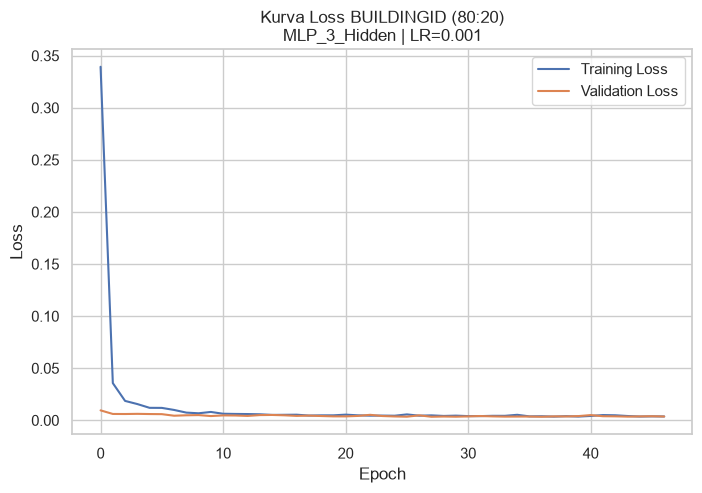

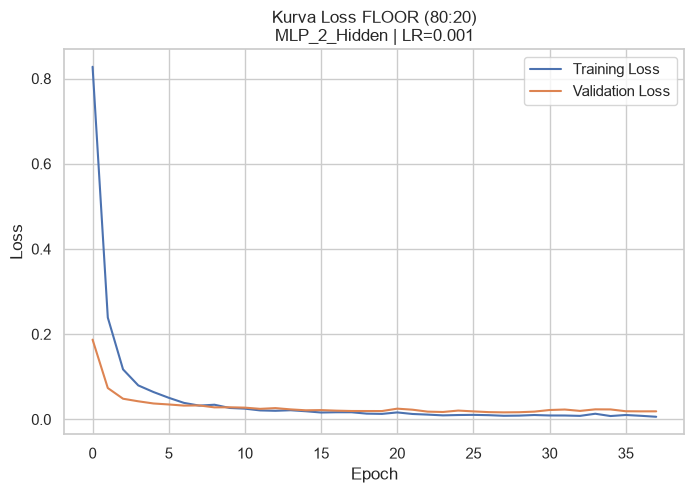

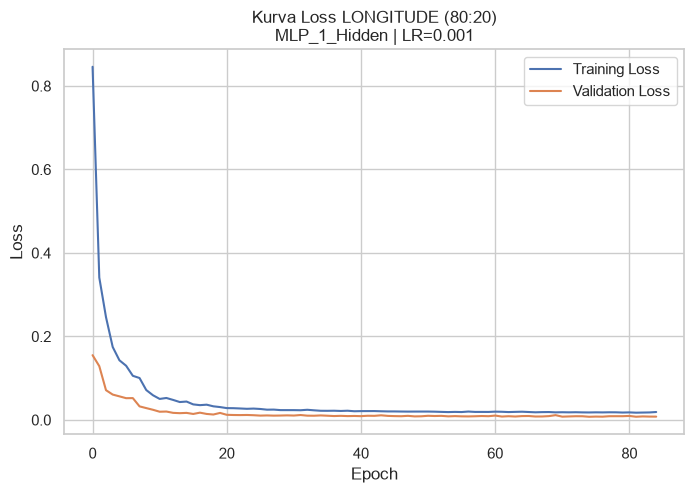

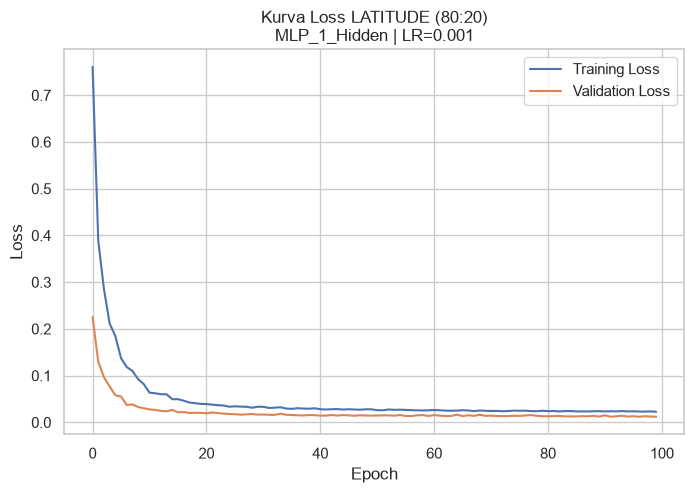

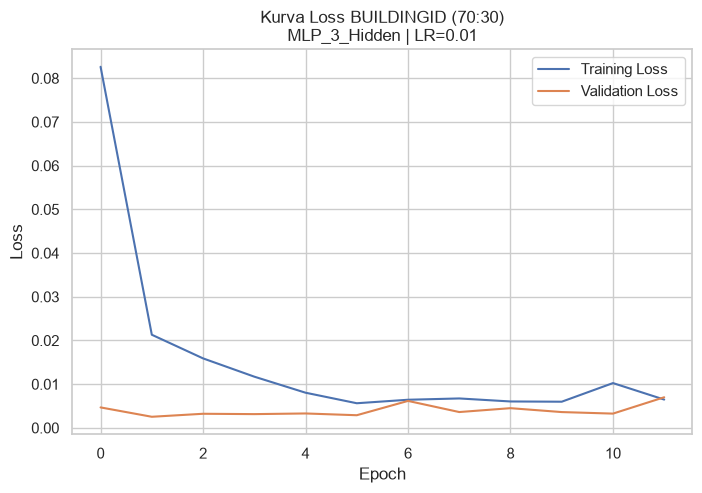

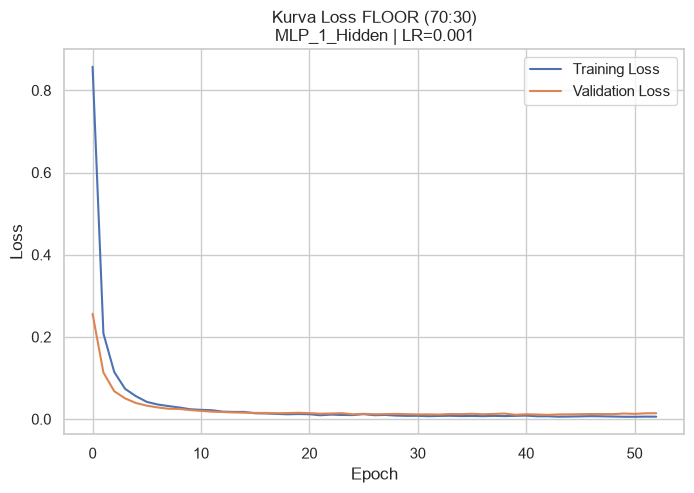

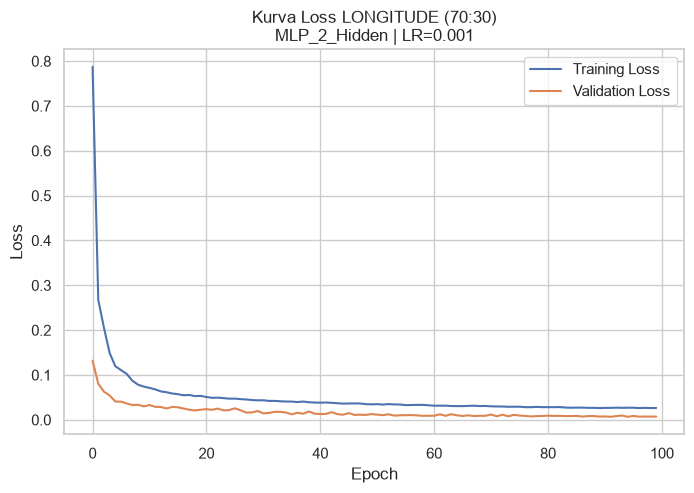

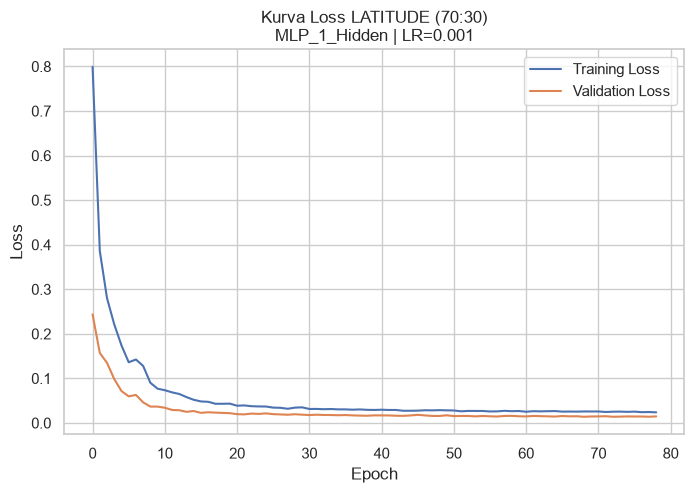

In [90]:
# KURVA LOSS MODEL MLP TERBAIK
import matplotlib.pyplot as plt

for scenario, best_models in [
    ("80:20", best_mlp_80),
    ("70:30", best_mlp_70)
]:

    for target, item in best_models.items():

        history = item["History"].history

        plt.figure(figsize=(8, 5))

        plt.plot(
            history["loss"],
            label="Training Loss"
        )

        plt.plot(
            history["val_loss"],
            label="Validation Loss"
        )

        plt.title(
            f"Kurva Loss {target} ({scenario})\n"
            f"{item['Architecture']} | "
            f"LR={item['Learning Rate']}"
        )

        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(True)
        plt.show()

### 72.10 Analisis Overfitting dan Underfitting

Analisis dilakukan dengan membandingkan kurva training loss dan validation loss pada setiap model MLP terpilih.

Secara umum, kurva menunjukkan penurunan loss yang cepat pada awal pelatihan, kemudian bergerak lebih stabil.

Pada beberapa model regresi, validation loss berada di bawah training loss. Kondisi ini dapat dipengaruhi oleh penggunaan Dropout selama pelatihan.

Tidak ditemukan pola kenaikan validation loss yang berlangsung secara konsisten ketika training loss terus menurun. Oleh karena itu, berdasarkan kurva yang diamati, belum terlihat indikasi overfitting yang kuat.

Evaluasi ini juga menunjukkan bahwa Early Stopping membantu menghentikan pelatihan ketika performa validation tidak lagi mengalami perbaikan.

### 72.11 Permutation Feature Importance Berbasis MLP

Permutation Feature Importance digunakan untuk mengukur kontribusi setiap fitur terhadap performa model MLP.

Analisis dilakukan pada model klasifikasi BUILDINGID skenario 80:20 yang menggunakan arsitektur MLP 3 Hidden dan learning rate 0.001.

Metode ini bekerja dengan mengacak nilai satu fitur pada data validation, kemudian mengukur perubahan performa model. Penurunan Macro F1 menunjukkan bahwa fitur tersebut memiliki kontribusi terhadap prediksi model.

Analisis hanya dilakukan pada data validation. Data testing tidak digunakan dalam proses perhitungan feature importance.

In [91]:
# PERMUTATION FEATURE IMPORTANCE MLP
from sklearn.metrics import f1_score

# Ambil model MLP terbaik
best_building_mlp = best_mlp_80["BUILDINGID"]["Model"]

X_val_importance = X_mlp_val_processed_80.copy()
y_val_importance = y_mlp_val_80["BUILDINGID"].to_numpy()

# Nama fitur setelah preprocessing
selected_feature_mask = (
    mlp_preprocessor_80
    .named_steps["selector"]
    .get_support()
)

selected_features = np.array(rssi_features)[selected_feature_mask]

assert X_val_importance.shape[1] == len(selected_features)

# Macro F1 baseline
baseline_predictions = np.argmax(
    best_building_mlp.predict(
        X_val_importance, verbose=0
    ),
    axis=1
)

baseline_f1 = f1_score(
    y_val_importance,
    baseline_predictions,
    average="macro"
)

print("Baseline Macro F1:", baseline_f1)

# Permutation
rng = np.random.RandomState(42)
n_repeats = 5

importance_results = []

for feature_idx, feature_name in enumerate(selected_features):

    score_drops = []

    for repeat in range(n_repeats):

        X_permuted = X_val_importance.copy()

        shuffled_values = X_permuted[:, feature_idx].copy()
        rng.shuffle(shuffled_values)

        X_permuted[:, feature_idx] = shuffled_values

        predictions = np.argmax(
            best_building_mlp.predict(
                X_permuted, verbose=0
            ),
            axis=1
        )

        permuted_f1 = f1_score(
            y_val_importance,
            predictions,
            average="macro"
        )

        score_drops.append(baseline_f1 - permuted_f1)

    importance_results.append({
        "Feature": feature_name,
        "Importance Mean": np.mean(score_drops),
        "Importance Std": np.std(score_drops)
    })

# Tabel hasil
permutation_importance_mlp = (
    pd.DataFrame(importance_results)
    .sort_values("Importance Mean", ascending=False)
    .reset_index(drop=True)
)

print("\n=== TOP 20 PERMUTATION FEATURE IMPORTANCE MLP ===")
display(permutation_importance_mlp.head(20))

print("\nJumlah fitur dianalisis:", len(selected_features))

Baseline Macro F1: 0.9975231056039736

=== TOP 20 PERMUTATION FEATURE IMPORTANCE MLP ===


,Feature,Importance Mean,Importance Std
0,WAP080,0.000319,0.000299
1,WAP011,0.000311,0.000196
2,WAP516,0.000248,0.000232
3,WAP070,0.000248,0.000232
4,WAP007,0.000239,0.000195
5,WAP036,0.000221,0.000184
6,WAP015,0.000203,0.000169
7,WAP122,0.000187,0.000422
8,WAP430,0.000186,0.000152
9,WAP209,0.000185,0.000151



Jumlah fitur dianalisis: 455


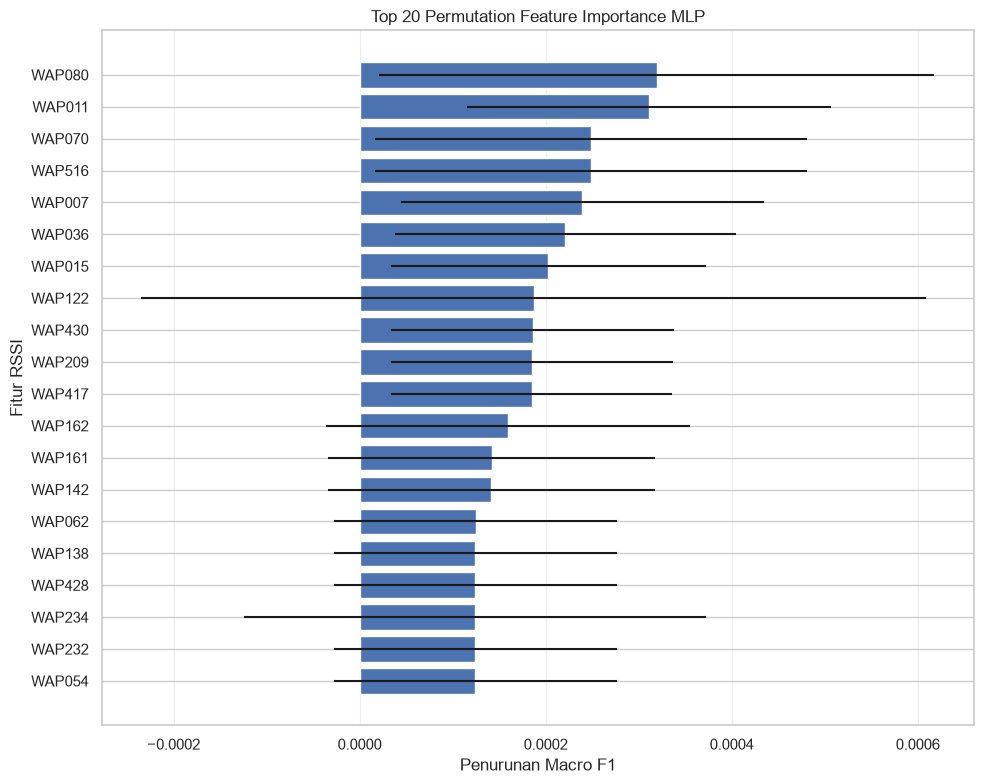

In [92]:
# VISUALISASI TOP 20 FITUR
top_features = permutation_importance_mlp.head(20).sort_values(
    "Importance Mean",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel("Penurunan Macro F1")
plt.ylabel("Fitur RSSI")
plt.title("Top 20 Permutation Feature Importance MLP")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 72.12 Perbandingan MLP dengan Model ML Terbaik

Tahap ini membandingkan performa model MLP/ANN dengan model Machine Learning terbaik dari Tahap 3. Berdasarkan hasil eksperimen sebelumnya, Random Forest menjadi model pembanding karena menghasilkan performa terbaik pada tugas klasifikasi dan regresi.

Perbandingan mencakup target BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE pada skenario pembagian data 80:20 dan 70:30.

Untuk klasifikasi, evaluasi menggunakan Accuracy dan Macro F1. Untuk regresi, evaluasi menggunakan MAE, RMSE, dan R².

Perbandingan dilakukan untuk mengetahui apakah MLP/ANN mampu memberikan performa yang lebih baik dibandingkan Random Forest.

In [93]:
# Memeriksa variabel hasil eksperimen Tahap 3 dan Tahap 4

print("=== VARIABEL HASIL ML TAHAP 3 ===")
for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "result", "hasil", "summary", "comparison", "best"
    ]):
        nilai = globals()[nama]
        if isinstance(nilai, pd.DataFrame):
            print(f"{nama}: {nilai.shape}")

print("\n=== VARIABEL HASIL MLP TAHAP 4 ===")
for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "result", "hasil", "summary", "comparison", "best"
    ]):
        nilai = globals()[nama]
        if isinstance(nilai, (dict, list)):
            print(f"{nama}: {type(nilai).__name__}, jumlah={len(nilai)}")

=== VARIABEL HASIL ML TAHAP 3 ===
classification_test_summary: (4, 6)
dbi_comparison: (2, 3)
dbscan_comparison: (4, 7)
final_clustering_comparison: (4, 10)
kmeans_comparison_df: (2, 5)
missing_summary: (0, 2)
pipeline_test_results: (8, 6)
results_building_70: (5, 8)
results_building_80: (5, 8)
results_floor_70: (5, 8)
results_floor_80: (5, 8)
results_latitude_70: (5, 10)
results_latitude_80: (5, 10)
results_longitude_70: (5, 10)
results_longitude_80: (5, 10)
rssi_comparison: (4, 6)
sentinel_summary: (520, 3)

=== VARIABEL HASIL MLP TAHAP 4 ===
best_mlp_70: dict, jumlah=4
best_mlp_80: dict, jumlah=4
best_models: dict, jumlah=4
comparison_results: list, jumlah=4
dbi_results: list, jumlah=2
dbscan_external_results: list, jumlah=4
dbscan_results: list, jumlah=4
importance_results: list, jumlah=455
kmeans_comparison: list, jumlah=2
mlp_results_70: dict, jumlah=4
mlp_results_80: dict, jumlah=4
outlier_results: list, jumlah=465
results: dict, jumlah=4
results_70: list, jumlah=8


### 72.14 Pemeriksaan Struktur Hasil Model

Tahap ini memeriksa struktur hasil evaluasi model Machine Learning pada Tahap 3 dan hasil pelatihan MLP pada Tahap 4.

Pemeriksaan mencakup:
1. Memastikan hasil model klasifikasi BUILDINGID dan FLOOR tersedia.
2. Memastikan hasil model regresi LONGITUDE dan LATITUDE tersedia.
3. Memeriksa hasil model terbaik MLP pada skenario pembagian data 80:20 dan 70:30.
4. Menyiapkan data untuk perbandingan performa model Machine Learning dan MLP.

Pemeriksaan ini dilakukan agar perbandingan menggunakan hasil eksperimen yang sesuai dengan target dan skenario pembagian data.

In [94]:
# Memeriksa kolom hasil Machine Learning Tahap 3
ml_result_vars = [
    "results_building_80",
    "results_floor_80",
    "results_longitude_80",
    "results_latitude_80",
    "results_building_70",
    "results_floor_70",
    "results_longitude_70",
    "results_latitude_70"
]

for nama in ml_result_vars:
    print(f"\n=== {nama} ===")
    display(globals()[nama].head())

# Memeriksa hasil MLP terbaik
print("\n=== BEST MLP 80:20 ===")
for target, detail in best_mlp_80.items():
    print(target, detail)

print("\n=== BEST MLP 70:30 ===")
for target, detail in best_mlp_70.items():
    print(target, detail)


=== results_building_80 ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.998119,0.000343,0.997612,0.998648,0.998124,0.000356,0.998119
1,KNN,0.997994,0.000425,0.997454,0.998560,0.998000,0.000429,0.998041
2,Logistic Regression,0.997806,0.000343,0.997538,0.998101,0.997812,0.000345,0.998119
3,Decision Tree,0.996990,0.000509,0.996255,0.997462,0.996850,0.000554,0.998119
4,SVM,0.995235,0.001698,0.994923,0.995611,0.995248,0.001708,0.998009



=== results_floor_80 ===


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996175,0.000999,0.996758,0.996582,0.996657,0.000746,0.998041
1,Logistic Regression,0.991535,0.002485,0.992103,0.992303,0.992191,0.002440,0.997680
2,SVM,0.988651,0.000725,0.989892,0.989023,0.989407,0.001135,0.995580
3,KNN,0.980375,0.001555,0.983262,0.980670,0.981908,0.001684,0.988573
4,Decision Tree,0.963634,0.004876,0.964221,0.965204,0.964663,0.003797,0.998041



=== results_longitude_80 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.365198,0.118325,8.398846,0.515308,0.995341,0.000624,1.621562,6.404335,0.997303
1,Decision Tree,3.733440,0.094166,11.334343,0.497858,0.991537,0.000780,0.616683,6.037843,0.997602
2,Ridge Regression,20.200352,0.381918,27.716535,0.397491,0.949489,0.001763,19.529408,26.853622,0.952612
3,Linear Regression,20.200996,0.381868,27.717657,0.397673,0.949485,0.001764,19.529119,26.853620,0.952612
4,SVR,29.948773,0.739488,48.521003,1.101286,0.845219,0.006199,29.560691,48.042206,0.848328


... (7 outputs left out)

,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.576021,0.123580,8.970499,0.707625,0.994674,0.000841,1.722139,6.665672,0.997079
1,Decision Tree,3.860384,0.255266,11.533500,1.128130,0.991170,0.001664,0.643486,6.277540,0.997409
2,Ridge Regression,20.399239,0.292205,27.901872,0.444808,0.948793,0.001951,19.530754,26.858567,0.952583
3,Linear Regression,20.400304,0.293108,27.903938,0.445469,0.948785,0.001953,19.530496,26.858562,0.952583
4,SVR,31.503387,1.155394,50.122438,1.410489,0.834724,0.008954,31.164573,49.758839,0.837259



=== results_latitude_70 ===


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.714224,0.125197,6.114057,0.560262,0.991610,0.001388,1.272332,4.486812,0.995514
1,Decision Tree,2.971924,0.257251,8.210508,0.950338,0.984803,0.003112,0.440261,4.178904,0.996108
2,Ridge Regression,13.119846,0.224139,17.735169,0.330954,0.929917,0.001807,12.553555,17.048193,0.935268
3,Linear Regression,13.121303,0.225148,17.737510,0.332926,0.929898,0.001808,12.553757,17.048187,0.935268
4,SVR,16.992724,0.776176,28.180177,1.266680,0.822997,0.012025,16.706933,27.904810,0.826573



=== BEST MLP 80:20 ===
BUILDINGID {'Target': 'BUILDINGID', 'Architecture': 'MLP_3_Hidden', 'Hidden Layers': '[64, 32, 16]', 'Learning Rate': 0.001, 'Optimizer': 'Adam', 'Epochs': 47, 'Train Loss': 0.003688341472297907, 'Validation Loss': 0.003392466576769948, 'Validation Accuracy': 0.9974921345710754, 'Model': <Sequential name=sequential_4, built=True>, 'History': <keras.src.callbacks.history.History object at 0x00000256C8D36C40>}
FLOOR {'Target': 'FLOOR', 'Architecture': 'MLP_2_Hidden', 'Hidden Layers': '[64, 32]', 'Learning Rate': 0.001, 'Optimizer': 'Adam', 'Epochs': 38, 'Train Loss': 0.006103029474616051, 'Validation Loss': 0.016435453668236732, 'Validation Accuracy': 0.9946708679199219, 'Model': <Sequential name=sequential_8, built=True>, 'History': <keras.src.callbacks.history.History object at 0x00000256CD46BA50>}
LONGITUDE {'Target': 'LONGITUDE', 'Architecture': 'MLP_1_Hidden', 'Hidden Layers': '[64]', 'Learning Rate': 0.001, 'Optimizer': 'Adam', 'Epochs': 85, 'Train Loss': 0.

### 72.15 Perbandingan Performa Machine Learning dan MLP

Tahap ini membandingkan model Machine Learning terbaik dari Tahap 3 dengan model MLP terbaik dari Tahap 4.

Perbandingan dilakukan pada empat target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE, dengan skenario pembagian data 80:20 dan 70:30.

Metrik evaluasi yang digunakan:
- Klasifikasi: Accuracy dan Macro F1.
- Regresi: MAE, RMSE, dan R².

Hasil perbandingan digunakan untuk mengetahui kemampuan MLP dalam menyelesaikan tugas klasifikasi dan regresi dibandingkan model Machine Learning terbaik.

Perlu diperhatikan bahwa hasil Machine Learning menggunakan rata-rata 5-fold cross-validation, sedangkan hasil MLP menggunakan data validasi. Perbedaan metode evaluasi ini menjadi batasan dalam interpretasi perbandingan.

### 72.16 Tabel Perbandingan ML dan MLP

Bagian ini menyajikan perbandingan performa model Machine Learning terbaik dari Tahap 3 dengan model MLP terbaik dari Tahap 4.

Perbandingan mencakup empat target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE, pada skenario pembagian data 80:20 dan 70:30.

Metrik klasifikasi yang digunakan adalah Accuracy dan Macro F1. Sementara itu, metrik regresi yang digunakan adalah MAE, RMSE, dan R².

Hasil perbandingan disajikan dalam bentuk tabel agar perbedaan performa kedua pendekatan lebih mudah dianalisis.

In [95]:
ml_result_vars = [
    "results_building_80",
    "results_floor_80",
    "results_longitude_80",
    "results_latitude_80",
    "results_building_70",
    "results_floor_70",
    "results_longitude_70",
    "results_latitude_70"
]

for nama in ml_result_vars:
    print(f"\n=== {nama} ===")
    print(globals()[nama].columns.tolist())
    display(globals()[nama].head(1))


=== results_building_80 ===
['Model', 'Accuracy Mean', 'Accuracy Std', 'Precision Macro Mean', 'Recall Macro Mean', 'F1 Macro Mean', 'F1 Macro Std', 'Train Accuracy Mean']


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.998119,0.000343,0.997612,0.998648,0.998124,0.000356,0.998119



=== results_floor_80 ===
['Model', 'Accuracy Mean', 'Accuracy Std', 'Precision Macro Mean', 'Recall Macro Mean', 'F1 Macro Mean', 'F1 Macro Std', 'Train Accuracy Mean']


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean,F1 Macro Std,Train Accuracy Mean
0,Random Forest,0.996175,0.000999,0.996758,0.996582,0.996657,0.000746,0.998041



=== results_longitude_80 ===
['Model', 'MAE Mean', 'MAE Std', 'RMSE Mean', 'RMSE Std', 'R2 Mean', 'R2 Std', 'Train MAE Mean', 'Train RMSE Mean', 'Train R2 Mean']


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.365198,0.118325,8.398846,0.515308,0.995341,0.000624,1.621562,6.404335,0.997303


... (6 outputs left out)


=== results_longitude_70 ===
['Model', 'MAE Mean', 'MAE Std', 'RMSE Mean', 'RMSE Std', 'R2 Mean', 'R2 Std', 'Train MAE Mean', 'Train RMSE Mean', 'Train R2 Mean']


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,3.576021,0.12358,8.970499,0.707625,0.994674,0.000841,1.722139,6.665672,0.997079



=== results_latitude_70 ===
['Model', 'MAE Mean', 'MAE Std', 'RMSE Mean', 'RMSE Std', 'R2 Mean', 'R2 Std', 'Train MAE Mean', 'Train RMSE Mean', 'Train R2 Mean']


,Model,MAE Mean,MAE Std,RMSE Mean,RMSE Std,R2 Mean,R2 Std,Train MAE Mean,Train RMSE Mean,Train R2 Mean
0,Random Forest,2.714224,0.125197,6.114057,0.560262,0.99161,0.001388,1.272332,4.486812,0.995514


In [96]:
import pandas as pd

def buat_tabel_perbandingan(split, hasil_ml, hasil_mlp, model_terbaik):
    records = []

    target_classification = ["BUILDINGID", "FLOOR"]
    target_regression = ["LONGITUDE", "LATITUDE"]

    for target in target_classification + target_regression:

        # Ambil hasil Machine Learning terbaik
        ml_row = hasil_ml[target].iloc[0]

        # Ambil informasi model MLP terbaik
        best_info = model_terbaik[target]

        # Cari baris evaluasi MLP sesuai arsitektur dan learning rate terbaik
        mlp_df = hasil_mlp[target]

        mlp_row = mlp_df[
            (mlp_df["Architecture"] == best_info["Architecture"]) &
            (mlp_df["Learning Rate"] == best_info["Learning Rate"])
        ].iloc[0]

        # Hasil klasifikasi
        if target in target_classification:
            records.append({
                "Split": split,
                "Target": target,
                "Model": "Random Forest",
                "Accuracy": ml_row["Accuracy Mean"],
                "Macro F1": ml_row["F1 Macro Mean"],
                "MAE": None,
                "RMSE": None,
                "R2": None
            })

            records.append({
                "Split": split,
                "Target": target,
                "Model": (
                    f'MLP {best_info["Architecture"]} '
                    f'(LR={best_info["Learning Rate"]})'
                ),
                "Accuracy": mlp_row["Accuracy"],
                "Macro F1": mlp_row["F1 Macro"],
                "MAE": None,
                "RMSE": None,
                "R2": None
            })

        # Hasil regresi
        else:
            records.append({
                "Split": split,
                "Target": target,
                "Model": "Random Forest",
                "Accuracy": None,
                "Macro F1": None,
                "MAE": ml_row["MAE Mean"],
                "RMSE": ml_row["RMSE Mean"],
                "R2": ml_row["R2 Mean"]
            })

            records.append({
                "Split": split,
                "Target": target,
                "Model": (
                    f'MLP {best_info["Architecture"]} '
                    f'(LR={best_info["Learning Rate"]})'
                ),
                "Accuracy": None,
                "Macro F1": None,
                "MAE": mlp_row["MAE"],
                "RMSE": mlp_row["RMSE"],
                "R2": mlp_row["R2"]
            })

    return pd.DataFrame(records)


# Hasil Machine Learning
hasil_ml_80 = {
    "BUILDINGID": results_building_80,
    "FLOOR": results_floor_80,
    "LONGITUDE": results_longitude_80,
    "LATITUDE": results_latitude_80
}

hasil_ml_70 = {
    "BUILDINGID": results_building_70,
    "FLOOR": results_floor_70,
    "LONGITUDE": results_longitude_70,
    "LATITUDE": results_latitude_70
}

# Membuat tabel perbandingan
tabel_perbandingan_80 = buat_tabel_perbandingan(
    "80:20",
    hasil_ml_80,
    mlp_evaluation_80,
    best_mlp_80
)

tabel_perbandingan_70 = buat_tabel_perbandingan(
    "70:30",
    hasil_ml_70,
    mlp_evaluation_70,
    best_mlp_70
)

# Menggabungkan kedua skenario
tabel_perbandingan = pd.concat(
    [tabel_perbandingan_80, tabel_perbandingan_70],
    ignore_index=True
)

# Menampilkan hasil
display(
    tabel_perbandingan.round(6)
)

,Split,Target,Model,Accuracy,Macro F1,MAE,RMSE,R2
0,80:20,BUILDINGID,Random Forest,0.998119,0.998124,NaN,NaN,NaN
1,80:20,BUILDINGID,MLP MLP_3_Hidden (LR=0.001),0.997492,0.997523,NaN,NaN,NaN
2,80:20,FLOOR,Random Forest,0.996175,0.996657,NaN,NaN,NaN
3,80:20,FLOOR,MLP MLP_2_Hidden (LR=0.001),0.994671,0.995463,NaN,NaN,NaN
4,80:20,LONGITUDE,Random Forest,NaN,NaN,3.365198,8.398846,0.995341
5,80:20,LONGITUDE,MLP MLP_1_Hidden (LR=0.001),NaN,NaN,6.563361,10.720884,0.992470
6,80:20,LATITUDE,Random Forest,NaN,NaN,2.534308,5.778748,0.992493
7,80:20,LATITUDE,MLP MLP_1_Hidden (LR=0.001),NaN,NaN,4.709509,7.316222,0.987922
8,70:30,BUILDINGID,Random Forest,0.997635,0.997641,NaN,NaN,NaN
9,70:30,BUILDINGID,MLP MLP_3_Hidden (LR=0.01),0.998925,0.998836,NaN,NaN,NaN


### 72.17 Analisis Hasil Perbandingan ML dan MLP

Berdasarkan tabel perbandingan, performa Machine Learning dan MLP menunjukkan hasil yang berbeda pada setiap target.

Pada tugas klasifikasi BUILDINGID dan FLOOR, Random Forest memperoleh hasil lebih baik pada skenario 80:20. Namun, MLP memperoleh nilai Accuracy dan Macro F1 lebih tinggi pada skenario 70:30.

Pada tugas regresi LONGITUDE dan LATITUDE, Random Forest menunjukkan performa lebih baik pada kedua skenario berdasarkan nilai MAE, RMSE, dan R². Random Forest menghasilkan kesalahan prediksi yang lebih rendah serta nilai R² yang lebih tinggi dibandingkan MLP.

Hasil tersebut menunjukkan bahwa performa model bergantung pada jenis target dan skenario pembagian data. MLP mampu memberikan hasil kompetitif pada klasifikasi, sedangkan Random Forest menunjukkan performa lebih baik pada regresi dalam eksperimen ini.

Perlu diperhatikan bahwa hasil Machine Learning berasal dari rata-rata 5-fold cross-validation, sedangkan hasil MLP berasal dari data validasi. Oleh karena itu, perbandingan ini perlu diinterpretasikan dengan mempertimbangkan perbedaan metode evaluasi tersebut.

### 72.18 Penentuan Model Terbaik

Skenario pembagian data 80:20 dipilih sebagai skenario utama untuk evaluasi akhir. Pemilihan ini mempertimbangkan proporsi data training yang lebih besar serta hasil evaluasi yang menunjukkan performa kompetitif pada sebagian besar target.

Skenario 70:30 tetap digunakan sebagai pembanding untuk menganalisis pengaruh proporsi data training dan testing terhadap performa model.

Penentuan model terbaik dilakukan secara terpisah untuk setiap target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE. Model yang telah ditentukan kemudian dievaluasi menggunakan data test dari skenario 80:20.

Data test hanya digunakan pada evaluasi akhir dan tidak dilibatkan dalam pemilihan model, preprocessing, maupun penyesuaian parameter.

### 72.19 Evaluasi Akhir Model pada Data Test

Evaluasi akhir dilakukan menggunakan data test dari skenario pembagian data 80:20. Tahap ini bertujuan mengukur kemampuan generalisasi model terbaik pada data yang belum digunakan selama proses pelatihan dan pemilihan model.

Model dievaluasi secara terpisah untuk setiap target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Berdasarkan hasil perbandingan sebelumnya, model kandidat yang digunakan adalah Random Forest untuk BUILDINGID, LONGITUDE, dan LATITUDE, serta MLP untuk FLOOR.

Metrik evaluasi klasifikasi meliputi Accuracy, Precision, Recall, dan Macro F1. Sementara itu, evaluasi regresi menggunakan MAE, RMSE, dan R².

Seluruh preprocessing dan pelatihan ulang model dilakukan menggunakan data training 80%. Data test hanya digunakan untuk menghasilkan prediksi dan menghitung metrik evaluasi akhir.

In [97]:
# Memeriksa variabel model dan pipeline yang tersedia
print("=== Variabel terkait model ===")

for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "model", "pipeline", "best_mlp", "scaler", "preprocess"
    ]):
        objek = globals()[nama]
        if not callable(objek):
            print(nama, ":", type(objek).__name__)

print("\n=== Fungsi preprocessing ===")
print(build_preprocessing_pipeline)

=== Variabel terkait model ===
best_mlp_70 : dict
best_mlp_80 : dict
best_models : dict
classification_models_building : dict
classification_models_floor : dict
clustering_preprocessor : Pipeline
comparison_pipeline_test : Pipeline
dbscan_models : dict
kmeans_models : dict
mlp_preprocessor_70 : Pipeline
mlp_preprocessor_80 : Pipeline
model : DBSCAN
model_building_70 : Pipeline
model_building_80 : Pipeline
model_floor_70 : Pipeline
model_floor_80 : Pipeline
model_latitude_70 : Pipeline
model_latitude_80 : Pipeline
model_longitude_70 : Pipeline
model_longitude_80 : Pipeline
model_name : str
pipeline : Pipeline
pipeline_building_test : Pipeline
pipeline_regression_test : Pipeline
pipeline_test_70 : DataFrame
pipeline_test_results : DataFrame
polynomial_model : dict
preprocessing_configs : list
regression_models : dict
scaler : str
scaler_70 : StandardScaler
scaler_80 : StandardScaler
scaler_building_70 : DataFrame
scaler_building_80 : DataFrame
scaler_floor_70 : DataFrame
scaler_floor_80 

#### 72.19.1 Pemeriksaan Model dan Data Test

Sebelum melakukan evaluasi akhir, dilakukan pemeriksaan terhadap model dan pipeline preprocessing yang telah dibangun pada skenario pembagian data 80:20.

Pemeriksaan ini bertujuan memastikan bahwa:
- Data training dan data test memiliki ukuran yang sesuai.
- Pipeline Machine Learning untuk setiap target telah tersedia.
- Model MLP terbaik untuk setiap target telah tersimpan.
- Pipeline preprocessing MLP telah tersedia dan siap digunakan.

Pemeriksaan dilakukan untuk memastikan seluruh komponen evaluasi akhir dapat digunakan sesuai prosedur penelitian. Data test tetap tidak digunakan untuk proses fitting maupun pemilihan model.

In [98]:
print("=== UKURAN DATA ===")
print("X_train_80:", X_train_80.shape)
print("X_test_80 :", X_test_80.shape)

print("\n=== PIPELINE MACHINE LEARNING ===")

pipeline_vars = [
    "model_building_80",
    "model_floor_80",
    "model_longitude_80",
    "model_latitude_80"
]

for nama in pipeline_vars:
    pipe = globals()[nama]
    print(f"\n{nama}")
    print("Tipe:", type(pipe).__name__)
    print("Langkah:", list(pipe.named_steps.keys()))

print("\n=== BEST MODELS ML ===")
print("Keys:", best_models.keys())

print("\n=== BEST MLP 80 ===")

for target, detail in best_mlp_80.items():
    print(f"\nTarget: {target}")
    print("Architecture:", detail["Architecture"])
    print("Learning Rate:", detail["Learning Rate"])
    print("Optimizer:", detail["Optimizer"])
    print("Epochs:", detail["Epochs"])
    print("Model:", type(detail["Model"]).__name__)

print("\n=== MLP PREPROCESSOR ===")
print("Langkah:", list(mlp_preprocessor_80.named_steps.keys()))

=== UKURAN DATA ===
X_train_80: (15949, 520)
X_test_80 : (3988, 520)

=== PIPELINE MACHINE LEARNING ===

model_building_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

model_floor_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

model_longitude_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

model_latitude_80
Tipe: Pipeline
Langkah: ['preprocessing', 'model']

=== BEST MODELS ML ===
Keys: dict_keys(['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE'])

=== BEST MLP 80 ===

Target: BUILDINGID
Architecture: MLP_3_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 47
Model: Sequential

Target: FLOOR
Architecture: MLP_2_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 38
Model: Sequential

Target: LONGITUDE
Architecture: MLP_1_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 85
Model: Sequential

Target: LATITUDE
Architecture: MLP_1_Hidden
Learning Rate: 0.001
Optimizer: Adam
Epochs: 100
Model: Sequential

=== MLP PREPROCESSOR ===
Langkah: ['sentinel_replacement', 's

#### 72.19.2 Pemeriksaan Detail Model Terbaik

Pemeriksaan detail model dilakukan untuk memastikan algoritma dan konfigurasi model terbaik pada setiap target telah tersimpan dengan benar.

Pemeriksaan mencakup jenis model, arsitektur MLP, learning rate, optimizer, serta konfigurasi model Machine Learning yang akan digunakan pada evaluasi akhir.

In [99]:
print("=== BEST MODELS MACHINE LEARNING ===")

for target, detail in best_models.items():
    print(f"\nTarget: {target}")
    print("Detail:", detail)

print("\n=== BEST MLP 80:20 ===")

for target, detail in best_mlp_80.items():
    print(f"\nTarget: {target}")
    print("Architecture:", detail["Architecture"])
    print("Hidden Layers:", detail["Hidden Layers"])
    print("Learning Rate:", detail["Learning Rate"])
    print("Optimizer:", detail["Optimizer"])
    print("Epochs:", detail["Epochs"])
    print("Model:", type(detail["Model"]).__name__)

=== BEST MODELS MACHINE LEARNING ===

Target: BUILDINGID
Detail: {'Target': 'BUILDINGID', 'Architecture': 'MLP_3_Hidden', 'Hidden Layers': '[64, 32, 16]', 'Learning Rate': 0.01, 'Optimizer': 'Adam', 'Epochs': 12, 'Train Loss': 0.006471036002039909, 'Validation Loss': 0.0025369662325829268, 'Validation Accuracy': 0.9989250898361206, 'Model': <Sequential name=sequential_29, built=True>, 'History': <keras.src.callbacks.history.History object at 0x000002572E435010>}

Target: FLOOR
Detail: {'Target': 'FLOOR', 'Architecture': 'MLP_1_Hidden', 'Hidden Layers': '[64]', 'Learning Rate': 0.001, 'Optimizer': 'Adam', 'Epochs': 53, 'Train Loss': 0.005836534779518843, 'Validation Loss': 0.010283968411386013, 'Validation Accuracy': 0.9967753291130066, 'Model': <Sequential name=sequential_30, built=True>, 'History': <keras.src.callbacks.history.History object at 0x000002572E6B6820>}

Target: LONGITUDE
Detail: {'Target': 'LONGITUDE', 'Architecture': 'MLP_2_Hidden', 'Hidden Layers': '[64, 32]', 'Learning

#### 72.19.3 Pemeriksaan Nama Variabel Target

Pemeriksaan nama variabel target dilakukan untuk memastikan kesesuaian variabel target training dan testing pada skenario pembagian data 80:20.

Tahap ini juga memastikan bahwa variabel yang digunakan dalam evaluasi akhir sesuai dengan struktur notebook dan hasil preprocessing yang telah dilakukan sebelumnya.

In [101]:
print("=== VARIABEL TARGET YANG TERSEDIA ===")

for nama in sorted(globals()):
    if nama.lower().startswith("y_") and "80" in nama.lower():
        obj = globals()[nama]
        print(nama, ":", getattr(obj, "shape", type(obj).__name__))

print("\n=== VARIABEL TARGET BUILDING DAN FLOOR ===")

for nama in sorted(globals()):
    if any(kata in nama.lower() for kata in [
        "building", "floor", "longitude", "latitude"
    ]) and nama.lower().startswith("y_"):
        obj = globals()[nama]
        print(nama, ":", getattr(obj, "shape", type(obj).__name__))

=== VARIABEL TARGET YANG TERSEDIA ===
y_building_80 : (15949,)
y_floor_80 : (15949,)
y_latitude_80 : (15949,)
y_longitude_80 : (15949,)
y_mlp_train_80 : (12759, 4)
y_mlp_val_80 : (3190, 4)
y_reg_scalers_80 : dict
y_test_80 : (3988, 4)
y_train_80 : (15949, 4)

=== VARIABEL TARGET BUILDING DAN FLOOR ===
y_building_70 : (13955,)
y_building_80 : (15949,)
y_cluster_building : (19937,)
y_cluster_floor : (19937,)
y_floor_70 : (13955,)
y_floor_80 : (15949,)
y_latitude_70 : (13955,)
y_latitude_80 : (15949,)
y_longitude_70 : (13955,)
y_longitude_80 : (15949,)


#### 72.19.4 Pemeriksaan Kesesuaian Data Training dan Testing

Tahap ini memeriksa kesesuaian jumlah data fitur dan target pada skenario pembagian 80:20.

Pemeriksaan dilakukan untuk memastikan bahwa setiap target memiliki jumlah observasi yang sesuai dengan data fitur training dan testing. Hal ini diperlukan agar proses evaluasi akhir dapat berjalan dengan benar tanpa mengubah pembagian data yang telah ditetapkan.

In [102]:
print("=== PEMERIKSAAN DATA TRAINING DAN TESTING ===")

target_train = {
    "BUILDINGID": y_building_80,
    "FLOOR": y_floor_80,
    "LONGITUDE": y_longitude_80,
    "LATITUDE": y_latitude_80
}

for target, y in target_train.items():
    print(f"\nTarget: {target}")
    print("X Training:", X_train_80.shape)
    print("y Training:", y.shape)
    print("Jumlah sesuai:", len(X_train_80) == len(y))

print("\nX Testing:", X_test_80.shape)
print("y Testing:", y_test_80.shape)
print("Jumlah sesuai:", len(X_test_80) == len(y_test_80))

=== PEMERIKSAAN DATA TRAINING DAN TESTING ===

Target: BUILDINGID
X Training: (15949, 520)
y Training: (15949,)
Jumlah sesuai: True

Target: FLOOR
X Training: (15949, 520)
y Training: (15949,)
Jumlah sesuai: True

Target: LONGITUDE
X Training: (15949, 520)
y Training: (15949,)
Jumlah sesuai: True

Target: LATITUDE
X Training: (15949, 520)
y Training: (15949,)
Jumlah sesuai: True

X Testing: (3988, 520)
y Testing: (3988, 4)
Jumlah sesuai: True


#### 72.19.5 Evaluasi Akhir Machine Learning

Evaluasi akhir Machine Learning dilakukan menggunakan pipeline terbaik untuk setiap target pada skenario pembagian data 80:20.

Pipeline yang telah dilatih menggunakan data training diterapkan pada data test untuk menghasilkan prediksi. Evaluasi klasifikasi dilakukan menggunakan Accuracy, Precision, Recall, dan Macro F1. Sementara itu, evaluasi regresi menggunakan MAE, RMSE, dan R².

Tahap ini bertujuan mengukur kemampuan generalisasi model Machine Learning terhadap data yang belum digunakan selama proses pelatihan.

In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Pipeline Machine Learning terbaik
ml_pipelines = {
    "BUILDINGID": model_building_80,
    "FLOOR": model_floor_80,
    "LONGITUDE": model_longitude_80,
    "LATITUDE": model_latitude_80
}

# Target aktual
y_test_targets = {
    "BUILDINGID": y_test_80["BUILDINGID"],
    "FLOOR": y_test_80["FLOOR"],
    "LONGITUDE": y_test_80["LONGITUDE"],
    "LATITUDE": y_test_80["LATITUDE"]
}

ml_test_results = []

for target, pipeline in ml_pipelines.items():

    # Prediksi menggunakan pipeline yang sudah dilatih
    y_true = y_test_targets[target]
    y_pred = pipeline.predict(X_test_80)

    if target in ["BUILDINGID", "FLOOR"]:
        ml_test_results.append({
            "Target": target,
            "Model": "Random Forest",
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision Macro": precision_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "Recall Macro": recall_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "F1 Macro": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            )
        })

    else:
        ml_test_results.append({
            "Target": target,
            "Model": "Random Forest",
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)
        })

ml_test_results = pd.DataFrame(ml_test_results)

display(ml_test_results.round(6))

,Target,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Random Forest,0.997743,0.997140,0.998419,0.997772,NaN,NaN,NaN
1,FLOOR,Random Forest,0.997743,0.998062,0.998096,0.998077,NaN,NaN,NaN
2,LONGITUDE,Random Forest,NaN,NaN,NaN,NaN,4.872336e+06,4.872336e+06,-1.555143e+09
3,LATITUDE,Random Forest,NaN,NaN,NaN,NaN,2.458064e+00,5.452109e+00,9.934090e-01


#### 72.19.6 Pemeriksaan Anomali Hasil Evaluasi

Pemeriksaan anomali dilakukan untuk memastikan kesesuaian antara target aktual dan hasil prediksi model pada data test.

Pemeriksaan difokuskan pada nilai target LONGITUDE yang menunjukkan kesalahan prediksi sangat besar, serta kesamaan nilai Accuracy pada BUILDINGID dan FLOOR.

Tahap ini bertujuan mengidentifikasi kemungkinan ketidaksesuaian pemetaan target, skala nilai, atau penggunaan pipeline sebelum hasil evaluasi akhir ditetapkan.

In [104]:
print("=== KOLOM DAN NILAI TARGET TEST ===")
print("Kolom:", y_test_80.columns.tolist())
display(y_test_80.describe())

print("\n=== RENTANG TARGET TRAINING ===")
target_train = {
    "BUILDINGID": y_building_80,
    "FLOOR": y_floor_80,
    "LONGITUDE": y_longitude_80,
    "LATITUDE": y_latitude_80
}

for target, y in target_train.items():
    print(f"\n{target}")
    print("Min:", y.min())
    print("Max:", y.max())
    print("Mean:", y.mean())

print("\n=== PERBANDINGAN AKTUAL DAN PREDIKSI ===")

for target, pipeline in ml_pipelines.items():
    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    print(f"\n{target}")
    print("Aktual (5 pertama):", y_true.iloc[:5].tolist())
    print("Prediksi (5 pertama):", np.asarray(y_pred)[:5].tolist())
    print("Min aktual:", y_true.min())
    print("Max aktual:", y_true.max())
    print("Min prediksi:", np.min(y_pred))
    print("Max prediksi:", np.max(y_pred))

=== KOLOM DAN NILAI TARGET TEST ===
Kolom: ['BUILDINGID', 'FLOOR', 'LONGITUDE', 'LATITUDE']


,BUILDINGID,FLOOR,LONGITUDE,LATITUDE
count,3988.000000,3988.000000,3988.000000,3.988000e+03
mean,1.212638,1.674273,-7464.134200,4.864872e+06
std,0.833173,1.223042,123.568156,6.716747e+01
min,0.000000,0.000000,-7691.338400,4.864746e+06
25%,0.000000,1.000000,-7594.382325,4.864821e+06
50%,1.000000,2.000000,-7422.316300,4.864853e+06
75%,2.000000,3.000000,-7356.978100,4.864930e+06
max,2.000000,4.000000,-7300.818990,4.865017e+06



=== RENTANG TARGET TRAINING ===

BUILDINGID
Min: 0
Max: 2
Mean: 1.212866010408176

FLOOR
Min: 0
Max: 4
Mean: 1.6746504483039688

LONGITUDE
Min: -7691.338399998844
Max: -7300.818990092725
Mean: -7464.311390403691

LATITUDE
Min: 4864745.745015971
Max: 4865016.687799998
Mean: 4864870.617653751

=== PERBANDINGAN AKTUAL DAN PREDIKSI ===

BUILDINGID
Aktual (5 pertama): [1, 2, 1, 0, 2]
Prediksi (5 pertama): [1, 2, 1, 0, 2]
Min aktual: 0
Max aktual: 2
Min prediksi: 0
Max prediksi: 2

FLOOR
Aktual (5 pertama): [1, 1, 0, 1, 3]
Prediksi (5 pertama): [1, 1, 0, 1, 3]
Min aktual: 0
Max aktual: 4
Min prediksi: 0
Max prediksi: 4

LONGITUDE
Aktual (5 pertama): [-7568.8610000014305, -7367.458799999207, -7445.557873841375, -7601.616200000048, -7336.700399998575]
Prediksi (5 pertama): [4864875.479530597, 4864844.176835054, 4864826.492918476, 4864976.240386702, 4864762.468164667]
Min aktual: -7691.338399998844
Max aktual: -7300.818990092725
Min prediksi: 4864749.7176379
Max prediksi: 4865016.583415516

LA

#### 72.19.7 Pemeriksaan Kesesuaian Model dan Target

Pemeriksaan ini dilakukan untuk memastikan setiap pipeline Machine Learning menggunakan target yang sesuai dengan tugas klasifikasi atau regresi.

Pemeriksaan difokuskan pada kesesuaian model, target aktual, dan hasil prediksi. Langkah ini diperlukan untuk mengidentifikasi kemungkinan kesalahan pemetaan target sebelum hasil evaluasi akhir ditetapkan.

In [105]:
print("=== PEMERIKSAAN PIPELINE DAN MODEL ===")

for target, pipeline in ml_pipelines.items():
    print(f"\nTARGET: {target}")
    print("Pipeline:", pipeline)
    print("Model:", pipeline.named_steps["model"])

print("\n=== PEMERIKSAAN TARGET TRAINING ===")

for target, y in target_train.items():
    print(f"\n{target}")
    print("5 nilai pertama:", y.iloc[:5].tolist())

print("\n=== PEMERIKSAAN PREDIKSI TEST ===")

for target, pipeline in ml_pipelines.items():
    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    print(f"\nTARGET: {target}")
    print("Aktual   :", y_true.iloc[:5].tolist())
    print("Prediksi :", np.asarray(y_pred)[:5].tolist())

=== PEMERIKSAAN PIPELINE DAN MODEL ===

TARGET: BUILDINGID
Pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('sentinel_replacement',
                                  FunctionTransformer(func=<function replace_sentinel at 0x0000025667AB84A0>)),
                                 ('selector', VarianceThreshold()),
                                 ('scaler', StandardScaler())])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])
Model: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

TARGET: FLOOR
Pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('sentinel_replacement',
                                  FunctionTransformer(func=<function replace_sentinel at 0x0000025667AB84A0>)),
                                 ('selector', VarianceThreshold()),
                                 ('scaler', StandardScaler())])),

#### 72.19.8 Pemeriksaan Khusus Model Regresi

Pemeriksaan khusus dilakukan terhadap model regresi LONGITUDE dan LATITUDE karena hasil evaluasi awal menunjukkan perbedaan nilai kesalahan prediksi yang cukup besar.

Pemeriksaan mencakup jenis algoritma, rentang nilai aktual, rentang nilai prediksi, serta perbandingan beberapa hasil prediksi. Langkah ini bertujuan memastikan kesesuaian model regresi dengan target koordinat yang digunakan.

In [106]:
for target in ["LONGITUDE", "LATITUDE"]:

    pipeline = ml_pipelines[target]
    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    print(f"\n{'='*15} {target} {'='*15}")

    print("Jenis model:")
    print(type(pipeline.named_steps["model"]).__name__)

    print("\nRentang aktual:")
    print("Min:", y_true.min())
    print("Max:", y_true.max())

    print("\nRentang prediksi:")
    print("Min:", np.min(y_pred))
    print("Max:", np.max(y_pred))

    print("\nLima pasangan aktual dan prediksi:")
    print(pd.DataFrame({
        "Aktual": y_true.iloc[:5].values,
        "Prediksi": np.asarray(y_pred)[:5]
    }).round(6))

    print("\nMAE:", mean_absolute_error(y_true, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("R2:", r2_score(y_true, y_pred))


=============== LONGITUDE ===============
Jenis model:
RandomForestRegressor

Rentang aktual:
Min: -7691.338399998844
Max: -7300.818990092725

Rentang prediksi:
Min: 4864749.717637903
Max: 4865016.583415516

Lima pasangan aktual dan prediksi:
        Aktual      Prediksi
0 -7568.861000  4.864875e+06
1 -7367.458800  4.864844e+06
2 -7445.557874  4.864826e+06
3 -7601.616200  4.864976e+06
4 -7336.700400  4.864762e+06

MAE: 4872336.187171384
RMSE: 4872336.190654864
R2: -1555142819.6670456

=============== LATITUDE ===============
Jenis model:
RandomForestRegressor

Rentang aktual:
Min: 4864745.745015971
Max: 4865016.687799998

Rentang prediksi:
Min: 4864749.7176379
Max: 4865016.583415516

Lima pasangan aktual dan prediksi:
         Aktual      Prediksi
0  4.864876e+06  4.864875e+06
1  4.864842e+06  4.864844e+06
2  4.864827e+06  4.864826e+06
3  4.864980e+06  4.864976e+06
4  4.864764e+06  4.864762e+06

MAE: 2.4580644456192817
RMSE: 5.452108988797859
R2: 0.9934094753474451


#### 72.19.9 Perbaikan Model LONGITUDE

Berdasarkan pemeriksaan hasil prediksi, ditemukan ketidaksesuaian antara rentang nilai aktual dan prediksi LONGITUDE. Prediksi model LONGITUDE menunjukkan rentang nilai yang menyerupai target LATITUDE.

Untuk mengatasi masalah tersebut, pipeline LONGITUDE dilatih ulang menggunakan target LONGITUDE yang benar. Proses pelatihan hanya menggunakan data training pada skenario 80:20, dengan konfigurasi model yang sama seperti eksperimen sebelumnya.

Data test tidak digunakan dalam proses pelatihan ulang maupun penyesuaian model.

In [107]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Membuat salinan pipeline LONGITUDE
pipeline_longitude_baru = clone(model_longitude_80)

# Melatih ulang menggunakan target LONGITUDE yang benar
pipeline_longitude_baru.fit(
    X_train_80,
    y_longitude_80
)

# Mengganti pipeline LONGITUDE dengan pipeline hasil perbaikan
model_longitude_80 = pipeline_longitude_baru
ml_pipelines["LONGITUDE"] = model_longitude_80

# Evaluasi pada data test
y_true_longitude = y_test_80["LONGITUDE"]
y_pred_longitude = model_longitude_80.predict(X_test_80)

print("=== HASIL PERBAIKAN MODEL LONGITUDE ===")
print("Rentang aktual:",
      y_true_longitude.min(), "sampai", y_true_longitude.max())

print("Rentang prediksi:",
      y_pred_longitude.min(), "sampai", y_pred_longitude.max())

print("\nMAE:",
      mean_absolute_error(y_true_longitude, y_pred_longitude))

print("RMSE:",
      np.sqrt(mean_squared_error(y_true_longitude, y_pred_longitude)))

print("R2:",
      r2_score(y_true_longitude, y_pred_longitude))

=== HASIL PERBAIKAN MODEL LONGITUDE ===
Rentang aktual: -7691.338399998844 sampai -7300.818990092725
Rentang prediksi: -7691.338399998844 sampai -7301.071064889989

MAE: 2.8426375921018785
RMSE: 7.40275808177879
R2: 0.9964100954615166


#### 72.19.10 Pembaruan Hasil Evaluasi Machine Learning

Setelah perbaikan pipeline LONGITUDE, evaluasi ulang dilakukan untuk memperbarui hasil pengujian model Machine Learning pada data test.

Evaluasi menggunakan pipeline yang telah dilatih pada data training 80:20. Hasil evaluasi sebelumnya yang mengalami ketidaksesuaian target LONGITUDE tidak digunakan kembali.

Metrik evaluasi tetap mencakup Accuracy, Precision, Recall, dan Macro F1 untuk klasifikasi, serta MAE, RMSE, dan R² untuk regresi.

In [108]:
ml_test_results = []

for target, pipeline in ml_pipelines.items():

    y_true = y_test_80[target]
    y_pred = pipeline.predict(X_test_80)

    if target in ["BUILDINGID", "FLOOR"]:
        ml_test_results.append({
            "Target": target,
            "Model": "Random Forest",
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision Macro": precision_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "Recall Macro": recall_score(
                y_true, y_pred, average="macro", zero_division=0
            ),
            "F1 Macro": f1_score(
                y_true, y_pred, average="macro", zero_division=0
            )
        })

    else:
        ml_test_results.append({
            "Target": target,
            "Model": "Random Forest",
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)
        })

ml_test_results = pd.DataFrame(ml_test_results)

display(ml_test_results.round(6))

,Target,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Random Forest,0.997743,0.997140,0.998419,0.997772,NaN,NaN,NaN
1,FLOOR,Random Forest,0.997743,0.998062,0.998096,0.998077,NaN,NaN,NaN
2,LONGITUDE,Random Forest,NaN,NaN,NaN,NaN,2.842638,7.402758,0.996410
3,LATITUDE,Random Forest,NaN,NaN,NaN,NaN,2.458064,5.452109,0.993409


#### 72.19.11 Evaluasi Akhir MLP untuk Target FLOOR

Evaluasi akhir MLP dilakukan pada target FLOOR menggunakan model terbaik dari skenario pembagian data 80:20.

Model MLP yang digunakan merupakan model dengan arsitektur dan learning rate terbaik berdasarkan hasil evaluasi validasi sebelumnya. Data test ditransformasikan menggunakan pipeline preprocessing MLP yang telah di-fit pada data training internal.

Evaluasi dilakukan menggunakan Accuracy, Precision, Recall, dan Macro F1 untuk mengukur kemampuan model dalam mengklasifikasikan posisi lantai pada data yang belum pernah digunakan selama pelatihan.

In [109]:
# Mengambil model MLP FLOOR terbaik pada split 80:20
best_floor_mlp = best_mlp_80["FLOOR"]["Model"]

# Transformasi data test menggunakan preprocessing MLP yang sudah fit
X_test_mlp_80 = mlp_preprocessor_80.transform(X_test_80)

# Prediksi probabilitas kelas
y_pred_proba_floor = best_floor_mlp.predict(
    X_test_mlp_80,
    verbose=0
)

# Mengubah probabilitas menjadi label kelas
y_pred_floor_mlp = np.argmax(y_pred_proba_floor, axis=1)

# Target aktual
y_true_floor = y_test_80["FLOOR"].to_numpy()

# Evaluasi MLP FLOOR
mlp_floor_test_results = pd.DataFrame([{
    "Target": "FLOOR",
    "Model": "MLP",
    "Architecture": best_mlp_80["FLOOR"]["Architecture"],
    "Learning Rate": best_mlp_80["FLOOR"]["Learning Rate"],
    "Accuracy": accuracy_score(y_true_floor, y_pred_floor_mlp),
    "Precision Macro": precision_score(
        y_true_floor,
        y_pred_floor_mlp,
        average="macro",
        zero_division=0
    ),
    "Recall Macro": recall_score(
        y_true_floor,
        y_pred_floor_mlp,
        average="macro",
        zero_division=0
    ),
    "F1 Macro": f1_score(
        y_true_floor,
        y_pred_floor_mlp,
        average="macro",
        zero_division=0
    )
}])

display(mlp_floor_test_results.round(6))

,Target,Model,Architecture,Learning Rate,Accuracy,Precision Macro,Recall Macro,F1 Macro
0,FLOOR,MLP,MLP_2_Hidden,0.001,0.99348,0.993192,0.994413,0.993789


#### 72.19.12 Penetapan Model untuk Evaluasi Akhir

Berdasarkan hasil evaluasi dan cross-validation pada tahap sebelumnya, Random Forest ditetapkan sebagai model terpilih untuk keempat target, yaitu BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

Pada target BUILDINGID, Random Forest menunjukkan performa klasifikasi yang tinggi. Pada target FLOOR, Random Forest juga memperoleh hasil cross-validation lebih baik dibandingkan MLP.

Untuk target LONGITUDE dan LATITUDE, Random Forest menunjukkan performa regresi yang baik berdasarkan nilai MAE, RMSE, dan R².

Model terpilih selanjutnya digunakan untuk menyajikan hasil evaluasi akhir pada data test skenario 80:20.

#### 72.19.13 Tabel Hasil Evaluasi Akhir

Tabel berikut menyajikan hasil evaluasi akhir model Random Forest pada data test skenario 80:20 untuk empat target penelitian.

Evaluasi klasifikasi menggunakan Accuracy, Precision Macro, Recall Macro, dan Macro F1. Evaluasi regresi menggunakan MAE, RMSE, dan R².

In [110]:
# Menampilkan hasil evaluasi akhir Random Forest
tabel_evaluasi_akhir = ml_test_results.copy()

display(tabel_evaluasi_akhir.round(6))

,Target,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,MAE,RMSE,R2
0,BUILDINGID,Random Forest,0.997743,0.997140,0.998419,0.997772,NaN,NaN,NaN
1,FLOOR,Random Forest,0.997743,0.998062,0.998096,0.998077,NaN,NaN,NaN
2,LONGITUDE,Random Forest,NaN,NaN,NaN,NaN,2.842638,7.402758,0.996410
3,LATITUDE,Random Forest,NaN,NaN,NaN,NaN,2.458064,5.452109,0.993409


#### 72.19.14 Analisis Hasil Evaluasi Akhir

Berdasarkan hasil evaluasi pada data test skenario 80:20, Random Forest menunjukkan performa yang tinggi pada seluruh target penelitian.

Pada target BUILDINGID, model memperoleh Accuracy sebesar 0.997743 dan Macro F1 sebesar 0.997772. Hasil ini menunjukkan kemampuan model yang sangat baik dalam mengklasifikasikan gedung.

Pada target FLOOR, model memperoleh Accuracy sebesar 0.997743 dan Macro F1 sebesar 0.998077. Hasil tersebut menunjukkan bahwa Random Forest mampu mengklasifikasikan lantai dengan tingkat ketepatan yang tinggi.

Pada target LONGITUDE, model memperoleh MAE sebesar 2.842638, RMSE sebesar 7.402758, dan R² sebesar 0.996410. Sementara itu, pada target LATITUDE, model memperoleh MAE sebesar 2.458064, RMSE sebesar 5.452109, dan R² sebesar 0.993409.

Nilai R² yang tinggi pada kedua target regresi menunjukkan bahwa model mampu menjelaskan sebagian besar variasi nilai koordinat. Nilai MAE dan RMSE juga menunjukkan tingkat kesalahan prediksi pada kedua target.

Secara keseluruhan, Random Forest memberikan performa yang baik untuk tugas klasifikasi BUILDINGID dan FLOOR serta regresi LONGITUDE dan LATITUDE pada data test.

#### 72.19.15 Ringkasan Evaluasi Akhir

Berdasarkan seluruh hasil evaluasi, Random Forest ditetapkan sebagai model akhir untuk keempat target penelitian.

Model menunjukkan performa klasifikasi yang tinggi pada BUILDINGID dan FLOOR. Pada tugas regresi, model juga menghasilkan nilai kesalahan prediksi yang relatif rendah dan nilai R² yang tinggi untuk LONGITUDE dan LATITUDE.

Dengan demikian, Random Forest menjadi pendekatan yang efektif dalam eksperimen klasifikasi dan regresi lokalisasi indoor berbasis RSSI Wi-Fi menggunakan dataset UJIIndoorLoc.

## 73. Kesimpulan dan Keterbatasan Eksperimen

### 73.1 Kesimpulan Eksperimen

Eksperimen klasifikasi dan regresi lokalisasi indoor berbasis RSSI Wi-Fi menggunakan dataset UJIIndoorLoc telah dilakukan melalui tahapan eksplorasi data, preprocessing, clustering, reduksi dimensi, supervised Machine Learning, dan MLP.

Pada tahap klasifikasi, Random Forest menghasilkan Accuracy sebesar 0.997743 untuk BUILDINGID dan FLOOR. Nilai Macro F1 yang diperoleh masing-masing sebesar 0.997772 dan 0.998077.

Pada tahap regresi, Random Forest menghasilkan MAE sebesar 2.842638, RMSE sebesar 7.402758, dan R² sebesar 0.996410 untuk LONGITUDE. Untuk LATITUDE, model menghasilkan MAE sebesar 2.458064, RMSE sebesar 5.452109, dan R² sebesar 0.993409.

Hasil eksperimen menunjukkan bahwa Random Forest memberikan performa yang baik untuk klasifikasi gedung dan lantai serta regresi koordinat pada dataset UJIIndoorLoc dengan skenario pembagian data 80:20.

### 73.2 Keterbatasan Eksperimen

Eksperimen ini memiliki beberapa keterbatasan:

1. Dataset UJIIndoorLoc memiliki karakteristik lingkungan dan distribusi sinyal Wi-Fi tertentu sehingga hasil eksperimen belum tentu mewakili seluruh lingkungan indoor.
2. Nilai RSSI memiliki banyak nilai sentinel yang menunjukkan access point tidak terdeteksi. Kondisi ini menjadi tantangan dalam proses preprocessing dan pemodelan.
3. Perbandingan Machine Learning dan MLP menggunakan metode evaluasi yang berbeda pada tahap pengembangan, yaitu 5-fold cross-validation untuk Machine Learning dan data validasi untuk MLP.
4. Hasil evaluasi akhir hanya menggambarkan performa model pada data test dari skenario pembagian 80:20 yang digunakan.

Oleh karena itu, hasil penelitian perlu diinterpretasikan sesuai karakteristik dataset, konfigurasi eksperimen, dan metode evaluasi yang diterapkan.